# Ruta 21


<div style="border-bottom:4px solid #A84B12;padding:16px 0;background:white">
<h1 style="color:#A84B12"><strong>Análisis Ruta 21</strong></h1>


## **1. Instalación y configuración privada**

### **4.1. Entorno**

Dependencias comprobadas antes de conectar o escribir datos. Si faltan, instalar en el kernel elegido: `%pip install pandas numpy pyarrow sqlalchemy "psycopg[binary]" python-dotenv nbformat nbclient ipykernel`. No existe sustitución automática por CSV.

In [1]:
import os, sys, json, hashlib, uuid, html, platform, time, re, ast
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from contextlib import contextmanager
from decimal import Decimal
from importlib.metadata import version
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.compute as pc
from sqlalchemy import create_engine, text, URL
from dotenv import load_dotenv
from IPython.display import display, HTML, Markdown
import psycopg

# Dependencias opcionales instaladas localmente por el equipo deben estar en el kernel.
PAQUETES = ['pandas','numpy','pyarrow','SQLAlchemy','psycopg','python-dotenv','nbformat','nbclient','ipykernel']
DEPENDENCIAS = {p: version(p) for p in PAQUETES}
print('Python', platform.python_version(), '· Parquet disponible · dependencias comprobadas')
NARANJA_CLARO, NARANJA_OSCURO = '#FFD2A6', '#A84B12'
def mostrar(df, n=12):
    vista = df.head(n).copy()
    formato = {c: (lambda x: '—' if pd.isna(x) else f'{x:,.2f}')
               for c in vista.select_dtypes(include='number')}
    for c in vista.select_dtypes(include='integer'):
        formato[c] = lambda x: '—' if pd.isna(x) else f'{int(x):,}'
    display(vista.style.hide(axis='index').format(formato, na_rep='—').set_table_styles([
        {'selector':'th','props':[('background-color',NARANJA_OSCURO),('color','white'),('padding','8px')]},
        {'selector':'td','props':[('background-color','white'),('border-bottom','1px solid #FFD2A6'),('padding','7px')]},
        {'selector':'table','props':[('border-collapse','collapse')]}]))
    if len(df)>n: display(Markdown(f'*Vista compacta: {n:,} de {len(df):,} filas; el reporte conserva el detalle completo.*'))
def interpretar(s):
    display(Markdown('**Lectura del resultado.** '+s))

def mostrar_control(df, columnas_incidencia=(), limite_pequena=40):
    if len(df)<=limite_pequena:
        mostrar(df,n=len(df))
        return
    if 'estado' not in df: raise ValueError('El control extenso debe tener estado explícito.')
    mostrar(df.groupby('estado',dropna=False).size().rename('comprobaciones').reset_index(),n=df.estado.nunique(dropna=False))
    pendientes=~df.estado.astype('string').isin(['evaluado','única y presente','sin incidencias en control'])
    for c in columnas_incidencia:
        if c in df: pendientes |= pd.to_numeric(df[c],errors='coerce').gt(0).fillna(False)
    detalle=df.loc[pendientes]
    if len(detalle): mostrar(detalle,n=len(detalle))
    else: interpretar('El resumen por estado no oculta incidencias o casos pendientes; el detalle completo está exportado.')


Python 3.14.6 · Parquet disponible · dependencias comprobadas


### **4.2. Configuración y credenciales**

La ventana usa `fechasalida`, sin filtros de estado ni conteo. La zona de sesión es America/Bogota; los timestamps SQL sin zona se conservan sin zona. Su lectura como hora local es una convención de trabajo pendiente de confirmar con el productor.

In [2]:
# Carpeta que contiene el notebook, herramientas/ y salidas_ruta21/.
PROYECTO = Path.cwd().resolve()  # Puede sustituirse por una ruta absoluta explícita.
MODALIDAD = 'local'  # 'extraccion' solo para una nueva extracción explícita.
EJECUCION_LOCAL = Path('salidas_ruta21/20261013T024459_762b3a10')
if MODALIDAD not in {'local','extraccion'}: raise ValueError('MODALIDAD debe ser local o extraccion.')
DOCUMENTACION_PATH = PROYECTO/'herramientas/ruta21/documentacion_fuentes.json'
if not DOCUMENTACION_PATH.is_file():
    raise FileNotFoundError(f'Falta documentación necesaria: {DOCUMENTACION_PATH}')
# Validar JSON antes de crear una ejecución o consultar la base.
json.loads(DOCUMENTACION_PATH.read_text(encoding='utf-8'))
CFG = dict(id_ruta=21, proceso='sobusa', schema='public', inicio='2023-01-01',
           fin_exclusivo='2026-01-01', zona='America/Bogota', lote=10000, timeout_ms=120000)
if MODALIDAD == 'local':
    BASE = PROYECTO/EJECUCION_LOCAL
    necesarios = ['configuracion.json','fuentes.json','reportes/registro.json',
        'reportes/esquema.csv','reportes/inventario.csv','reportes/llaves.csv',
        'reportes/indices.csv','reportes/confirmacion_ruta.csv',
        'reportes/cobertura_fuera_ventana.csv','reportes/contexto_segmentos_referenciados.csv',
        'reportes/verificacion_escritura.csv']
    faltan = [str(BASE/f) for f in necesarios if not (BASE/f).is_file()]
    if faltan: raise FileNotFoundError('Faltan archivos de la extracción local: '+', '.join(faltan))
    fuentes_locales = json.loads((BASE/'fuentes.json').read_text())
    criticas={'progvehiculos','vehiculos','rutas','rutas_segmentos','rutas_segmentos_config','timbradas_segmentos','timbradas_anio','timbradas_consolidado','estacionalidades','estacionalidades_anio','dias_semana','Procesos'}
    if not criticas<=set(fuentes_locales): raise FileNotFoundError('Fuentes locales críticas ausentes: '+', '.join(sorted(criticas-set(fuentes_locales))))
    for tabla,relativa in fuentes_locales.items():
        carpeta=(BASE/relativa).resolve()
        if not carpeta.is_relative_to(BASE.resolve()) or not list(carpeta.glob('*.parquet')):
            raise FileNotFoundError(f'Faltan partes Parquet de {tabla}: {carpeta}')
    cfg_guardada=json.loads((BASE/'configuracion.json').read_text())
    for k in ['id_ruta','proceso','inicio','fin_exclusivo','zona']:
        if cfg_guardada[k]!=CFG[k]: raise ValueError('El alcance local no corresponde a CFG: '+k)
    CFG=cfg_guardada; RUN_ID=BASE.name
else:
    ENV_PATH=PROYECTO/'.env'
    if not ENV_PATH.is_file(): raise FileNotFoundError(f'Falta configuración privada: {ENV_PATH}')
    load_dotenv(ENV_PATH, override=False)
    faltan = [k for k in ['DB_HOST','DB_NAME','DB_USER','DB_PASSWORD'] if not os.getenv(k)]
    if faltan: raise RuntimeError('Faltan variables privadas: '+', '.join(faltan))
    RUN_ID = datetime.now(ZoneInfo(CFG['zona'])).strftime('%Y%m%dT%H%M%S')+'_'+uuid.uuid4().hex[:8]
    BASE=PROYECTO/'salidas_ruta21'/RUN_ID
    for d in ['raw','preparadas','reportes','sql']: (BASE/d).mkdir(parents=True,exist_ok=False)
REPORTES=BASE/'reportes'
def json_guardar(path,obj):
    tmp=path.with_suffix(path.suffix+'.tmp')
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding='utf-8');tmp.replace(path)
def reporte(nombre,df):
    df.to_csv(REPORTES/(nombre+'.csv'),index=False,encoding='utf-8-sig')
    return df
if MODALIDAD == 'extraccion': json_guardar(BASE/'configuracion.json',CFG)
json_guardar(BASE/('dependencias_revision_local.json' if MODALIDAD=='local' else 'dependencias.json'),DEPENDENCIAS)
RAW, REGISTRO, VERIFICACION_ESCRITURA = {}, [], []
print('Ejecución:',RUN_ID,'· Salidas:',BASE)
interpretar('Se reutiliza la ejecución entregada sin consultas a la base.' if MODALIDAD=='local' else 'Se crea una carpeta nueva de ruta 21.')

Ejecución: 20261013T024459_762b3a10 · Salidas: /Users/leoporojano/Documents/Data Challenge/salidas_ruta21/20261013T024459_762b3a10


**Lectura del resultado.** Se reutiliza la ejecución entregada sin consultas a la base.

### **4.3. Conexión y transacciones breves**

Credenciales manejadas con `URL.create`. Cada contexto cierra su transacción. Los mensajes de error se limitan al tipo y SQLSTATE para evitar exponer la configuración privada.

In [3]:
engine = None
if MODALIDAD == 'extraccion':
    engine = create_engine(URL.create('postgresql+psycopg',username=os.environ['DB_USER'],
        password=os.environ['DB_PASSWORD'],host=os.environ['DB_HOST'],port=int(os.getenv('DB_PORT','5432')),
        database=os.environ['DB_NAME']),pool_pre_ping=True,
        connect_args={'connect_timeout':15,'sslmode':os.getenv('DB_SSLMODE','require'),'application_name':'sobusa_ruta21_etl'})
@contextmanager
def lectura():
    if MODALIDAD != 'extraccion': raise RuntimeError('Revisión local: las consultas PostgreSQL están deshabilitadas.')
    try:
        with engine.connect().execution_options(isolation_level='REPEATABLE READ') as conn:
            with conn.begin():
                conn.execute(text('SET TRANSACTION READ ONLY'))
                for clave,valor in [('statement_timeout',str(CFG['timeout_ms'])),('lock_timeout','5000'),('TimeZone',CFG['zona'])]:
                    conn.execute(text('SELECT set_config(:k,:v,true)'),{'k':clave,'v':valor})
                yield conn
    except Exception as exc:
        codigo=getattr(getattr(exc,'orig',None),'sqlstate',None)
        raise RuntimeError(f'Bloque de lectura fallido: {type(exc).__name__}; SQLSTATE={codigo}. Revisar el entorno privado.') from None
def pequena(nombre,sql,params=None,conn=None):
    (BASE/'sql'/(nombre+'.sql')).write_text(sql,encoding='utf-8')
    if conn is None:
        with lectura() as c:return pequena(nombre,sql,params,c)
    conn.execution_options(stream_results=False)
    with conn.execute(text(sql),params or {}) as r:
        rows=r.fetchmany(20001)
        if len(rows)>20000:raise ValueError('Consulta pequeña excede el límite')
        return pd.DataFrame(rows,columns=r.keys())
if MODALIDAD == 'extraccion':
    with lectura() as c:
        prueba=pequena('prueba',"SELECT current_setting('transaction_read_only') AS solo_lectura,current_setting('TimeZone') AS zona",conn=c)
    assert prueba.solo_lectura.eq('on').all()
    mostrar(prueba)
    interpretar('La conexión fue comprobada en solo lectura y con la zona de sesión declarada.')
else:
    interpretar('Modo local: no se crea motor ni se prueba conexión. El registro conserva la evidencia de solo lectura de la extracción original.')

**Lectura del resultado.** Modo local: no se crea motor ni se prueba conexión. El registro conserva la evidencia de solo lectura de la extracción original.

### **4.4. Inventario real: consultas pequeñas**

Se consulta esquema y restricciones; el inventario general usa estadísticas aproximadas, sin contar tablas masivas. Los metadatos PostGIS se excluyen del inventario analítico. Se confirma el nombre desde el catálogo.

In [4]:
if MODALIDAD == 'extraccion':
    TECNICOS = {'spatial_ref_sys','geometry_columns','geography_columns','raster_columns','raster_overviews'}
    with lectura() as c:
        ESQUEMA=pequena('esquema',"""SELECT table_name AS tabla,column_name AS columna,data_type,udt_name,
            is_nullable,ordinal_position,numeric_precision,numeric_scale FROM information_schema.columns
            WHERE table_schema=:s ORDER BY table_name,ordinal_position""",{'s':CFG['schema']},c)
        INVENTARIO=pequena('inventario',"""SELECT relname AS tabla,n_live_tup AS filas_aproximadas,
            pg_total_relation_size(relid) AS bytes_total,last_analyze,last_autoanalyze
            FROM pg_stat_user_tables WHERE schemaname=:s ORDER BY relname""",{'s':CFG['schema']},c)
        LLAVES=pequena('llaves',"""SELECT c.relname AS tabla,con.conname AS constraint_name,
            CASE con.contype WHEN 'p' THEN 'PRIMARY KEY' WHEN 'u' THEN 'UNIQUE' WHEN 'f' THEN 'FOREIGN KEY'
              WHEN 'c' THEN 'CHECK' END AS constraint_type,a.attname AS column_name,k.orden AS ordinal_position,
            pg_get_constraintdef(con.oid,true) AS definicion
            FROM pg_constraint con JOIN pg_class c ON c.oid=con.conrelid
            JOIN pg_namespace n ON n.oid=c.relnamespace
            LEFT JOIN LATERAL unnest(con.conkey) WITH ORDINALITY AS k(attnum,orden) ON true
            LEFT JOIN pg_attribute a ON a.attrelid=c.oid AND a.attnum=k.attnum
            WHERE n.nspname=:s ORDER BY c.relname,con.conname,k.orden""",{'s':CFG['schema']},c)
        INDICES=pequena('indices','SELECT tablename AS tabla,indexname,indexdef FROM pg_indexes WHERE schemaname=:s',{'s':CFG['schema']},c)
        RUTA_CATALOGO=pequena('confirmacion_ruta','SELECT idruta,nombre,proceso FROM public.rutas WHERE idruta=:ruta',{'ruta':21},c)
    assert len(RUTA_CATALOGO)==1 and RUTA_CATALOGO.iloc[0].idruta==CFG['id_ruta'] and RUTA_CATALOGO.iloc[0].proceso==CFG['proceso'], 'Confirmación de ruta/proceso fallida'
    NOMBRE_RUTA=RUTA_CATALOGO.iloc[0]['nombre'];CFG['nombre_ruta']=NOMBRE_RUTA
    json_guardar(BASE/'configuracion.json',CFG)
    for nombre,df in [('esquema',ESQUEMA),('inventario',INVENTARIO),('llaves',LLAVES),('indices',INDICES),('confirmacion_ruta',RUTA_CATALOGO)]:reporte(nombre,df.loc[~df.get('tabla',pd.Series(index=df.index,dtype=str)).isin(TECNICOS)] if 'tabla' in df else df)
    COLS={t:set(g.columna) for t,g in ESQUEMA.groupby('tabla')}
    mostrar(RUTA_CATALOGO)
    interpretar(f'El catálogo identifica la ruta {CFG["id_ruta"]} como **{NOMBRE_RUTA}**, proceso **{CFG["proceso"]}**. Los totales históricos no se usan como controles fijos.')
else:
    ESQUEMA=pd.read_csv(REPORTES/'esquema.csv')
    INVENTARIO=pd.read_csv(REPORTES/'inventario.csv');LLAVES=pd.read_csv(REPORTES/'llaves.csv')
    INDICES=pd.read_csv(REPORTES/'indices.csv');RUTA_CATALOGO=pd.read_csv(REPORTES/'confirmacion_ruta.csv')
    COLS={t:set(g.columna) for t,g in ESQUEMA.groupby('tabla')}
    assert len(RUTA_CATALOGO)==1 and RUTA_CATALOGO.iloc[0].idruta==21 and RUTA_CATALOGO.iloc[0].proceso=='sobusa'
    NOMBRE_RUTA=RUTA_CATALOGO.iloc[0]['nombre']
    mostrar(RUTA_CATALOGO)
    interpretar('Se reutilizan catálogo, esquema y restricciones registrados en la extracción, sin consultas nuevas.')


idruta,nombre,proceso
21,CL 72,sobusa


**Lectura del resultado.** Se reutilizan catálogo, esquema y restricciones registrados en la extracción, sin consultas nuevas.

### **4.5. Extracción a disco: un lote a la vez**

La escritura es exclusivamente Parquet. Se reconstruye el tipo Arrow desde el esquema SQL, conservando enteros anulables, decimales, fechas y horas. Geometría es una representación textual EWKB, documentada. Cada lote se relee y compara antes de publicarse. Los conteos fuente y extracción se obtienen en la misma transacción por tabla.

In [5]:
def qident(s):return '"'+s.replace('"','""')+'"'
def qtable(t):return qident(CFG['schema'])+'.'+qident(t)
TIPOS_ARROW={'int2':pa.int16(),'int4':pa.int32(),'int8':pa.int64(),'float4':pa.float32(),
    'float8':pa.float64(),'bool':pa.bool_(),'date':pa.date32(),'time':pa.time64('us'),
    'timestamp':pa.timestamp('us'),'timestamptz':pa.timestamp('us',tz=CFG['zona']),
    'text':pa.string(),'varchar':pa.string(),'bpchar':pa.string(),'geometry':pa.string(),'geography':pa.string(),'potencial_efecto':pa.string()}
def tipo_arrow(meta):
    if meta.udt_name=='numeric':
        p,s=meta.numeric_precision,meta.numeric_scale
        if pd.notna(p) and pd.notna(s):
            p,s=int(p),int(s)
            if not (0<=s<=p<=76):raise TypeError('Decimal SQL requiere contrato específico')
            return pa.decimal128(p,s) if p<=38 else pa.decimal256(p,s)
        return None  # Se infiere de Decimal, nunca float.
    if meta.udt_name not in TIPOS_ARROW:raise TypeError('Tipo SQL no contratado: '+meta.udt_name)
    return TIPOS_ARROW[meta.udt_name]
def lote_arrow(rows,tabla,campos):
    meta=ESQUEMA.loc[ESQUEMA.tabla.eq(tabla)].set_index('columna');arrays=[]
    for col in campos:
        valores=[r[col] for r in rows];tipo=tipo_arrow(meta.loc[col])
        if meta.loc[col,'udt_name']=='numeric' and any(v is not None and not isinstance(v,Decimal) for v in valores):
            raise TypeError('Numeric recibido sin precisión Decimal')
        arrays.append(pa.array(valores,type=tipo,safe=True))
    return pa.Table.from_arrays(arrays,names=campos)
def verificar_parquet(path,tabla_arrow):
    releida=pq.read_table(path)
    if not tabla_arrow.equals(releida):raise AssertionError('Escritura/relectura no conserva valores, tipos o faltantes')
    return {'archivo':str(path.relative_to(BASE)),'filas':releida.num_rows,'columnas':releida.num_columns,
            'tipos_iguales':releida.schema.equals(tabla_arrow.schema),'faltantes_iguales':all(a.null_count==b.null_count for a,b in zip(tabla_arrow.columns,releida.columns))}
def extraer(tabla,where,params,campos):
    if not set(campos)<=COLS.get(tabla,set()):raise ValueError('Faltan columnas requeridas de '+tabla)
    meta=ESQUEMA.loc[ESQUEMA.tabla.eq(tabla)].set_index('columna')
    sel=', '.join(qident(c)+('::text AS '+qident(c) if meta.loc[c,'udt_name'] in {'geometry','geography'} else '') for c in campos)
    sql=f'SELECT {sel} FROM {qtable(tabla)} WHERE {where}'
    (BASE/'sql'/(tabla+'.sql')).write_text(sql,encoding='utf-8')
    temporal=BASE/'raw'/(tabla+'.incompleta');temporal.mkdir()
    registro={'fuente':tabla,'inicio':datetime.now(ZoneInfo(CFG['zona'])).isoformat(),
              'filtro':where,'parametros':params,'sql_sha256':hashlib.sha256(sql.encode()).hexdigest()}
    n=0;inicio=time.perf_counter();schemas=[]
    try:
        with lectura() as c:
            esperado=int(c.execute(text(f'SELECT COUNT(*) FROM {qtable(tabla)} WHERE {where}'),params).scalar_one())
            c.execution_options(stream_results=True)
            with c.execute(text(sql),params) as resultado:
                for i,rows in enumerate(resultado.mappings().partitions(CFG['lote'])):
                    arr=lote_arrow(rows,tabla,campos);path=temporal/f'parte-{i:05d}.parquet'
                    pq.write_table(arr,path,compression='zstd');verificar_parquet(path,arr)
                    schemas.append(arr.schema);n+=arr.num_rows
            c.execution_options(stream_results=False)
        if not schemas:
            arr=lote_arrow([],tabla,campos);pq.write_table(arr,temporal/'parte-00000.parquet');schemas=[arr.schema]
        comun=pa.unify_schemas(schemas,promote_options='permissive')
        for path in sorted(temporal.glob('*.parquet')):
            pf=pq.ParquetFile(path)
            if not pf.schema_arrow.equals(comun):
                tmp=path.with_suffix('.tmp')
                with pq.ParquetWriter(tmp,comun,compression='zstd') as w:
                    for b in pf.iter_batches(batch_size=CFG['lote']):w.write_table(pa.Table.from_batches([b]).cast(comun,safe=True))
                esperadas=pq.read_table(path).cast(comun,safe=True)
                verificar_parquet(tmp,esperadas)
                pf.close();tmp.replace(path)
        assert n==esperado, 'Conciliación fuente/extracción fallida'
        destino=BASE/'raw'/tabla;temporal.replace(destino);RAW[tabla]=destino
        for path in sorted(destino.glob('*.parquet')):
            arr=pq.read_table(path);VERIFICACION_ESCRITURA.append(verificar_parquet(path,arr))
        registro.update(estado='extraida' if n else 'vacia_en_filtro',filas=n,filas_fuente_snapshot=esperado,
                        columnas=len(campos),partes=len(list(destino.glob('*.parquet'))),esquema=str(comun))
    except Exception as exc:
        registro.update(estado='fallida',filas=None,error=type(exc).__name__)
        REGISTRO.append(registro);json_guardar(REPORTES/'registro.json',REGISTRO)
        raise RuntimeError('Extracción detenida en '+tabla+'; revisar registro privado. '+type(exc).__name__) from None
    registro.update(fin=datetime.now(ZoneInfo(CFG['zona'])).isoformat(),segundos=time.perf_counter()-inicio)
    REGISTRO.append(registro);json_guardar(REPORTES/'registro.json',REGISTRO)
    print(f'{tabla}: {n:,} filas',flush=True)

### **4.6. Fuentes y filtros**

Programaciones: ruta 21, proceso cuando existe, ventana por salida. Vehículos: referencias históricas de esas programaciones. Detalle: relación con la programación; no se filtra por segmento ni fecha propia para esconder discrepancias. Anuales: ruta/proceso, todos los años preservados; 2026 se separa después. Consolidado: ruta/proceso y período no confirmado. Calendarios compartidos completos para auditar referencias ajenas. Se omiten eventos de sensores y porciones masivas.

In [6]:
PARAMS={'ruta':21,'proceso':'sobusa','inicio':CFG['inicio'],'fin':CFG['fin_exclusivo']}
viajes_where='"idruta"=:ruta AND "fechasalida">=CAST(:inicio AS timestamp) AND "fechasalida"<CAST(:fin AS timestamp)'
if 'proceso' in COLS['progvehiculos']:viajes_where+=' AND "proceso"=:proceso'
viajes_ids=f'SELECT "idprogramacion" FROM {qtable("progvehiculos")} WHERE {viajes_where}'
def ruta_filtro(t,c):return qident(c)+'=:ruta'+(' AND "proceso"=:proceso' if 'proceso' in COLS[t] else '')
FILTROS={'progvehiculos':viajes_where,
    'vehiculos':f'"idvehiculo" IN (SELECT "idvehiculo" FROM {qtable("progvehiculos")} WHERE {viajes_where})',
    'timbradas_segmentos':f'"id_viaje" IN ({viajes_ids})',
    'rutas':ruta_filtro('rutas','idruta'),'rutas_segmentos':ruta_filtro('rutas_segmentos','idruta'),
    'rutas_segmentos_config':ruta_filtro('rutas_segmentos_config','idruta'),
    'timbradas_anio':ruta_filtro('timbradas_anio','id_ruta'),
    'timbradas_consolidado':ruta_filtro('timbradas_consolidado','id_ruta'),
    'estacionalidades':'TRUE','estacionalidades_anio':'TRUE','dias_semana':'TRUE',
    'Procesos':'"proceso"=:proceso OR "proceso" IN (SELECT "proceso" FROM public.estacionalidades UNION SELECT "proceso" FROM public.estacionalidades_anio)',
    'novedades_viales_ruta':ruta_filtro('novedades_viales_ruta','id_ruta')}
P_COLS=['idprogramacion','idvehiculo','idconductor','idruta','proceso','fechasalida','fecharegistro',
    'fechainicio','fechafin','finalizado','cancelada','observacion','puntoini','ordenpunto','puntofin',
    'ordenpuntofin','iddespachador','tipo','grupo','activa','distancia_recorrida','numeropasajeros',
    'numerobajadas','numerobloqueos','cantidad_subida_puerta1','cantidad_subida_puerta2',
    'cantidad_bajada_puerta1','cantidad_bajada_puerta2','acumulada_subida','acumulada_bajada',
    'torniqueteinicial','torniquetefinal','modificado_manual','timbradas_manuales','excepcion',
    'apto_estadisticas_historicas','recaudo_pasajeros','viaje_culminado']
CAMPOS={t:ESQUEMA.loc[ESQUEMA.tabla.eq(t)].sort_values('ordinal_position').columna.tolist() for t in FILTROS}
CAMPOS['progvehiculos']=[c for c in P_COLS if c in COLS['progvehiculos']]
CAMPOS['vehiculos']=['idvehiculo','placa','marca','idruta','modelo','tipo_carroceria','n_sentados','n_depie','capacidad','estado','fechaingreso']
CAMPOS['Procesos']=[c for c in ['proceso','nombre','id_estacionalidad','id_diasemana'] if c in COLS['Procesos']]
ALCANCES={t:'Ruta 21; filtro específico en SQL' for t in FILTROS}
ALCANCES.update(progvehiculos='Ruta 21/SOBUSA, salida 2023–2025, todos los estados; proyección documentada de campos',
    vehiculos='Vehículos referenciados históricamente; atributos actuales, sin vigencia histórica confirmada',
    timbradas_segmentos='Detalle de programaciones extraídas; fechas y segmentos discrepantes se conservan',
    timbradas_anio='Ruta 21/SOBUSA; todos los años conservados, 2026 fuera del principal',
    timbradas_consolidado='Ruta 21/SOBUSA; período de consolidación pendiente de confirmación',
    estacionalidades='Catálogo compartido; todos los procesos para diagnóstico',
    estacionalidades_anio='Vigencias compartidas; todos los procesos y años para diagnóstico',
    dias_semana='Catálogo compartido',Procesos='SOBUSA y procesos referenciados por calendario')
PLAN=pd.DataFrame([{'tabla':t,'alcance':ALCANCES[t],'columnas':len(CAMPOS[t]),'filtro_sql':FILTROS[t]} for t in FILTROS])
if MODALIDAD=='extraccion': reporte('plan_extraccion',PLAN)
mostrar(PLAN[['tabla','alcance','columnas']])
if MODALIDAD == 'extraccion':
    for t,w in FILTROS.items():extraer(t,w,PARAMS,CAMPOS[t])
    # Si hay referencias viales, se descargan solo sus padres, no toda la tabla de ocurrencias.
    if 'novedades_viales_fecha' in COLS:
        FILTROS['novedades_viales_fecha']='"id_novedad_vial_fecha" IN (SELECT "id_novedad_vial_fecha" FROM public.novedades_viales_ruta WHERE "id_ruta"=:ruta)'
        CAMPOS['novedades_viales_fecha']=ESQUEMA.loc[ESQUEMA.tabla.eq('novedades_viales_fecha')].columna.tolist()
        ALCANCES['novedades_viales_fecha']='Padres de novedades asociadas a ruta 21; vigencias conservadas'
        extraer('novedades_viales_fecha',FILTROS['novedades_viales_fecha'],PARAMS,CAMPOS['novedades_viales_fecha'])
    if 'novedades_viales' in COLS:
        FILTROS['novedades_viales']='TRUE';CAMPOS['novedades_viales']=ESQUEMA.loc[ESQUEMA.tabla.eq('novedades_viales')].columna.tolist()
        ALCANCES['novedades_viales']='Catálogo vial compartido'
        extraer('novedades_viales','TRUE',PARAMS,CAMPOS['novedades_viales'])
    PLAN=reporte('plan_extraccion',pd.DataFrame([{'tabla':t,'alcance':ALCANCES[t],'columnas':len(CAMPOS[t]),'filtro_sql':FILTROS[t]} for t in FILTROS]))
else:
    RAW={t:BASE/rel for t,rel in fuentes_locales.items()}
    REGISTRO=json.loads((REPORTES/'registro.json').read_text())
    VERIFICACION_ESCRITURA=pd.read_csv(REPORTES/'verificacion_escritura.csv').to_dict('records')
    PLAN=pd.read_csv(REPORTES/'plan_extraccion.csv')
    for fila in PLAN.to_dict('records'):
        t=fila['tabla'];FILTROS[t]=fila['filtro_sql'];ALCANCES[t]=fila['alcance']
        CAMPOS[t]=pq.read_schema(next(RAW[t].glob('*.parquet'))).names
    mostrar(PLAN[['tabla','alcance','columnas']],n=len(PLAN))
DIFERIDAS=reporte('fuentes_diferidas',pd.DataFrame([
    {'tabla':'conteo_pasajeros_destino','estado':'diferida','motivo':'Tabla masiva; exige necesidad y consulta acotada con plan revisado'},
    {'tabla':'rutas_segmentos_porcion','estado':'diferida','motivo':'Porciones masivas no necesarias para esta preparación'},
    {'tabla':'PostGIS: objetos de metadatos','estado':'excluida','motivo':'Objetos técnicos, no fuentes analíticas'}]))
interpretar('La extracción terminó sin filtros analíticos. Los catálogos compartidos mantienen su alcance explícito; no son resultados operativos exclusivos de la ruta.')

tabla,alcance,columnas
progvehiculos,"Ruta 21/SOBUSA, salida 2023–2025, todos los estados; proyección documentada de campos",38
vehiculos,"Vehículos referenciados históricamente; atributos actuales, sin vigencia histórica confirmada",11
timbradas_segmentos,Detalle de programaciones extraídas; fechas y segmentos discrepantes se conservan,10
rutas,Ruta 21; filtro específico en SQL,43
rutas_segmentos,Ruta 21; filtro específico en SQL,9
rutas_segmentos_config,Ruta 21; filtro específico en SQL,10
timbradas_anio,"Ruta 21/SOBUSA; todos los años conservados, 2026 fuera del principal",15
timbradas_consolidado,Ruta 21/SOBUSA; período de consolidación pendiente de confirmación,14
estacionalidades,Catálogo compartido; todos los procesos para diagnóstico,5
estacionalidades_anio,Vigencias compartidas; todos los procesos y años para diagnóstico,6


*Vista compacta: 12 de 13 filas; el reporte conserva el detalle completo.*

tabla,alcance,columnas
progvehiculos,"Ruta 21/SOBUSA, salida 2023–2025, todos los estados; proyección documentada de campos",38
vehiculos,"Vehículos referenciados históricamente; atributos actuales, sin vigencia histórica confirmada",11
timbradas_segmentos,Detalle de programaciones extraídas; fechas y segmentos discrepantes se conservan,10
rutas,Ruta 21; filtro específico en SQL,43
rutas_segmentos,Ruta 21; filtro específico en SQL,9
rutas_segmentos_config,Ruta 21; filtro específico en SQL,10
timbradas_anio,"Ruta 21/SOBUSA; todos los años conservados, 2026 fuera del principal",15
timbradas_consolidado,Ruta 21/SOBUSA; período de consolidación pendiente de confirmación,14
estacionalidades,Catálogo compartido; todos los procesos para diagnóstico,5
estacionalidades_anio,Vigencias compartidas; todos los procesos y años para diagnóstico,6


**Lectura del resultado.** La extracción terminó sin filtros analíticos. Los catálogos compartidos mantienen su alcance explícito; no son resultados operativos exclusivos de la ruta.

### **4.7. Cobertura y verificación de archivos**

La conciliación usa la fuente con el mismo filtro y snapshot por tabla. Las salidas ausentes no pertenecen a la ventana, pero se contabilizan fuera de ella. Las referencias de segmentos se contrastan además contra el catálogo completo mediante una consulta de diagnóstico pequeña.

In [7]:
REG_DF=reporte('registro',pd.DataFrame(REGISTRO))
reporte('verificacion_escritura',pd.DataFrame(VERIFICACION_ESCRITURA))
json_guardar(BASE/'fuentes.json',{t:str(p.relative_to(BASE)) for t,p in RAW.items()})
if MODALIDAD == 'extraccion':
    with lectura() as c:
        COBERTURA_RUTA=pequena('cobertura_ruta',"""SELECT COUNT(*) AS programaciones_ruta_proceso,
            COUNT(*) FILTER (WHERE fechasalida IS NULL) AS salida_nula,
            COUNT(*) FILTER (WHERE fechasalida<CAST(:inicio AS timestamp) OR fechasalida>=CAST(:fin AS timestamp)) AS fuera_ventana,
            MIN(fechasalida) AS primera_salida,MAX(fechasalida) AS ultima_salida
            FROM public.progvehiculos WHERE idruta=:ruta AND proceso=:proceso""",PARAMS,c)
        CONTEXTO_SEG=pequena('contexto_segmentos',f"""SELECT DISTINCT s.id,s.idruta,s.id_config,s.idrutageo
            FROM public.rutas_segmentos s WHERE s.id IN (SELECT id_segmento FROM public.timbradas_segmentos
            WHERE id_viaje IN ({viajes_ids}))""",PARAMS,c)
else:
    COBERTURA_RUTA=pd.read_csv(REPORTES/'cobertura_fuera_ventana.csv')
    CONTEXTO_SEG=pd.read_csv(REPORTES/'contexto_segmentos_referenciados.csv')
reporte('cobertura_fuera_ventana',COBERTURA_RUTA);reporte('contexto_segmentos_referenciados',CONTEXTO_SEG)
mostrar(COBERTURA_RUTA)
def cargar(t):
    return pq.read_table(RAW[t]).to_pandas(types_mapper=pd.ArrowDtype)
DATOS={t:cargar(t) for t in RAW}
p=DATOS['progvehiculos'];s=DATOS['timbradas_segmentos']
assert p.idruta.eq(21).all() and p.proceso.eq('sobusa').all()
salida=pd.to_datetime(p.fechasalida,errors='raise')
assert salida.ge(pd.Timestamp(CFG['inicio'])).all() and salida.lt(pd.Timestamp(CFG['fin_exclusivo'])).all()
assert s.id_viaje.isin(p.idprogramacion).all()
interpretar(f'Se conservaron {len(p):,} programaciones y {len(s):,} registros de detalle vinculados. Las salidas nulas y las de fuera de ventana se documentan en el reporte; no se atribuyen al período principal.')

programaciones_ruta_proceso,salida_nula,fuera_ventana,primera_salida,ultima_salida
"101,883",0,0,2023-01-01 05:00:00,2025-12-31 18:00:00


**Lectura del resultado.** Se conservaron 101,883 programaciones y 494,362 registros de detalle vinculados. Las salidas nulas y las de fuera de ventana se documentan en el reporte; no se atribuyen al período principal.

### **4.8. Fichas de tablas y diccionario de variables**

Se mantiene la ficha con dimensiones, alcance, unidad de observación, llaves y diccionario. Las dimensiones generales son estimaciones del servidor; las del alcance extraído son exactas. Las definiciones ampliadas son documentación de referencia y no sustituyen la confirmación del productor. La unidad de distancia sigue pendiente.

**Proyección de columnas:** el primer cuadro compara dimensiones SQL y extraídas. `proyeccion_columnas_detalle.csv` identifica cada columna omitida y su motivo; no se amplía la extracción.

In [8]:
PROYECCION=[]
for t in RAW:
    existentes=ESQUEMA.loc[ESQUEMA.tabla.eq(t)].sort_values('ordinal_position').columna.tolist()
    extraidas=set(DATOS[t].columns)
    for col in existentes:
        motivo=''
        if col not in extraidas:
            if t=='Procesos':motivo='Catálogo mínimo para referencias; configuración operativa e integraciones no necesarias. Evita extraer credenciales.'
            elif t=='vehiculos':motivo='Ficha analítica de asignación/capacidad; telemetría, contactos, documentos y configuración de módem no necesarios.'
            elif t=='progvehiculos':motivo='Proyección operativa declarada; campos administrativos, técnicos y de liquidación no requeridos para esta auditoría.'
            else:motivo='Campo fuera de la proyección declarada; no utilizado en esta preparación.'
        PROYECCION.append({'tabla':t,'columna_SQL':col,'existe_en_SQL':True,'extraida':col in extraidas,'motivo_omision':motivo})
PROYECCION=reporte('proyeccion_columnas_detalle',pd.DataFrame(PROYECCION))
PROYECCION_RESUMEN=PROYECCION.groupby('tabla',sort=False).agg(columnas_SQL=('columna_SQL','size'),columnas_extraidas=('extraida','sum')).reset_index()
PROYECCION_RESUMEN['columnas_omitidas']=PROYECCION_RESUMEN.columnas_SQL-PROYECCION_RESUMEN.columnas_extraidas
reporte('proyeccion_columnas_resumen',PROYECCION_RESUMEN)
mostrar(PROYECCION_RESUMEN,n=len(PROYECCION_RESUMEN))
interpretar('El detalle exporta cada columna SQL, su selección y el motivo de omisión. Los duplicados exactos se evalúan sobre todas las columnas extraídas, no necesariamente sobre la fila SQL completa.')
DOCUMENTACION=json.loads(DOCUMENTACION_PATH.read_text())
UNIDAD_OBS={'progvehiculos':'Programación identificada; no garantiza recorrido/ciclo efectivo',
    'vehiculos':'Ficha actual de vehículo','rutas':'Ruta en catálogo actual','rutas_segmentos':'Segmento geográfico',
    'rutas_segmentos_config':'Configuración de segmentación','timbradas_segmentos':'Registro segmento–programación',
    'timbradas_anio':'Celda agregada anual por ruta/día/estacionalidad/franja',
    'timbradas_consolidado':'Celda consolidada por ruta/día/estacionalidad/franja; período pendiente',
    'estacionalidades':'Evento del catálogo','estacionalidades_anio':'Vigencia identificada de evento',
    'dias_semana':'Día del catálogo','Procesos':'Proceso operacional',
    'novedades_viales_ruta':'Asociación ruta–ocurrencia vial','novedades_viales_fecha':'Ocurrencia vial','novedades_viales':'Tipo de novedad vial'}
PK_PROPUESTAS={'progvehiculos':['idprogramacion'],'vehiculos':['idvehiculo'],'rutas':['idruta'],
    'rutas_segmentos':['id'],'rutas_segmentos_config':['id'],'timbradas_segmentos':['id_timbrada_segmento'],
    'timbradas_anio':['id_timbrada_anio'],'timbradas_consolidado':['id_timbrada_consolidado'],
    'estacionalidades':['id_estacionalidad'],'estacionalidades_anio':['id_estacionalidad_anio'],'Procesos':['proceso']}
def clase_semantica(col,tipo):
    if col.startswith('id') or col in ['proceso','placa']:return 'Identificador/categoría'
    if tipo.udt_name in ['timestamp','timestamptz','date','time']:return 'Temporal'
    if tipo.udt_name=='geometry':return 'Geoespacial representada en EWKB hexadecimal'
    if col in ['finalizado','cancelada','activa','activo','estado']:return 'Estado/categoría'
    if col in ['numeropasajeros','numerobajadas','subidas','bajadas','nro_viajes'] or col.startswith('cantidad_'):return 'Conteo'
    if tipo.udt_name in ['int2','int4','int8','float4','float8','numeric']:return 'Numérica; significado según documentación'
    return 'Texto/categoría; confirmar uso'
fichas=[];dic=[]
for t,df in DATOS.items():
    k=LLAVES.loc[LLAVES.tabla.eq(t)]
    declaradas='; '.join(f'{nombre}: '+', '.join(g.column_name.dropna())+' ['+str(g.constraint_type.iloc[0])+']' for nombre,g in k.groupby('constraint_name')) or 'No visibles; no implica inexistencia'
    inv=INVENTARIO.loc[INVENTARIO.tabla.eq(t),'filas_aproximadas'];estimada=inv.iloc[0] if len(inv) and inv.iloc[0]>0 else pd.NA
    fichas.append({'tabla':t,'filas_alcance':len(df),'columnas_extraidas':len(df.columns),'filas_generales_estimada':estimada,
        'alcance':ALCANCES[t],'unidad_observacion':UNIDAD_OBS.get(t,'pendiente de confirmación'),
        'llaves_declaradas':declaradas,'llave_propuesta':', '.join(PK_PROPUESTAS.get(t,[])) or 'pendiente de confirmación'})
    schema=pq.read_schema(next(RAW[t].glob('*.parquet')))
    for col in df:
        m=ESQUEMA.loc[ESQUEMA.tabla.eq(t)&ESQUEMA.columna.eq(col)].iloc[0]
        d=DOCUMENTACION.get(t,{}).get(col,{})
        codigo=d.get('codificacion','pendiente de confirmación')
        if codigo=='No especificada en el diccionario':codigo='pendiente de confirmación'
        unidad='pendiente de confirmación'
        if col in ['numeropasajeros','numerobajadas','subidas','bajadas'] or col.startswith('cantidad_'):unidad='Eventos registrados; definición/cálculo sujeto a confirmación'
        if col=='longitud_m' or col.endswith('_m'):unidad='Metros según nombre/documentación; vigencia pendiente'
        if col in ['finalizado','cancelada']:unidad='Sin unidad; estado S/N documentado'
        if col in ['distancia_global','distancia_recorrida']:unidad='pendiente de confirmación'
        regla='pendiente de confirmación; auditoría no implica validez operativa'
        if col in ['finalizado','cancelada']:regla='S/N documentado; otras etiquetas se reportan'
        if col in ['numeropasajeros','numerobajadas','subidas','bajadas']:regla='Selección descriptiva de conteo presente y no negativo; cero conservado'
        riesgo=d.get('riesgo_leakage','pendiente de confirmación')
        if t.startswith('timbradas') or col in ['fechainicio','fechafin','finalizado','cancelada','observacion','numeropasajeros','numerobajadas']:
            riesgo='ALTO para pronosticar la misma programación antes de su ejecución; histórico solo con corte temporal'
        dic.append({'tabla':t,'variable_original':col,'tipo_SQL':m.data_type,'UDT_SQL':m.udt_name,
            'tipo_almacenado':str(schema.field(col).type),'clase_semantica':clase_semantica(col,m),
            'descripcion_conceptual':d.get('significado',d.get('descripcion','pendiente de confirmación')),
            'descripcion_operacional':d.get('descripcion','pendiente de confirmación'),
            'unidad':unidad,'codificacion':codigo,'valores_permitidos':codigo if col in ['finalizado','cancelada'] else 'pendiente de confirmación',
            'regla_validez':regla,'riesgo_fuga':riesgo,'nulabilidad_SQL':m.is_nullable,
            'llaves_declaradas':'; '.join(k.loc[k.column_name.eq(col),'definicion'].dropna().unique()),
            'llave_propuesta':col in PK_PROPUESTAS.get(t,[]),'estado_confirmacion':('Documentado en referencia; contrato productor pendiente' if d else 'pendiente de confirmación'),
            'representacion': 'EWKB hexadecimal textual; SQL geometry original' if m.udt_name=='geometry' else ('Enum SQL representado por etiqueta textual original' if m.udt_name=='potencial_efecto' else 'Tipo preservado en Parquet')})
FICHAS=reporte('fichas_tablas',pd.DataFrame(fichas));DICCIONARIO=reporte('diccionario_variables',pd.DataFrame(dic))
for t in DATOS:
    f=FICHAS.loc[FICHAS.tabla.eq(t)].iloc[0]
    display(Markdown(f'#### **{t}**\n\n**Dimensiones extraídas:** {f.filas_alcance:,} filas × {f.columnas_extraidas} columnas. **Alcance:** {f.alcance}.\n\n**Unidad:** {f.unidad_observacion}. **Llaves declaradas:** {f.llaves_declaradas}. **Propuesta:** {f.llave_propuesta}.'))
    mostrar(DICCIONARIO.loc[DICCIONARIO.tabla.eq(t),['variable_original','tipo_SQL','tipo_almacenado','clase_semantica','descripcion_operacional','unidad']],6)
interpretar('Las fichas distinguen tipos SQL, representación almacenada y significado. Las definiciones faltantes y unidades de distancia no se completan con supuestos.')

tabla,columnas_SQL,columnas_extraidas,columnas_omitidas
progvehiculos,73,38,35
vehiculos,144,11,133
timbradas_segmentos,10,10,0
rutas,43,43,0
rutas_segmentos,9,9,0
rutas_segmentos_config,10,10,0
timbradas_anio,15,15,0
timbradas_consolidado,14,14,0
estacionalidades,5,5,0
estacionalidades_anio,6,6,0


**Lectura del resultado.** El detalle exporta cada columna SQL, su selección y el motivo de omisión. Los duplicados exactos se evalúan sobre todas las columnas extraídas, no necesariamente sobre la fila SQL completa.

#### **progvehiculos**

**Dimensiones extraídas:** 101,883 filas × 38 columnas. **Alcance:** Ruta 21/SOBUSA, salida 2023–2025, todos los estados; proyección documentada de campos.

**Unidad:** Programación identificada; no garantiza recorrido/ciclo efectivo. **Llaves declaradas:** progvehiculos_pkey: idprogramacion [PRIMARY KEY]; tipo: tipo [CHECK]. **Propuesta:** idprogramacion.

variable_original,tipo_SQL,tipo_almacenado,clase_semantica,descripcion_operacional,unidad
idprogramacion,bigint,int64,Identificador/categoría,PK de la programación/viaje (referenciado por id_viaje).,pendiente de confirmación
idvehiculo,character varying,string,Identificador/categoría,Vehículo asignado (placa/interno).,pendiente de confirmación
idconductor,bigint,int64,Identificador/categoría,Conductor asignado.,pendiente de confirmación
idruta,bigint,int64,Identificador/categoría,Ruta del viaje (FK rutas.idruta).,pendiente de confirmación
proceso,character varying,string,Identificador/categoría,Proceso (sobusa).,pendiente de confirmación
fechasalida,timestamp without time zone,timestamp[us],Temporal,Fecha/hora programada de salida.,pendiente de confirmación


*Vista compacta: 6 de 38 filas; el reporte conserva el detalle completo.*

...

variable_original,tipo_SQL,tipo_almacenado,clase_semantica,descripcion_operacional,unidad
id_novedad_vial_fecha,bigint,int64,Identificador/categoría,PK de evento de novedad.,pendiente de confirmación
proceso,character varying,string,Identificador/categoría,Proceso (sobusa).,pendiente de confirmación
id_novedad_vial,bigint,int64,Identificador/categoría,FK a novedades_viales.,pendiente de confirmación
fecha,date,date32[day],Temporal,Fecha del evento.,pendiente de confirmación
hora_inicio,time without time zone,time64[us],Temporal,Hora inicio de afectación.,pendiente de confirmación
hora_fin,time without time zone,time64[us],Temporal,Hora fin de afectación.,pendiente de confirmación


*Vista compacta: 6 de 8 filas; el reporte conserva el detalle completo.*

#### **novedades_viales**

**Dimensiones extraídas:** 59 filas × 5 columnas. **Alcance:** Catálogo vial compartido.

**Unidad:** Tipo de novedad vial. **Llaves declaradas:** pk_novedades_viales: id_novedad_vial [PRIMARY KEY]. **Propuesta:** pendiente de confirmación.

variable_original,tipo_SQL,tipo_almacenado,clase_semantica,descripcion_operacional,unidad
id_novedad_vial,bigint,int64,Identificador/categoría,PK catálogo de novedades.,pendiente de confirmación
proceso,character varying,string,Identificador/categoría,Proceso (sobusa).,pendiente de confirmación
novedad,character varying,string,Texto/categoría; confirmar uso,Código/tipo de novedad.,pendiente de confirmación
nombre,character varying,string,Texto/categoría; confirmar uso,Nombre de la novedad.,pendiente de confirmación
descripcion,text,string,Texto/categoría; confirmar uso,Descripción (TEXT).,pendiente de confirmación


**Lectura del resultado.** Las fichas distinguen tipos SQL, representación almacenada y significado. Las definiciones faltantes y unidades de distancia no se completan con supuestos.

## **5. Auditoría de calidad inicial**
### **5.1. Verificación de la extracción**
#### **5.1.1. Preparación**

La auditoría usa únicamente RAW de esta ejecución y el registro asociado. No cambia los originales. Los controles sin población se identifican como no evaluables.

In [9]:
INCIDENCIAS=[];CONTROLES=[]
def control(nombre,mask,universo,tabla='progvehiculos',columnas=None,comentario=''):
    mask=pd.Series(mask,index=universo.index).fillna(False).astype(bool)
    denominador=len(universo);n=int(mask.sum())
    r={'control':nombre,'tabla':tabla,'incidencias':n,'denominador':denominador,
       'porcentaje':100*n/denominador if denominador else np.nan,
       'estado':'no evaluable: población vacía' if not denominador else ('revisar' if n else 'sin incidencias en control'),
       'comentario':comentario}
    CONTROLES.append(r)
    if n:
        columnas=columnas or [c for c in universo if c.startswith('id')][:4]
        detalle=universo.loc[mask,columnas].copy();detalle.insert(0,'control',nombre)
        detalle.to_parquet(REPORTES/('incidencias_'+re.sub('[^a-zA-Z0-9]+','_',nombre)+'.parquet'),index=False)
        INCIDENCIAS.append({'control':nombre,'filas':n,'archivo':str(REPORTES/('incidencias_'+re.sub('[^a-zA-Z0-9]+','_',nombre)+'.parquet'))})
    return r
interpretar('Los porcentajes incluyen su denominador. Cero incidencias solo significa que la comprobación evaluada no encontró casos; una fuente vacía no se declara validada.')

**Lectura del resultado.** Los porcentajes incluyen su denominador. Cero incidencias solo significa que la comprobación evaluada no encontró casos; una fuente vacía no se declara validada.

#### **5.1.2. ¿Los archivos coinciden con el registro de extracción?**

Las filas físicas, columnas y partes se comparan con el registro. Se revisan todos los archivos, no solo la primera parte.

In [10]:
conc=[]
for r in REGISTRO:
    t=r['fuente'];paths=sorted(RAW[t].glob('*.parquet'))
    filas=sum(pq.ParquetFile(x).metadata.num_rows for x in paths)
    columnas={tuple(pq.read_schema(x).names) for x in paths}
    conc.append({'tabla':t,'filas_archivos':filas,'filas_registro':r['filas'],
        'filas_fuente_mismo_snapshot':r['filas_fuente_snapshot'],'partes':len(paths),
        'columnas':len(next(iter(columnas))),'coincide':filas==r['filas']==r['filas_fuente_snapshot'] and len(columnas)==1 and len(paths)==r['partes'],
        'poblacion':'vacía en filtro' if filas==0 else 'disponible'})
CONCILIACION=reporte('conciliacion',pd.DataFrame(conc));assert CONCILIACION.coincide.all()
mostrar(CONCILIACION,n=len(CONCILIACION))
interpretar(f'Las {len(CONCILIACION):,} fuentes coinciden con sus registros y conteos de origen por tabla. {int(CONCILIACION.filas_archivos.eq(0).sum())} fuentes están vacías en el filtro; sus auditorías operativas no son evaluables.')

tabla,filas_archivos,filas_registro,filas_fuente_mismo_snapshot,partes,columnas,coincide,poblacion
progvehiculos,"101,883","101,883","101,883",11,38,True,disponible
vehiculos,353,353,353,1,11,True,disponible
timbradas_segmentos,"494,362","494,362","494,362",50,10,True,disponible
rutas,1,1,1,1,43,True,disponible
rutas_segmentos,128,128,128,1,9,True,disponible
rutas_segmentos_config,1,1,1,1,10,True,disponible
timbradas_anio,"8,876","8,876","8,876",1,15,True,disponible
timbradas_consolidado,"3,286","3,286","3,286",1,14,True,disponible
estacionalidades,24,24,24,1,5,True,disponible
estacionalidades_anio,231,231,231,1,6,True,disponible


**Lectura del resultado.** Las 15 fuentes coinciden con sus registros y conteos de origen por tabla. 2 fuentes están vacías en el filtro; sus auditorías operativas no son evaluables.

#### **5.1.3. ¿Coinciden las filas con la fuente consultada?**

El control de origen se obtiene antes de la lectura en el mismo snapshot y con exactamente el mismo WHERE. No se vuelven a comparar archivos históricos con una base que pudo cambiar.

In [11]:
mostrar(CONCILIACION[['tabla','filas_fuente_mismo_snapshot','filas_archivos','coincide']],n=len(CONCILIACION))
interpretar('El conteo de fuente es el observado en la transacción de extracción, no una cifra fija de las tres rutas. Las transacciones de diferentes tablas no forman una única fotografía global. La integridad relacional posterior permite detectar posibles desajustes entre bloques.')

tabla,filas_fuente_mismo_snapshot,filas_archivos,coincide
progvehiculos,"101,883","101,883",True
vehiculos,353,353,True
timbradas_segmentos,"494,362","494,362",True
rutas,1,1,True
rutas_segmentos,128,128,True
rutas_segmentos_config,1,1,True
timbradas_anio,"8,876","8,876",True
timbradas_consolidado,"3,286","3,286",True
estacionalidades,24,24,True
estacionalidades_anio,231,231,True


**Lectura del resultado.** El conteo de fuente es el observado en la transacción de extracción, no una cifra fija de las tres rutas. Las transacciones de diferentes tablas no forman una única fotografía global. La integridad relacional posterior permite detectar posibles desajustes entre bloques.

### **5.2. Cobertura temporal de las fuentes operativas**
#### **5.2.1. ¿Qué fechas tienen registros?**

Las fechas operativas se distinguen de las marcas de actualización. Se exportan coberturas por año, mes y día; las fechas originales se conservan.

In [12]:
FECHAS={'progvehiculos':pd.to_datetime(p.fechasalida,errors='raise'),
        'timbradas_segmentos':pd.to_datetime(s.fecha,errors='raise')}
COBERTURAS=[]
for t,f in FECHAS.items():
    resumen={'tabla':t,'filas':len(f),'fechas_ausentes':int(f.isna().sum()),'primera':f.min(),'ultima':f.max(),'dias_con_registro':f.dt.normalize().nunique()}
    COBERTURAS.append(resumen)
    for nivel,key in [('anio',f.dt.year),('mes',f.dt.to_period('M').astype('string')),('dia',f.dt.normalize())]:
        g=pd.DataFrame({'periodo':key}).value_counts(dropna=False).rename('filas').reset_index().sort_values('periodo')
        reporte('cobertura_'+t+'_'+nivel,g)
COBERTURA_TEMPORAL=reporte('cobertura_temporal',pd.DataFrame(COBERTURAS));mostrar(COBERTURA_TEMPORAL)
interpretar('La fecha del detalle se observa tal como fue registrada; la pertenencia a la extracción viene de su programación. La fecha de última actualización no se interpreta como fecha de pasajeros.')

tabla,filas,fechas_ausentes,primera,ultima,dias_con_registro
progvehiculos,"101,883",0,2023-01-01 05:00:00,2025-12-31 18:00:00,"1,096"
timbradas_segmentos,"494,362",0,2023-01-01 00:00:00,2023-02-27 00:00:00,56


**Lectura del resultado.** La fecha del detalle se observa tal como fue registrada; la pertenencia a la extracción viene de su programación. La fecha de última actualización no se interpreta como fecha de pasajeros.

#### **5.2.2. Cobertura diaria de programaciones y detalle | ¿Cuáles son los períodos sin registros?**

Se completa el calendario de comprobación con conteos de registros; cero aquí significa ausencia de filas, no cero pasajeros. Se distinguen fechas anteriores, interiores y posteriores a la disponibilidad de cada fuente.

In [13]:
dias=pd.date_range(CFG['inicio'],pd.Timestamp(CFG['fin_exclusivo'])-pd.Timedelta(days=1),freq='D')
DIARIA=pd.DataFrame({'fecha':dias})
for t,f in FECHAS.items():
    counts=f.dt.normalize().value_counts();DIARIA[t]=DIARIA.fecha.map(counts).fillna(0).astype('int64')
    observadas=f.dropna().dt.normalize()
    if observadas.empty:DIARIA['estado_'+t]='no evaluable: fuente sin fechas'
    else:
        DIARIA['estado_'+t]=np.select([DIARIA.fecha.lt(observadas.min()),DIARIA.fecha.gt(observadas.max()),DIARIA[t].gt(0)],
            ['antes de disponibilidad','después de disponibilidad','con registros'],default='sin registros dentro de disponibilidad')
reporte('cobertura_diaria_completa',DIARIA)
res_diaria=pd.DataFrame([{'fuente':t,'estado':e,'dias':len(g),'denominador_dias':len(DIARIA),'porcentaje':100*len(g)/len(DIARIA)}
    for t in FECHAS for e,g in DIARIA.groupby('estado_'+t)])
mostrar(reporte('resumen_cobertura_diaria',res_diaria))
interpretar(f'Se revisaron {len(DIARIA):,} días del período principal. Hay {int(DIARIA.progvehiculos.eq(0).sum()):,} días sin programaciones y {int(DIARIA.timbradas_segmentos.eq(0).sum()):,} sin detalle. Estas ausencias se distinguen por disponibilidad y no se imputan como demanda nula.')

fuente,estado,dias,denominador_dias,porcentaje
progvehiculos,con registros,"1,096","1,096",100.00
timbradas_segmentos,con registros,56,"1,096",5.11
timbradas_segmentos,después de disponibilidad,"1,038","1,096",94.71
timbradas_segmentos,sin registros dentro de disponibilidad,2,"1,096",0.18


**Lectura del resultado.** Se revisaron 1,096 días del período principal. Hay 0 días sin programaciones y 1,040 sin detalle. Estas ausencias se distinguen por disponibilidad y no se imputan como demanda nula.

### **5.3. Diferencias de cobertura entre fuentes**
#### **5.3.1. Años presentes en los agregados históricos**

Los agregados anuales se extraen por ruta/proceso sin recortar años. Los originales de 2026 se conservan fuera del principal. El consolidado no tiene período confirmado.

In [14]:
ta=DATOS['timbradas_anio'];tc=DATOS['timbradas_consolidado']
ANIOS=reporte('anios_agregados',ta.groupby('ano',dropna=False).size().rename('filas').reset_index())
ANIOS['en_periodo_principal']=ANIOS.ano.isin([2023,2024,2025]);reporte('anios_agregados',ANIOS);mostrar(ANIOS)
interpretar(f'El anual contiene {len(ta):,} celdas y {int(ta.ano.eq(2026).sum()):,} corresponden a 2026. El consolidado contiene {len(tc):,} celdas: su fecha de actualización no identifica el período consolidado, que permanece pendiente.')

ano,filas,en_periodo_principal
"2,023","2,079",True
"2,024","2,136",True
"2,025","2,327",True
"2,026","2,334",False


**Lectura del resultado.** El anual contiene 8,876 celdas y 2,334 corresponden a 2026. El consolidado contiene 3,286 celdas: su fecha de actualización no identifica el período consolidado, que permanece pendiente.

#### **5.3.2. ¿Qué días tienen registros en ambas fuentes operativas?**

Coincidir en un día no prueba que cada programación tenga detalle; la correspondencia por identificador se revisa en 7.6.

In [15]:
DIARIA['coincidencia']=np.select([DIARIA.progvehiculos.gt(0)&DIARIA.timbradas_segmentos.gt(0),
    DIARIA.progvehiculos.gt(0),DIARIA.timbradas_segmentos.gt(0)],['ambas fuentes','solo programaciones','solo detalle'],default='ninguna')
cruce=DIARIA.groupby('coincidencia').size().rename('dias').reset_index()
cruce['denominador_dias']=len(DIARIA);cruce['porcentaje']=100*cruce.dias/len(DIARIA)
mostrar(reporte('coincidencia_dias',cruce));reporte('cobertura_diaria_completa',DIARIA)
interpretar(f'Hay {int((DIARIA.coincidencia=="ambas fuentes").sum()):,} días con registros de ambas fuentes. Esta coincidencia temporal no equivale a conciliación de pasajeros ni a cobertura completa de las programaciones.')

coincidencia,dias,denominador_dias,porcentaje
ambas fuentes,56,"1,096",5.11
solo programaciones,"1,040","1,096",94.89


**Lectura del resultado.** Hay 56 días con registros de ambas fuentes. Esta coincidencia temporal no equivale a conciliación de pasajeros ni a cobertura completa de las programaciones.

## **6. Calidad estructural**
### **6.1. Verificación del tipo de columna**

Se contrastan esquema físico, SQL y tipo semántico. Se revisan todas las partes; los decimales no se convierten a flotantes en RAW. La geometría es la excepción explícita de representación.

In [16]:
tipos=[]
for t,df in DATOS.items():
    schemas=[pq.read_schema(x) for x in sorted(RAW[t].glob('*.parquet'))]
    for col in df:
        m=ESQUEMA.loc[ESQUEMA.tabla.eq(t)&ESQUEMA.columna.eq(col)].iloc[0]
        real=schemas[0].field(col).type;esperado=tipo_arrow(m)
        compatible=(pa.types.is_decimal(real) or pa.types.is_null(real)) if m.udt_name=='numeric' else real==esperado
        mismos=all(sc.field(col).type==real for sc in schemas)
        tipos.append({'tabla':t,'columna':col,'SQL':m.data_type,'fisico':str(real),'compatible':compatible,
            'mismo_tipo_todas_partes':mismos,'filas':len(df),'estado':'no evaluable: fuente vacía' if not len(df) else ('representación compatible' if compatible and mismos else 'revisar')})
TIPOS=reporte('tipos_fisicos',pd.DataFrame(tipos));mostrar_control(TIPOS.groupby(['tabla','estado']).size().rename('columnas').reset_index())
assert TIPOS.compatible.all() and TIPOS.mismo_tipo_todas_partes.all()
interpretar('El contrato físico se comprobó en todas las partes. Compatibilidad de tipo no confirma unidades ni significado operacional; esas cuestiones permanecen en el diccionario.')

tabla,estado,columnas
Procesos,representación compatible,4
dias_semana,representación compatible,2
estacionalidades,representación compatible,5
estacionalidades_anio,representación compatible,6
novedades_viales,representación compatible,5
novedades_viales_fecha,no evaluable: fuente vacía,8
novedades_viales_ruta,no evaluable: fuente vacía,3
progvehiculos,representación compatible,38
rutas,representación compatible,43
rutas_segmentos,representación compatible,9


**Lectura del resultado.** El contrato físico se comprobó en todas las partes. Compatibilidad de tipo no confirma unidades ni significado operacional; esas cuestiones permanecen en el diccionario.

### **6.2. Información faltante en los registros**

Nulos Arrow, NaN, cadenas vacías, solo espacios y etiquetas candidatas se miden por separado. Las etiquetas no se reemplazan automáticamente.

In [17]:
faltantes=[]
CANDIDATAS={'NULL','NONE','NAN','NA','N/A','SIN DATO','SIN DATOS','NO APLICA'}
for t,df in DATOS.items():
    arrow=pq.read_schema(next(RAW[t].glob('*.parquet')))
    for col in df:
        serie=df[col];n=len(df);tipo=arrow.field(col).type
        nulos=int(serie.isna().sum());vacio=espacios=etiquetas=nan=0
        if pa.types.is_string(tipo) or pa.types.is_large_string(tipo):
            texto=serie.astype('string');vacio=int(texto.eq('').sum());espacios=int((texto.str.strip().eq('')&texto.ne('')).sum())
            etiquetas=int(texto.str.strip().str.upper().isin(CANDIDATAS).sum())
        if pa.types.is_floating(tipo):
            arr=pa.array(serie);nan=int(pc.sum(pc.fill_null(pc.is_nan(arr),False)).as_py() or 0)
        faltantes.append({'tabla':t,'columna':col,'denominador_filas':n,'nulos':nulos,'NaN_numericos':nan,
            'cadenas_vacias':vacio,'solo_espacios':espacios,'etiquetas_candidatas':etiquetas,
            'porcentaje_nulos':100*nulos/n if n else np.nan,'estado':'evaluado' if n else 'no evaluable: fuente vacía'})
FALTANTES=reporte('faltantes_completos',pd.DataFrame(faltantes))
mostrar(FALTANTES.sort_values('porcentaje_nulos',ascending=False),15)
interpretar('Las categorías se mantienen independientes. Nulo y NaN pueden diferir según representación; las etiquetas literales se exportan como candidatas y no se declaran equivalentes a ausencia.')

tabla,columna,denominador_filas,nulos,NaN_numericos,cadenas_vacias,solo_espacios,etiquetas_candidatas,porcentaje_nulos,estado
progvehiculos,recaudo_pasajeros,"101,883","101,883",0,0,0,0,100.00,evaluado
rutas,idrutaequivalente,1,1,0,0,0,0,100.00,evaluado
rutas,geom,1,1,0,0,0,0,100.00,evaluado
vehiculos,tipo_carroceria,353,353,0,0,0,0,100.00,evaluado
rutas,colorrutapara,1,1,0,0,0,0,100.00,evaluado
progvehiculos,torniquetefinal,"101,883","101,883",0,0,0,0,100.00,evaluado
Procesos,id_diasemana,1,1,0,0,0,0,100.00,evaluado
rutas_segmentos_config,numero_segmentos,1,1,0,0,0,0,100.00,evaluado
progvehiculos,grupo,"101,883","101,883",0,0,0,0,100.00,evaluado
Procesos,id_estacionalidad,1,1,0,0,0,0,100.00,evaluado


*Vista compacta: 15 de 183 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** Las categorías se mantienen independientes. Nulo y NaN pueden diferir según representación; las etiquetas literales se exportan como candidatas y no se declaran equivalentes a ausencia.

#### **6.2.1. Campos prioritarios para el proyecto**

Identificadores, estados, fechas, conteos y capacidad reciben una vista compacta adicional.

In [18]:
prioritarios=['idprogramacion','idvehiculo','id_viaje','id_segmento','fechasalida','fechainicio','fechafin',
    'finalizado','cancelada','numeropasajeros','numerobajadas','subidas','bajadas','pasajeros','capacidad','n_sentados','n_depie']
mostrar(reporte('faltantes_prioritarios',FALTANTES.loc[FALTANTES.columna.isin(prioritarios)]),20)
interpretar('La vista prioritaria evita que campos administrativos dominen la revisión. Cada conteo se seleccionará por su propia disponibilidad, sin exigir que el otro esté presente.')

tabla,columna,denominador_filas,nulos,NaN_numericos,cadenas_vacias,solo_espacios,etiquetas_candidatas,porcentaje_nulos,estado
progvehiculos,idprogramacion,"101,883",0,0,0,0,0,0.00,evaluado
progvehiculos,idvehiculo,"101,883",0,0,0,0,0,0.00,evaluado
progvehiculos,fechasalida,"101,883",0,0,0,0,0,0.00,evaluado
progvehiculos,fechainicio,"101,883",829,0,0,0,0,0.81,evaluado
progvehiculos,fechafin,"101,883","10,344",0,0,0,0,10.15,evaluado
progvehiculos,finalizado,"101,883",0,0,0,0,0,0.00,evaluado
progvehiculos,cancelada,"101,883",0,0,0,0,0,0.00,evaluado
progvehiculos,numeropasajeros,"101,883","1,736",0,0,0,0,1.70,evaluado
progvehiculos,numerobajadas,"101,883","1,736",0,0,0,0,1.70,evaluado
vehiculos,idvehiculo,353,0,0,0,0,0,0.00,evaluado


*Vista compacta: 20 de 22 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** La vista prioritaria evita que campos administrativos dominen la revisión. Cada conteo se seleccionará por su propia disponibilidad, sin exigir que el otro esté presente.

### **6.3. Identificadores de cada registro**

Llaves PRIMARY KEY y UNIQUE se recuperan con sus columnas completas. Las propuestas documentales se prueban separadamente. Una FK no se considera única por ser referencia.

In [19]:
IDENTIFICADORES=[]
for t,df in DATOS.items():
    kl=LLAVES.loc[LLAVES.tabla.eq(t)&LLAVES.constraint_type.isin(['PRIMARY KEY','UNIQUE'])]
    grupos=[(nombre,g.sort_values('ordinal_position').column_name.dropna().tolist(),'declarada '+g.constraint_type.iloc[0]) for nombre,g in kl.groupby('constraint_name')]
    propuesta=PK_PROPUESTAS.get(t,[])
    if propuesta and not any(cols==propuesta for _,cols,_ in grupos):grupos.append(('documental_propuesta',propuesta,'propuesta; no restricción SQL'))
    if not grupos:IDENTIFICADORES.append({'tabla':t,'llave':'no disponible','origen':'pendiente','columnas':'','filas':len(df),'nulos':pd.NA,'repeticiones':pd.NA,'estado':'no evaluable: sin llave'});continue
    for nombre,cols,origen in grupos:
        if not set(cols)<=set(df):
            IDENTIFICADORES.append({'tabla':t,'llave':nombre,'origen':origen,'columnas':','.join(cols),'filas':len(df),'nulos':pd.NA,'repeticiones':pd.NA,'estado':'no evaluable: columna no extraída'});continue
        nulos=int(df[cols].isna().any(axis=1).sum());reps=int(df.duplicated(cols).sum())
        IDENTIFICADORES.append({'tabla':t,'llave':nombre,'origen':origen,'columnas':','.join(cols),'filas':len(df),'nulos':nulos,'repeticiones':reps,
            'estado':'no evaluable: fuente vacía' if not len(df) else ('única y presente' if not nulos and not reps else 'revisar')})
        if reps:reporte('llaves_repetidas_'+t+'_'+re.sub('[^a-zA-Z0-9]','_',nombre),df.loc[df.duplicated(cols,keep=False),cols])
IDENTIFICADORES=reporte('identificadores',pd.DataFrame(IDENTIFICADORES));mostrar_control(IDENTIFICADORES,['nulos','repeticiones'])
interpretar('Las propuestas únicas observadas describen esta extracción; no se convierten en restricciones SQL. Las llaves compuestas conservan todas sus columnas.')

tabla,llave,origen,columnas,filas,nulos,repeticiones,estado
progvehiculos,progvehiculos_pkey,declarada PRIMARY KEY,idprogramacion,"101,883",0,0,única y presente
vehiculos,pk_vehiculos,declarada PRIMARY KEY,idvehiculo,353,0,0,única y presente
timbradas_segmentos,timbradas_segmentos_id_segmento_id_viaje_key,declarada UNIQUE,"id_segmento,id_viaje","494,362",0,0,única y presente
timbradas_segmentos,timbradas_segmentos_pkey,declarada PRIMARY KEY,id_timbrada_segmento,"494,362",0,0,única y presente
rutas,documental_propuesta,propuesta; no restricción SQL,idruta,1,0,0,única y presente
rutas_segmentos,rutas_segmentos_id_config_nro_segmento_key,declarada UNIQUE,"id_config,nro_segmento",128,0,0,única y presente
rutas_segmentos,rutas_segmentos_pkey,declarada PRIMARY KEY,id,128,0,0,única y presente
rutas_segmentos_config,rutas_segmentos_config_idruta_idrutageo_key,declarada UNIQUE,"idruta,idrutageo",1,0,0,única y presente
rutas_segmentos_config,rutas_segmentos_config_pkey,declarada PRIMARY KEY,id,1,0,0,única y presente
timbradas_anio,pk_timbradas_anio,declarada PRIMARY KEY,id_timbrada_anio,"8,876",0,0,única y presente


**Lectura del resultado.** Las propuestas únicas observadas describen esta extracción; no se convierten en restricciones SQL. Las llaves compuestas conservan todas sus columnas.

### **6.4. Duplicados exactos y repeticiones de llaves**

Duplicado exacto requiere igualdad de todas las columnas extraídas, incluido el identificador. Como se extrajo una proyección documentada, no se afirma igualdad de las columnas omitidas. Repeticiones sin identificador se denominan coincidencias de atributos.

In [20]:
DUPLICADOS=[]
for t,df in DATOS.items():
    exactos=df.duplicated(keep=False);adicionales=df.duplicated(keep='first')
    DUPLICADOS.append({'tabla':t,'denominador':len(df),'filas_en_grupos_exactos':int(exactos.sum()),
        'repeticiones_adicionales':int(adicionales.sum()),'porcentaje_adicionales':100*adicionales.sum()/len(df) if len(df) else np.nan,
        'estado':'evaluado sobre todas las columnas extraídas' if len(df) else 'no evaluable: fuente vacía'})
    if exactos.any():df.loc[exactos].to_parquet(REPORTES/('duplicados_exactos_'+t+'.parquet'),index=False)
DUPLICADOS=reporte('duplicados_exactos',pd.DataFrame(DUPLICADOS));mostrar_control(DUPLICADOS)
ea=DATOS['estacionalidades_anio'];cols=[c for c in ea if c!='id_estacionalidad_anio']
COINCIDENCIAS_CAL=ea.loc[ea.duplicated(cols,keep=False)].copy()
reporte('calendario_coincidencias_atributos',COINCIDENCIAS_CAL)
interpretar(f'La vigencia anual tiene {len(COINCIDENCIAS_CAL):,} filas en grupos con atributos coincidentes al excluir el identificador. Estas filas no se denominan duplicados exactos ni se eliminan de RAW. La igualdad exacta se evaluó sobre todas las columnas extraídas; no prueba igualdad de campos omitidos de la tabla SQL.')

tabla,denominador,filas_en_grupos_exactos,repeticiones_adicionales,porcentaje_adicionales,estado
progvehiculos,"101,883",0,0,0.00,evaluado sobre todas las columnas extraídas
vehiculos,353,0,0,0.00,evaluado sobre todas las columnas extraídas
timbradas_segmentos,"494,362",0,0,0.00,evaluado sobre todas las columnas extraídas
rutas,1,0,0,0.00,evaluado sobre todas las columnas extraídas
rutas_segmentos,128,0,0,0.00,evaluado sobre todas las columnas extraídas
rutas_segmentos_config,1,0,0,0.00,evaluado sobre todas las columnas extraídas
timbradas_anio,"8,876",0,0,0.00,evaluado sobre todas las columnas extraídas
timbradas_consolidado,"3,286",0,0,0.00,evaluado sobre todas las columnas extraídas
estacionalidades,24,0,0,0.00,evaluado sobre todas las columnas extraídas
estacionalidades_anio,231,0,0,0.00,evaluado sobre todas las columnas extraídas


**Lectura del resultado.** La vigencia anual tiene 10 filas en grupos con atributos coincidentes al excluir el identificador. Estas filas no se denominan duplicados exactos ni se eliminan de RAW. La igualdad exacta se evaluó sobre todas las columnas extraídas; no prueba igualdad de campos omitidos de la tabla SQL.

## **7. Consistencia relacional**
### **7.1. Preparación y alcance**

Las relaciones comprobadas por columnas y documentación se distinguen de las restricciones declaradas. Los nulos no se emparejan entre sí. Las tablas auxiliares de contexto no son fuentes analíticas.

In [21]:
RELACIONES=[('progvehiculos','idvehiculo','vehiculos','idvehiculo'),('progvehiculos','idruta','rutas','idruta'),
    ('progvehiculos','proceso','Procesos','proceso'),('timbradas_segmentos','id_viaje','progvehiculos','idprogramacion'),
    ('timbradas_segmentos','id_segmento','rutas_segmentos','id'),('rutas_segmentos','id_config','rutas_segmentos_config','id'),
    ('rutas_segmentos','idruta','rutas','idruta'),('rutas_segmentos_config','idruta','rutas','idruta'),
    ('estacionalidades_anio','id_estacionalidad','estacionalidades','id_estacionalidad'),
    ('estacionalidades','proceso','Procesos','proceso'),('estacionalidades_anio','proceso','Procesos','proceso'),
    ('timbradas_anio','id_ruta','rutas','idruta'),('timbradas_anio','id_estacionalidad_anio','estacionalidades_anio','id_estacionalidad_anio'),
    ('timbradas_anio','id_dia_semana','dias_semana','id_dia_semana'),
    ('timbradas_consolidado','id_ruta','rutas','idruta'),('timbradas_consolidado','id_estacionalidad','estacionalidades','id_estacionalidad'),
    ('timbradas_consolidado','id_dia_semana','dias_semana','id_dia_semana'),
    ('Procesos','id_estacionalidad','estacionalidades','id_estacionalidad'),('Procesos','id_diasemana','dias_semana','id_dia_semana'),
    ('novedades_viales_ruta','id_ruta','rutas','idruta'),
    ('novedades_viales_ruta','id_novedad_vial_fecha','novedades_viales_fecha','id_novedad_vial_fecha'),
    ('novedades_viales_fecha','id_novedad_vial','novedades_viales','id_novedad_vial')]
# Confirmar nombre real del identificador del catálogo días sin inventarlo.
print('Columnas catálogo días:', ', '.join(DATOS['dias_semana'].columns))
for i,(o,ko,d,kd) in enumerate(RELACIONES):
    if d=='dias_semana' and kd not in DATOS[d] and 'id' in DATOS[d]:RELACIONES[i]=(o,ko,d,'id')
interpretar('El mapa se limita a campos presentes. Las relaciones no evaluables quedan registradas; no se validan por tener cero errores.')

Columnas catálogo días: id_dia_semana, dia_semana


**Lectura del resultado.** El mapa se limita a campos presentes. Las relaciones no evaluables quedan registradas; no se validan por tener cero errores.

### **7.2. Mapa de relaciones**

Cada referencia espera muchos-a-uno. Una coincidencia de identificadores no confirma igualdad de proceso ni de ruta.

In [22]:
MAPA=[]
for o,ko,d,kd in RELACIONES:
    fk=LLAVES.loc[LLAVES.tabla.eq(o)&LLAVES.column_name.eq(ko)&LLAVES.constraint_type.eq('FOREIGN KEY')]
    declarada=any(re.search(r'REFERENCES\s+(?:public\.)?"?'+re.escape(d)+r'"?\s*\(',str(v),re.I) for v in fk.definicion)
    MAPA.append({'origen':o,'campo':ko,'destino':d,'llave_destino':kd,'cardinalidad_esperada':'muchos-a-uno',
        'origen_regla':'restricción visible' if declarada else 'relación documental/propuesta; no restricción visible'})
MAPA=reporte('mapa_relaciones',pd.DataFrame(MAPA));mostrar(MAPA,n=len(MAPA))
interpretar('Las relaciones documentales se distinguen de las llaves foráneas visibles en SQL. El mapa no presupone unicidad ni pertenencia al mismo proceso.')

origen,campo,destino,llave_destino,cardinalidad_esperada,origen_regla
progvehiculos,idvehiculo,vehiculos,idvehiculo,muchos-a-uno,relación documental/propuesta; no restricción visible
progvehiculos,idruta,rutas,idruta,muchos-a-uno,relación documental/propuesta; no restricción visible
progvehiculos,proceso,Procesos,proceso,muchos-a-uno,relación documental/propuesta; no restricción visible
timbradas_segmentos,id_viaje,progvehiculos,idprogramacion,muchos-a-uno,relación documental/propuesta; no restricción visible
timbradas_segmentos,id_segmento,rutas_segmentos,id,muchos-a-uno,restricción visible
rutas_segmentos,id_config,rutas_segmentos_config,id,muchos-a-uno,restricción visible
rutas_segmentos,idruta,rutas,idruta,muchos-a-uno,relación documental/propuesta; no restricción visible
rutas_segmentos_config,idruta,rutas,idruta,muchos-a-uno,relación documental/propuesta; no restricción visible
estacionalidades_anio,id_estacionalidad,estacionalidades,id_estacionalidad,muchos-a-uno,relación documental/propuesta; no restricción visible
estacionalidades,proceso,Procesos,proceso,muchos-a-uno,relación documental/propuesta; no restricción visible


**Lectura del resultado.** Las relaciones documentales se distinguen de las llaves foráneas visibles en SQL. El mapa no presupone unicidad ni pertenencia al mismo proceso.

### **7.3. Destino de las referencias**

Cuatro resultados: nula, sin coincidencia, una coincidencia, varias. El porcentaje sin coincidencia usa referencias no nulas como denominador. Los segmentos externos se identifican mediante el contexto consultado sin excluirlos del detalle.

In [23]:
RESULTADOS_REL=[]
for o,ko,d,kd in RELACIONES:
    if o not in DATOS or d not in DATOS or ko not in DATOS[o] or kd not in DATOS[d]:
        RESULTADOS_REL.append({'origen':o,'campo':ko,'destino':d,'estado':'no evaluable: campo/fuente ausente'});continue
    a,z=DATOS[o],DATOS[d];counts=z[kd].dropna().value_counts()
    multiplicidad=a[ko].map(counts).fillna(0).astype('int64');nonnull=a[ko].notna();n=len(a)
    sin=int((nonnull&multiplicidad.eq(0)).sum());den=int(nonnull.sum())
    RESULTADOS_REL.append({'origen':o,'campo':ko,'destino':d,'filas_origen':n,'nulas':int((~nonnull).sum()),
        'sin_coincidencia':sin,'una_coincidencia':int((nonnull&multiplicidad.eq(1)).sum()),
        'varias_coincidencias':int((nonnull&multiplicidad.gt(1)).sum()),'denominador_no_nulas':den,
        'porcentaje_sin_coincidencia':100*sin/den if den else np.nan,
        'filas_extra_left_join':int(multiplicidad.sub(1).clip(lower=0).sum()),
        'llave_destino_repetida':int(z[kd].dropna().duplicated().sum()),'llave_destino_nula':int(z[kd].isna().sum()),
        'estado':'no evaluable: origen/destino vacío' if not n or z.empty else 'evaluado'})
    if sin:
        control('Referencia_sin_destino_'+o+'_'+ko,nonnull&multiplicidad.eq(0),a,o,[c for c in a if c.startswith('id')])
REL=reporte('referencias',pd.DataFrame(RESULTADOS_REL));mostrar_control(REL,['sin_coincidencia','varias_coincidencias','llave_destino_repetida','llave_destino_nula'])
refs_externas=CONTEXTO_SEG.loc[CONTEXTO_SEG.idruta.ne(21)]
reporte('segmentos_otras_rutas_referenciados',refs_externas)
interpretar(f'El detalle referencia {len(refs_externas):,} segmentos cuyo catálogo pertenece a otra ruta. Referencia ausente en un catálogo limitado y referencia inexistente en la base son situaciones distintas; el reporte de contexto las permite distinguir.')

origen,campo,destino,filas_origen,nulas,sin_coincidencia,una_coincidencia,varias_coincidencias,denominador_no_nulas,porcentaje_sin_coincidencia,filas_extra_left_join,llave_destino_repetida,llave_destino_nula,estado
progvehiculos,idvehiculo,vehiculos,"101,883",0,0,"101,883",0,"101,883",0.00,0,0,0,evaluado
progvehiculos,idruta,rutas,"101,883",0,0,"101,883",0,"101,883",0.00,0,0,0,evaluado
progvehiculos,proceso,Procesos,"101,883",0,0,"101,883",0,"101,883",0.00,0,0,0,evaluado
timbradas_segmentos,id_viaje,progvehiculos,"494,362",0,0,"494,362",0,"494,362",0.00,0,0,0,evaluado
timbradas_segmentos,id_segmento,rutas_segmentos,"494,362",0,0,"494,362",0,"494,362",0.00,0,0,0,evaluado
rutas_segmentos,id_config,rutas_segmentos_config,128,0,0,128,0,128,0.00,0,0,0,evaluado
rutas_segmentos,idruta,rutas,128,0,0,128,0,128,0.00,0,0,0,evaluado
rutas_segmentos_config,idruta,rutas,1,0,0,1,0,1,0.00,0,0,0,evaluado
estacionalidades_anio,id_estacionalidad,estacionalidades,231,0,0,231,0,231,0.00,0,0,0,evaluado
estacionalidades,proceso,Procesos,24,0,0,24,0,24,0.00,0,0,0,evaluado


**Lectura del resultado.** El detalle referencia 0 segmentos cuyo catálogo pertenece a otra ruta. Referencia ausente en un catálogo limitado y referencia inexistente en la base son situaciones distintas; el reporte de contexto las permite distinguir.

### **7.4. Verificamos que las uniones no inflen los resultados**

La multiplicidad se calcula sin ejecutar grandes uniones. Toda integración de atributos exige `validate="many_to_one"` y destino único/no nulo. No se deduplican catálogos arbitrariamente.

In [24]:
mostrar_control(REL[['origen','campo','destino','llave_destino_repetida','llave_destino_nula','filas_extra_left_join','estado']],['llave_destino_repetida','llave_destino_nula','filas_extra_left_join'])
reporte('seguridad_uniones',REL[['origen','campo','destino','llave_destino_repetida','llave_destino_nula','filas_extra_left_join','estado']])
def unir_seguro(origen,destino,izq,der,sufijo):
    if destino[der].isna().any() or destino[der].duplicated().any():raise ValueError('Destino no seguro para integrar '+der)
    n=len(origen);out=origen.merge(destino,how='left',left_on=izq,right_on=der,validate='many_to_one',suffixes=('',sufijo))
    assert len(out)==n
    return out
interpretar(f'La suma estimada de filas adicionales en las relaciones evaluables es {int(REL.filas_extra_left_join.sum()):,}. Ese total es un diagnóstico de uniones hipotéticas; no representa registros de operación.')

origen,campo,destino,llave_destino_repetida,llave_destino_nula,filas_extra_left_join,estado
progvehiculos,idvehiculo,vehiculos,0,0,0,evaluado
progvehiculos,idruta,rutas,0,0,0,evaluado
progvehiculos,proceso,Procesos,0,0,0,evaluado
timbradas_segmentos,id_viaje,progvehiculos,0,0,0,evaluado
timbradas_segmentos,id_segmento,rutas_segmentos,0,0,0,evaluado
rutas_segmentos,id_config,rutas_segmentos_config,0,0,0,evaluado
rutas_segmentos,idruta,rutas,0,0,0,evaluado
rutas_segmentos_config,idruta,rutas,0,0,0,evaluado
estacionalidades_anio,id_estacionalidad,estacionalidades,0,0,0,evaluado
estacionalidades,proceso,Procesos,0,0,0,evaluado


**Lectura del resultado.** La suma estimada de filas adicionales en las relaciones evaluables es 0. Ese total es un diagnóstico de uniones hipotéticas; no representa registros de operación.

### **7.5. Coincidencia de la ruta y la configuración**

Además del identificador, se contrasta ruta y ruta geográfica entre segmento/configuración y entre segmento/programación. Se reportan los casos no comparables por ausencia.

In [25]:
rs=DATOS['rutas_segmentos'];rc=DATOS['rutas_segmentos_config']
contexto=unir_seguro(rs,rc[['id','idruta','idrutageo']].rename(columns={'id':'id_config'}),'id_config','id_config','_config')
comp_r=contexto.idruta.notna()&contexto.idruta_config.notna()
comp_g=contexto.idrutageo.notna()&contexto.idrutageo_config.notna()
control('Ruta_segmento_config_discrepa',comp_r&contexto.idruta.ne(contexto.idruta_config),contexto,'rutas_segmentos',['id','id_config','idruta','idruta_config'])
control('Geo_segmento_config_discrepa',comp_g&contexto.idrutageo.ne(contexto.idrutageo_config),contexto,'rutas_segmentos',['id','id_config','idrutageo','idrutageo_config'])
control('Contexto_config_no_comparable',~(comp_r&comp_g),contexto,'rutas_segmentos',['id','id_config'])
ctx=CONTEXTO_SEG.set_index('id');ruta_seg=s.id_segmento.map(ctx.idruta)
control('Ruta_programacion_segmento_discrepa',ruta_seg.notna()&ruta_seg.ne(21),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje','id_segmento'])
control('Segmento_contexto_ausente',ruta_seg.isna(),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje','id_segmento'])
mostrar(reporte('coherencia_ruta_configuracion',pd.DataFrame(CONTROLES).tail(5)))
interpretar('Los casos sin correspondencia se mantienen separados de las discrepancias observables. La configuración del catálogo actual no acredita la vigencia histórica de la segmentación.')

control,tabla,incidencias,denominador,porcentaje,estado,comentario
Ruta_segmento_config_discrepa,rutas_segmentos,0,128,0.00,sin incidencias en control,
Geo_segmento_config_discrepa,rutas_segmentos,0,128,0.00,sin incidencias en control,
Contexto_config_no_comparable,rutas_segmentos,0,128,0.00,sin incidencias en control,
Ruta_programacion_segmento_discrepa,timbradas_segmentos,0,"494,362",0.00,sin incidencias en control,
Segmento_contexto_ausente,timbradas_segmentos,0,"494,362",0.00,sin incidencias en control,


**Lectura del resultado.** Los casos sin correspondencia se mantienen separados de las discrepancias observables. La configuración del catálogo actual no acredita la vigencia histórica de la segmentación.

### **7.6. Correspondencia de viajes y cobertura del detalle**

Se revisa el período completo y la ventana entre primera y última fecha observada del detalle. La ventana es disponibilidad observada, no garantía de continuidad diaria.

In [26]:
p_fecha=pd.to_datetime(p.fechasalida,errors='raise');s_fecha=pd.to_datetime(s.fecha,errors='raise')
tiene_detalle=p.idprogramacion.isin(s.id_viaje.dropna())
ventana_detalle=(p_fecha.dt.normalize().ge(s_fecha.min())&p_fecha.dt.normalize().le(s_fecha.max())).fillna(False) if s_fecha.notna().any() else pd.Series(False,index=p.index)
CORRESP=[]
for nombre,mask in [('período principal completo',pd.Series(True,index=p.index)),('ventana observada del detalle',ventana_detalle)]:
    q=p.loc[mask];sin=~tiene_detalle.loc[mask];den=len(q)
    CORRESP.append({'universo':nombre,'programaciones':den,'con_detalle':int((~sin).sum()),'sin_detalle':int(sin.sum()),'denominador':den,'porcentaje_sin_detalle':100*sin.sum()/den if den else np.nan,'estado':'evaluado' if den else 'no evaluable'})
    estado=q[['finalizado','cancelada']].copy();estado['sin_detalle']=sin
    g=estado.groupby(['finalizado','cancelada'],dropna=False).agg(denominador=('sin_detalle','size'),sin_detalle=('sin_detalle','sum')).reset_index()
    g['porcentaje_sin_detalle']=100*g.sin_detalle/g.denominador
    reporte('sin_detalle_estados_'+('periodo' if nombre.startswith('período') else 'ventana'),g)
mostrar(reporte('correspondencia_programacion_detalle',pd.DataFrame(CORRESP)))
control('Programacion_sin_detalle_en_ventana',ventana_detalle&~tiene_detalle,p,columnas=['idprogramacion','fechasalida','finalizado','cancelada'])
interpretar(f'La ventana observada contiene {int(ventana_detalle.sum()):,} programaciones, de las que {int((ventana_detalle&~tiene_detalle).sum()):,} no tienen detalle. Los días sin filas dentro de esa ventana se reportan por separado; no se confunde ausencia de detalle de tres años con cobertura disponible de unas semanas.')

universo,programaciones,con_detalle,sin_detalle,denominador,porcentaje_sin_detalle,estado
período principal completo,"101,883","4,649","97,234","101,883",95.44,evaluado
ventana observada del detalle,"5,425","4,649",776,"5,425",14.30,evaluado


**Lectura del resultado.** La ventana observada contiene 5,425 programaciones, de las que 776 no tienen detalle. Los días sin filas dentro de esa ventana se reportan por separado; no se confunde ausencia de detalle de tres años con cobertura disponible de unas semanas.

### **7.7. Coherencia temporal, estados y medidas**
#### **7.7.1. Fechas faltantes según el estado de la programación**

Los estados originales se agrupan sin normalización. La disponibilidad de fechas y conteos se reporta con denominadores por combinación.

In [27]:
est=p[['finalizado','cancelada']].copy()
for col in ['fechasalida','fechainicio','fechafin','numeropasajeros','numerobajadas']:est[col+'_ausente']=p[col].isna()
estados=est.groupby(['finalizado','cancelada'],dropna=False).agg(denominador=('fechafin_ausente','size'),
    inicio_ausente=('fechainicio_ausente','sum'),fin_ausente=('fechafin_ausente','sum'),
    pasajeros_ausente=('numeropasajeros_ausente','sum'),bajadas_ausente=('numerobajadas_ausente','sum')).reset_index()
for col in ['inicio_ausente','fin_ausente','pasajeros_ausente','bajadas_ausente']:estados[col+'_pct']=100*estados[col]/estados.denominador
mostrar(reporte('faltantes_por_estado',estados))
for col in ['finalizado','cancelada']:control('Estado_no_S_N_'+col,p[col].isna()|~p[col].isin(['S','N']),p,columnas=['idprogramacion',col])
interpretar('Los estados y las ausencias se describen por su valor original. Que un estado acompañe una fecha faltante no demuestra su causa; las etiquetas ajenas a S/N requieren revisión.')

finalizado,cancelada,denominador,inicio_ausente,fin_ausente,pasajeros_ausente,bajadas_ausente,inicio_ausente_pct,fin_ausente_pct,pasajeros_ausente_pct,bajadas_ausente_pct
N,N,7,4,7,6,6,57.14,100.00,85.71,85.71
N,S,"10,339",825,"10,337","1,140","1,140",7.98,99.98,11.03,11.03
S,N,"91,537",0,0,590,590,0.00,0.00,0.64,0.64


**Lectura del resultado.** Los estados y las ausencias se describen por su valor original. Que un estado acompañe una fecha faltante no demuestra su causa; las etiquetas ajenas a S/N requieren revisión.

#### **7.7.2. Reglas simples con denominadores explícitos**

Separar fechas ausentes, duraciones negativas, cero y positivas. Los diagnósticos de puertas comparan únicamente campos presentes. Coincidencia entre campos no prueba funcionamiento del sensor.

In [28]:
inicio=pd.to_datetime(p.fechainicio,errors='raise');fin=pd.to_datetime(p.fechafin,errors='raise')
duracion=(fin-inicio).dt.total_seconds()/60;desfase=(inicio-p_fecha).dt.total_seconds()/60
categoria_dur=pd.Series(np.select([inicio.isna()|fin.isna(),duracion.lt(0),duracion.eq(0)],['fechas ausentes','negativa','cero'],default='positiva'),index=p.index)
dur_res=categoria_dur.value_counts().rename_axis('duracion_registrada').rename('filas').reset_index();dur_res['denominador']=len(p);dur_res['porcentaje']=100*dur_res.filas/len(p)
mostrar(reporte('duraciones_categorias',dur_res))
for nombre,mask,cols in [
    ('Duracion_negativa',duracion.lt(0),['idprogramacion','fechainicio','fechafin']),
    ('Duracion_cero',duracion.eq(0),['idprogramacion','fechainicio','fechafin']),
    ('Cancelada_con_pasajeros',p.cancelada.eq('S')&p.numeropasajeros.gt(0),['idprogramacion','finalizado','cancelada','numeropasajeros']),
    ('Cero_pasajeros_con_bajadas',p.numeropasajeros.eq(0)&p.numerobajadas.gt(0),['idprogramacion','numeropasajeros','numerobajadas']),
    ('Cero_bajadas_con_pasajeros',p.numerobajadas.eq(0)&p.numeropasajeros.gt(0),['idprogramacion','numeropasajeros','numerobajadas']),
    ('Ambos_conteos_cero',p.numerobajadas.eq(0)&p.numeropasajeros.eq(0),['idprogramacion','numeropasajeros','numerobajadas']),
    ('Pasajeros_mayores_500_revision',p.numeropasajeros.gt(500),['idprogramacion','numeropasajeros']),
    ('Inicio_diferente_salida_programada',inicio.notna()&p_fecha.notna()&desfase.ne(0),['idprogramacion','fechasalida','fechainicio'])]:control(nombre,mask,p,columnas=cols,comentario='Diagnóstico; no filtro automático')
for col in ['numeropasajeros','numerobajadas','numerobloqueos']:
    control('Conteo_negativo_'+col,p[col].lt(0),p,columnas=['idprogramacion',col])
PUERTAS=[]
for pref,total in [('subida','numeropasajeros'),('bajada','numerobajadas')]:
    cols=[f'cantidad_{pref}_puerta1',f'cantidad_{pref}_puerta2',total]
    comparables=p[cols].notna().all(axis=1);suma=p[cols[:2]].sum(axis=1,min_count=2);diferencia=suma-p[total]
    q=p.loc[comparables];mask=diferencia.loc[comparables].ne(0)
    r=control('Puertas_'+pref+'_discrepan',mask,q,columnas=['idprogramacion']+cols,comentario='Denominador: tres campos presentes')
    PUERTAS.append({**r,'no_comparables':int((~comparables).sum())})
    reporte('diferencias_puertas_'+pref,pd.DataFrame({'idprogramacion':p.idprogramacion,'campos_presentes':comparables,'suma_puertas':suma,'total':p[total],'diferencia':diferencia}))
mostrar(reporte('resumen_puertas',pd.DataFrame(PUERTAS)))
for col in ['subidas','bajadas','pasajeros']:control('Detalle_negativo_'+col,s[col].lt(0),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje',col])
# Comparación de fecha propia del detalle frente a la salida de su programación.
if p.idprogramacion.isna().any() or p.idprogramacion.duplicated().any():raise ValueError('Resolver llave programación antes de comparar fechas')
fecha_prog=s.id_viaje.map(pd.Series(p_fecha.dt.normalize().array,index=p.idprogramacion))
control('Detalle_fecha_diferente_programacion',s_fecha.notna()&fecha_prog.notna()&s_fecha.ne(fecha_prog),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje','fecha'])
control('Detalle_fecha_fuera_periodo_principal',s_fecha.notna()&(s_fecha.lt(pd.Timestamp(CFG['inicio']))|s_fecha.ge(pd.Timestamp(CFG['fin_exclusivo']))),s,'timbradas_segmentos',['id_timbrada_segmento','id_viaje','fecha'])
reporte('controles_operativos',pd.DataFrame(CONTROLES));mostrar_control(pd.DataFrame(CONTROLES),['incidencias'])
interpretar(f'Se observaron {int(duracion.lt(0).sum()):,} duraciones negativas y {int(duracion.eq(0).sum()):,} iguales a cero. Las discrepancias de puertas y los cancelados con pasajeros son diagnósticos conservados; no prueban error del sensor ni operación efectiva.')

duracion_registrada,filas,denominador,porcentaje
positiva,"91,516","101,883",89.82
fechas ausentes,"10,345","101,883",10.15
negativa,21,"101,883",0.02
cero,1,"101,883",0.00


control,tabla,incidencias,denominador,porcentaje,estado,comentario,no_comparables
Puertas_subida_discrepan,progvehiculos,"1,333","100,089",1.33,revisar,Denominador: tres campos presentes,"1,794"
Puertas_bajada_discrepan,progvehiculos,"1,439","100,089",1.44,revisar,Denominador: tres campos presentes,"1,794"


control,tabla,incidencias,denominador,porcentaje,estado,comentario
Referencia_sin_destino_estacionalidades_anio_proceso,estacionalidades_anio,231,231,100.00,revisar,
Ruta_segmento_config_discrepa,rutas_segmentos,0,128,0.00,sin incidencias en control,
Geo_segmento_config_discrepa,rutas_segmentos,0,128,0.00,sin incidencias en control,
Contexto_config_no_comparable,rutas_segmentos,0,128,0.00,sin incidencias en control,
Ruta_programacion_segmento_discrepa,timbradas_segmentos,0,"494,362",0.00,sin incidencias en control,
Segmento_contexto_ausente,timbradas_segmentos,0,"494,362",0.00,sin incidencias en control,
Programacion_sin_detalle_en_ventana,progvehiculos,776,"101,883",0.76,revisar,
Estado_no_S_N_finalizado,progvehiculos,0,"101,883",0.00,sin incidencias en control,
Estado_no_S_N_cancelada,progvehiculos,0,"101,883",0.00,sin incidencias en control,
Duracion_negativa,progvehiculos,21,"101,883",0.02,revisar,Diagnóstico; no filtro automático


**Lectura del resultado.** Se observaron 21 duraciones negativas y 1 iguales a cero. Las discrepancias de puertas y los cancelados con pasajeros son diagnósticos conservados; no prueban error del sensor ni operación efectiva.

#### **7.7.3. Capacidad declarada, plazas y referencias de calendario**

Capacidad y plazas se mantienen originales. El calendario requiere proceso y vigencia coherentes antes de enriquecer; compartir el nombre de un evento no valida referencias SOBUSA.

In [29]:
v=DATOS['vehiculos'];sent=pd.to_numeric(v.n_sentados,errors='raise');pie=pd.to_numeric(v.n_depie,errors='raise');cap=pd.to_numeric(v.capacidad,errors='raise')
plazas=sent+pie;comp=cap.notna()&sent.notna()&pie.notna()
CAP_DIAG=v[['idvehiculo','capacidad','n_sentados','n_depie']].copy();CAP_DIAG['suma_plazas_diagnostica']=plazas
CAP_DIAG['campos_comparables']=comp;CAP_DIAG['diferencia_capacidad_plazas']=cap-plazas
reporte('capacidad_diagnostico',CAP_DIAG)
control('Capacidad_nula_o_no_positiva',cap.isna()|cap.le(0),v,'vehiculos',['idvehiculo','capacidad','n_sentados','n_depie'])
control('Capacidad_diferente_plazas',comp&cap.ne(plazas),v,'vehiculos',['idvehiculo','capacidad','n_sentados','n_depie'])
control('Plazas_negativas',sent.lt(0)|pie.lt(0),v,'vehiculos',['idvehiculo','n_sentados','n_depie'])
mostrar(CAP_DIAG,8)
cal=DATOS['estacionalidades'];vig=DATOS['estacionalidades_anio']
cal_ctx=unir_seguro(vig,cal[['id_estacionalidad','proceso','nombre']],'id_estacionalidad','id_estacionalidad','_catalogo')
fi=pd.to_datetime(vig.fecha_inicio,errors='raise');ff=pd.to_datetime(vig.fecha_fin,errors='raise')
control('Calendario_vigencia_invertida',fi.notna()&ff.notna()&ff.lt(fi),vig,'estacionalidades_anio',['id_estacionalidad_anio','fecha_inicio','fecha_fin'])
control('Calendario_vigencia_ausente',fi.isna()|ff.isna(),vig,'estacionalidades_anio',['id_estacionalidad_anio','fecha_inicio','fecha_fin'])
control('Calendario_proceso_discrepa',cal_ctx.proceso.notna()&cal_ctx.proceso_catalogo.notna()&cal_ctx.proceso.ne(cal_ctx.proceso_catalogo),cal_ctx,'estacionalidades_anio',['id_estacionalidad_anio','id_estacionalidad','proceso','proceso_catalogo'])
cal_ctx['proceso_coherente_sobusa']=cal_ctx.proceso.eq('sobusa')&cal_ctx.proceso_catalogo.eq('sobusa')
cal_ctx['vigencia_ordenada']=fi.notna()&ff.notna()&ff.ge(fi)
cal_ctx['en_ventana']=ff.ge(pd.Timestamp(CFG['inicio']))&fi.lt(pd.Timestamp(CFG['fin_exclusivo']))
reporte('calendario_vigencias_diagnostico',cal_ctx)
mostrar(reporte('calendario_por_proceso',cal_ctx.groupby(['proceso','proceso_catalogo'],dropna=False).size().rename('vigencias').reset_index()))
# Referencias agregadas a calendario: coincidencia del ID y coherencia de proceso separadas.
for t,fk,parent,pk in [('timbradas_anio','id_estacionalidad_anio','estacionalidades_anio','id_estacionalidad_anio'),
                       ('timbradas_consolidado','id_estacionalidad','estacionalidades','id_estacionalidad')]:
    a=DATOS[t];z=DATOS[parent];mapeo=z.set_index(pk).proceso;proc=a[fk].map(mapeo)
    control('Calendario_otro_proceso_'+t,a[fk].notna()&proc.notna()&proc.ne(a.proceso),a,t,[c for c in ['id_timbrada_anio','id_timbrada_consolidado',fk,'proceso'] if c in a])
interpretar(f'Hay {int((cal_ctx.proceso_coherente_sobusa&cal_ctx.vigencia_ordenada&cal_ctx.en_ventana).sum()):,} vigencias candidatas con proceso SOBUSA coherente dentro de la ventana. No se asignan eventos a programaciones hasta confirmar aplicabilidad y límites de vigencia. La suma de plazas no reemplaza capacidad.')

idvehiculo,capacidad,n_sentados,n_depie,suma_plazas_diagnostica,campos_comparables,diferencia_capacidad_plazas
SOBUSA256,0.00,37,10,47,True,-47.00
SOBUSA324,0.00,30,20,50,True,-50.00
SOBUSA530,0.00,29,24,53,True,-53.00
SOBUSA602,0.00,33,22,55,True,-55.00
SOBUSA246,0.00,31,18,49,True,-49.00
SOBUSA214,0.00,37,10,47,True,-47.00
SOBUSA113,0.00,39,19,58,True,-58.00
SOBUSA333,0.00,30,20,50,True,-50.00


*Vista compacta: 8 de 353 filas; el reporte conserva el detalle completo.*

proceso,proceso_catalogo,vigencias
cootransoriente,sobusa,231


**Lectura del resultado.** Hay 0 vigencias candidatas con proceso SOBUSA coherente dentro de la ventana. No se asignan eventos a programaciones hasta confirmar aplicabilidad y límites de vigencia. La suma de plazas no reemplaza capacidad.

#### **7.7.4. Conteos y promedios de los agregados**

Las celdas anuales y consolidadas tienen su propia unidad. Se revisan conteos negativos, número de viajes cero con subidas/bajadas positivas y discrepancias aritméticas de promedio. El cociente diagnóstico se calcula como flotante; los decimales originales permanecen en RAW. No se presume que todas las celdas sean aditivas ni que una diferencia de redondeo sea error.

In [30]:
AGREGADOS_DIAG=[]
for t in ['timbradas_anio','timbradas_consolidado']:
    a=DATOS[t]
    for col in ['subidas','bajadas','nro_viajes']:
        control('Agregado_negativo_'+t+'_'+col,a[col].lt(0),a,t,[c for c in a if c.startswith('id')]+[col])
    control('Agregado_cero_viajes_con_conteos_'+t,a.nro_viajes.eq(0)&(a.subidas.gt(0)|a.bajadas.gt(0)),a,t,[c for c in a if c.startswith('id')]+['nro_viajes','subidas','bajadas'])
    for total,prom in [('subidas','promedio_subidas'),('bajadas','promedio_bajadas')]:
        comp=a.nro_viajes.gt(0)&a[total].notna()&a[prom].notna()
        q=a.loc[comp,[c for c in a if c.startswith('id')]+['nro_viajes',total,prom]].copy()
        q['cociente_diagnostico']=q[total].astype('Float64')/q.nro_viajes.astype('Float64')
        q['diferencia_aritmetica']=q[prom].astype('Float64')-q.cociente_diagnostico
        reporte('promedio_diagnostico_'+t+'_'+total,q)
        n=len(q);distintos=int(q.diferencia_aritmetica.abs().gt(0).sum())
        AGREGADOS_DIAG.append({'tabla':t,'variable':total,'denominador_comparables':n,'no_comparables':len(a)-n,'diferencias_aritmeticas':distintos,'porcentaje':100*distintos/n if n else np.nan,'interpretacion':'Puede incluir redondeo; contrato de promedio pendiente'})
mostrar(reporte('promedios_agregados_diagnostico',pd.DataFrame(AGREGADOS_DIAG)))
interpretar('El reporte guarda el promedio original y el cociente diagnóstico por celda. Los conteos no comparables y los ceros de viajes se mantienen separados; no se corrige ninguna celda.')

tabla,variable,denominador_comparables,no_comparables,diferencias_aritmeticas,porcentaje,interpretacion
timbradas_anio,subidas,"8,876",0,"2,284",25.73,Puede incluir redondeo; contrato de promedio pendiente
timbradas_anio,bajadas,"8,876",0,"2,305",25.97,Puede incluir redondeo; contrato de promedio pendiente
timbradas_consolidado,subidas,"3,286",0,983,29.91,Puede incluir redondeo; contrato de promedio pendiente
timbradas_consolidado,bajadas,"3,286",0,973,29.61,Puede incluir redondeo; contrato de promedio pendiente


**Lectura del resultado.** El reporte guarda el promedio original y el cociente diagnóstico por celda. Los conteos no comparables y los ceros de viajes se mantienen separados; no se corrige ninguna celda.

## **8. Revisión final y disposición de criterios**
### **8.1. Fechas de las programaciones finalizadas sin detalle**

Se consideran finalizado S, cancelada N y salida dentro de la ventana realmente observada. Se diferencia día con y sin registros de detalle.

In [31]:
finalizadas=(p.finalizado.eq('S')&p.cancelada.eq('N')).fillna(False)
q=p.loc[finalizadas&ventana_detalle,['idprogramacion','fechasalida','finalizado','cancelada']].copy()
q['fecha']=pd.to_datetime(q.fechasalida).dt.normalize();q['sin_detalle']=~tiene_detalle.loc[q.index]
dias_det=set(s_fecha.dropna().dt.normalize());q['dia_con_registros_detalle']=q.fecha.isin(dias_det)
por_dia=q.groupby(['fecha','dia_con_registros_detalle']).agg(denominador=('idprogramacion','size'),sin_detalle=('sin_detalle','sum')).reset_index()
por_dia['porcentaje_sin_detalle']=100*por_dia.sin_detalle/por_dia.denominador
mostrar(reporte('finalizadas_sin_detalle_por_dia',por_dia.loc[por_dia.sin_detalle.gt(0)]),12)
q.loc[q.sin_detalle].to_parquet(REPORTES/'finalizadas_sin_detalle_ventana.parquet',index=False)
interpretar(f'{int(q.sin_detalle.sum()):,} de {len(q):,} programaciones finalizadas no canceladas dentro de la ventana carecen de detalle; {int((q.sin_detalle&~q.dia_con_registros_detalle).sum()):,} corresponden a días sin registros de detalle. La causa permanece pendiente de revisión.')

fecha,dia_con_registros_detalle,denominador,sin_detalle,porcentaje_sin_detalle
2023-01-02 00:00:00,True,49,2,4.08
2023-01-04 00:00:00,True,98,2,2.04
2023-01-06 00:00:00,True,90,1,1.11
2023-01-16 00:00:00,True,88,2,2.27
2023-01-21 00:00:00,True,89,1,1.12
2023-01-23 00:00:00,True,101,1,0.99
2023-01-24 00:00:00,True,99,1,1.01
2023-01-25 00:00:00,True,99,1,1.01
2023-01-28 00:00:00,True,106,1,0.94
2023-01-31 00:00:00,False,100,100,100.00


*Vista compacta: 12 de 19 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** 227 de 4,876 programaciones finalizadas no canceladas dentro de la ventana carecen de detalle; 205 corresponden a días sin registros de detalle. La causa permanece pendiente de revisión.

### **8.2. Conteos faltantes**
#### **Distribución por mes y vehículo**

La población es toda programación finalizada S y cancelada N del período principal. Se separan ambos presentes, solo pasajeros ausente, solo bajadas ausente y ambos ausentes. Los porcentajes por grupo usan todas las programaciones de ese grupo.

In [32]:
paus=p.numeropasajeros.isna();baus=p.numerobajadas.isna()
clase=pd.Series(np.select([paus&baus,paus,baus],['ambos ausentes','solo pasajeros ausente','solo bajadas ausente'],default='ambos presentes'),index=p.index)
q=p.loc[finalizadas,['idprogramacion','idvehiculo','fechasalida']].copy();q['grupo_conteos']=clase.loc[q.index]
res=q.groupby('grupo_conteos').size().rename('filas').reset_index();res['denominador']=len(q);res['porcentaje']=100*res.filas/len(q) if len(q) else np.nan
mostrar(reporte('conteos_faltantes_grupos',res))
q['mes']=pd.to_datetime(q.fechasalida).dt.to_period('M').astype('string');q['alguno_ausente']=q.grupo_conteos.ne('ambos presentes')
for campo in ['mes','idvehiculo']:
    g=q.groupby(campo,dropna=False).agg(denominador=('idprogramacion','size'),alguno_ausente=('alguno_ausente','sum')).reset_index()
    g['porcentaje']=100*g.alguno_ausente/g.denominador
    mostrar(reporte('conteos_faltantes_por_'+campo,g.sort_values('porcentaje',ascending=False)),8)
reporte('conteos_clasificacion',q)
interpretar(f'Entre {len(q):,} programaciones finalizadas no canceladas, {int(q.alguno_ausente.sum()):,} tienen al menos un conteo ausente. La disponibilidad se conserva por variable y no se exige una pareja completa para describir cada conteo.')

grupo_conteos,filas,denominador,porcentaje
ambos ausentes,590,"91,537",0.64
ambos presentes,"90,947","91,537",99.36


mes,denominador,alguno_ausente,porcentaje
2024-06,"2,324",122,5.25
2024-05,"2,577",31,1.20
2025-12,"2,410",24,1.00
2024-12,"2,544",22,0.86
2025-03,"2,426",19,0.78
2024-11,"2,633",20,0.76
2024-02,"2,567",19,0.74
2025-10,"2,508",18,0.72


*Vista compacta: 8 de 36 filas; el reporte conserva el detalle completo.*

idvehiculo,denominador,alguno_ausente,porcentaje
SOBUSA462,61,5,8.20
SOBUSA396,14,1,7.14
SOBUSA565,42,3,7.14
SOBUSA131,17,1,5.88
SOBUSA191,40,2,5.00
SOBUSA121,66,3,4.55
SOBUSA251,46,2,4.35
SOBUSA578,24,1,4.17


*Vista compacta: 8 de 345 filas; el reporte conserva el detalle completo.*

**Lectura del resultado.** Entre 91,537 programaciones finalizadas no canceladas, 590 tienen al menos un conteo ausente. La disponibilidad se conserva por variable y no se exige una pareja completa para describir cada conteo.

### **8.3. Criterios versionados y variables auxiliares**

La selección de conteos utiliza los estados originales exactamente S/N. La normalización se añade en columnas nuevas y no altera la selección principal. No se adopta distancia ≥50 %, duración 60–480 min ni pasajeros ≤500 como regla de inclusión. Las fechas se interpretan en hora local para variables calendario bajo la convención declarada.

In [33]:
CRITERIOS=reporte('criterios',pd.DataFrame([
 {'uso':'pasajeros','regla':'finalizado S, cancelada N, numeropasajeros presente y >=0','estado':'selección principal','version':'ruta21-v1'},
 {'uso':'bajadas','regla':'finalizado S, cancelada N, numerobajadas presente y >=0','estado':'selección principal independiente','version':'ruta21-v1'},
 {'uso':'duración registrada','regla':'finalizado S, cancelada N, inicio/fin presentes, diferencia >0; no acredita ciclo','estado':'selección descriptiva','version':'ruta21-v1'},
 {'uso':'ceros','regla':'se conservan; no equivalen automáticamente a sensor fallido','estado':'conservación','version':'ruta21-v1'},
 {'uso':'extremos','regla':'>500 pasajeros: marca heredada para revisión, sin excluir; no umbral definitivo','estado':'diagnóstico','version':'ruta21-v1'},
 {'uso':'distancias','regla':'unidades, vigencia y contrato no confirmados; sin clasificar viaje completo','estado':'pendiente','version':'ruta21-v1'},
 {'uso':'intervalo','regla':'todas las programaciones por ruta, día y salida; primero y simultáneas separados','estado':'programado','version':'ruta21-v1'},
 {'uso':'calendario','regla':'no enriquecer eventos sin proceso/vigencia/aplicabilidad confirmados','estado':'pendiente','version':'ruta21-v1'},
 {'uso':'capacidad','regla':'conservar capacidad y plazas; suma derivada, sin ocupación','estado':'diagnóstico','version':'ruta21-v1'},
 {'uso':'franjas 15 min','regla':'conteos de programaciones agrupadas por salida programada; sin imputar franjas ausentes','estado':'preparación descriptiva; no pronóstico intrahorario','version':'ruta21-v1'}]))
mostrar(CRITERIOS)
preparada=p.copy();mappings=[]
for col in ['finalizado','cancelada','observacion']:
    normal=p[col].astype('string').str.strip().str.upper()
    preparada[col+'_normalizada']=normal
    m=pd.DataFrame({'original':p[col].astype('string'),'normalizado':normal}).value_counts(dropna=False).rename('filas').reset_index()
    m.insert(0,'columna',col);mappings.append(m)
reporte('correspondencias_normalizacion',pd.concat(mappings,ignore_index=True))
# No se unifican CANCELADA/CANCELADO ni se reemplazan etiquetas candidatas.
preparada['fecha_operativa']=p_fecha.dt.date;preparada['anio_programado']=p_fecha.dt.year
preparada['mes_programado']=p_fecha.dt.month;preparada['dia_semana_programado']=p_fecha.dt.dayofweek+1
preparada['hora_programada']=p_fecha.dt.hour;preparada['franja_15_salida_programada']=p_fecha.dt.floor('15min')
preparada['duracion_registrada_min']=duracion;preparada['categoria_duracion']=categoria_dur
preparada['desfase_inicio_salida_min']=desfase;preparada['tiene_detalle']=tiene_detalle
preparada['en_ventana_observada_detalle']=ventana_detalle
preparada['seleccion_pasajeros']=(finalizadas&p.numeropasajeros.notna()&p.numeropasajeros.ge(0)).fillna(False)
preparada['seleccion_bajadas']=(finalizadas&p.numerobajadas.notna()&p.numerobajadas.ge(0)).fillna(False)
preparada['seleccion_duracion_descriptiva']=(finalizadas&inicio.notna()&fin.notna()&duracion.gt(0)).fillna(False)
preparada['pasajeros_mayores_500_revision']=p.numeropasajeros.gt(500).fillna(False)
preparada['cancelada_con_pasajeros']=(p.cancelada.eq('S')&p.numeropasajeros.gt(0)).fillna(False)
preparada['cero_pasajeros_con_bajadas']=(p.numeropasajeros.eq(0)&p.numerobajadas.gt(0)).fillna(False)
preparada['cero_bajadas_con_pasajeros']=(p.numerobajadas.eq(0)&p.numeropasajeros.gt(0)).fillna(False)
for pref,total in [('subida','numeropasajeros'),('bajada','numerobajadas')]:
    cols=[f'cantidad_{pref}_puerta1',f'cantidad_{pref}_puerta2']
    preparada['diferencia_'+pref+'_puertas_total']=p[cols].sum(axis=1,min_count=2)-p[total]
# Comparación aritmética de valores originales, sin convertir a km ni definir fracción de circuito.
distancia_global=DATOS['rutas'].iloc[0].distancia_global
preparada['distancia_global_catalogo_sin_unidad_confirmada']=distancia_global
preparada['diferencia_distancias_sin_unidad_confirmada']=p.distancia_recorrida-distancia_global
preparada['distancias_comparables_confirmadas']=False
# Atributos actuales de vehículo: validar cardinalidad y conservar nombres originales de ficha.
v_pre=v[['idvehiculo','capacidad','n_sentados','n_depie']].copy();v_pre['suma_plazas_declaradas']=v_pre.n_sentados+v_pre.n_depie
preparada=unir_seguro(preparada,v_pre,'idvehiculo','idvehiculo','_vehiculo')
assert len(preparada)==len(p)
for c in p:assert preparada[c].reset_index(drop=True).equals(p[c].reset_index(drop=True)), 'Original modificado: '+c
SELECCIONES=pd.DataFrame([{'seleccion':col,'incluidas':int(preparada[col].sum()),'fuera_seleccion':int((~preparada[col]).sum()),'denominador':len(preparada),'porcentaje':100*preparada[col].sum()/len(preparada)}
    for col in ['seleccion_pasajeros','seleccion_bajadas','seleccion_duracion_descriptiva']])
mostrar(reporte('selecciones_conciliacion',SELECCIONES))
reporte('seleccion_por_programacion',preparada[['idprogramacion','seleccion_pasajeros','seleccion_bajadas','seleccion_duracion_descriptiva']])
interpretar('Las selecciones son máscaras y no borran registros. Los originales conservan sus valores. La diferencia aritmética de distancias se guarda con advertencia explícita: no mide fracción de recorrido ni determina validez para conteos.')

uso,regla,estado,version
pasajeros,"finalizado S, cancelada N, numeropasajeros presente y >=0",selección principal,ruta21-v1
bajadas,"finalizado S, cancelada N, numerobajadas presente y >=0",selección principal independiente,ruta21-v1
duración registrada,"finalizado S, cancelada N, inicio/fin presentes, diferencia >0; no acredita ciclo",selección descriptiva,ruta21-v1
ceros,se conservan; no equivalen automáticamente a sensor fallido,conservación,ruta21-v1
extremos,">500 pasajeros: marca heredada para revisión, sin excluir; no umbral definitivo",diagnóstico,ruta21-v1
distancias,"unidades, vigencia y contrato no confirmados; sin clasificar viaje completo",pendiente,ruta21-v1
intervalo,"todas las programaciones por ruta, día y salida; primero y simultáneas separados",programado,ruta21-v1
calendario,no enriquecer eventos sin proceso/vigencia/aplicabilidad confirmados,pendiente,ruta21-v1
capacidad,"conservar capacidad y plazas; suma derivada, sin ocupación",diagnóstico,ruta21-v1
franjas 15 min,conteos de programaciones agrupadas por salida programada; sin imputar franjas ausentes,preparación descriptiva; no pronóstico intrahorario,ruta21-v1


seleccion,incluidas,fuera_seleccion,denominador,porcentaje
seleccion_pasajeros,"90,947","10,936","101,883",89.27
seleccion_bajadas,"90,947","10,936","101,883",89.27
seleccion_duracion_descriptiva,"91,515","10,368","101,883",89.82


**Lectura del resultado.** Las selecciones son máscaras y no borran registros. Los originales conservan sus valores. La diferencia aritmética de distancias se guarda con advertencia explícita: no mide fracción de recorrido ni determina validez para conteos.

### **8.4. Intervalos programados y preparación de franjas**

Población: todas las programaciones extraídas, todos sus estados, ordenadas por ruta, fecha y salida. El primer registro se identifica y las salidas simultáneas permanecen en cero. No se calcula un intervalo sobre una selección ni separación real entre buses.

In [34]:
orden=preparada.sort_values(['idruta','fecha_operativa','fechasalida','idprogramacion'],kind='stable')
llave=['idruta','fecha_operativa'];grupo=orden.groupby(llave,dropna=False)
intervalo=pd.to_datetime(orden.fechasalida).groupby([orden[c] for c in llave],dropna=False).diff().dt.total_seconds()/60
primero=grupo.cumcount().eq(0)
preparada['intervalo_programado_todas_min']=intervalo.reindex(preparada.index)
preparada['primer_registro_programado_dia']=primero.reindex(preparada.index)
preparada['salida_simultanea']=preparada.duplicated(['idruta','fecha_operativa','fechasalida'],keep=False)
preparada['intervalo_cero_no_primero']=preparada.intervalo_programado_todas_min.eq(0)&~preparada.primer_registro_programado_dia
res_int=pd.DataFrame([{'categoria':'primer registro','filas':int(preparada.primer_registro_programado_dia.sum())},
    {'categoria':'intervalo cero no primero','filas':int(preparada.intervalo_cero_no_primero.sum())},
    {'categoria':'intervalo positivo','filas':int(preparada.intervalo_programado_todas_min.gt(0).sum())}])
res_int['denominador']=len(preparada);res_int['porcentaje']=100*res_int.filas/len(preparada)
assert res_int.filas.sum()==len(preparada)
mostrar(reporte('intervalos_programados',res_int))
franjas=preparada.groupby(['idruta','fecha_operativa','franja_15_salida_programada'],dropna=False).agg(
    conteo_programaciones=('idprogramacion','size'),conteo_seleccion_pasajeros=('seleccion_pasajeros','sum'),
    conteo_seleccion_bajadas=('seleccion_bajadas','sum')).reset_index()
assert franjas.conteo_programaciones.sum()==len(preparada)
reporte('franjas_resumen',pd.DataFrame([{'filas':len(franjas),'programaciones':int(franjas.conteo_programaciones.sum()),'unidad':'Conteos de programaciones agrupadas por salida programada'}]))
mostrar(franjas.head(8))
interpretar(f'Se prepararon {len(franjas):,} franjas observadas con conteos de programaciones. No representan pasajeros abordando en esos 15 minutos. Las franjas ausentes no se rellenan con cero. Los intervalos incluyen canceladas y demás estados porque su población es toda la programación prevista.')

categoria,filas,denominador,porcentaje
primer registro,"1,096","101,883",1.08
intervalo cero no primero,"1,330","101,883",1.31
intervalo positivo,"99,457","101,883",97.62


idruta,fecha_operativa,franja_15_salida_programada,conteo_programaciones,conteo_seleccion_pasajeros,conteo_seleccion_bajadas
21,2023-01-01,2023-01-01 05:00:00,1,1,1
21,2023-01-01,2023-01-01 05:15:00,1,1,1
21,2023-01-01,2023-01-01 05:30:00,1,1,1
21,2023-01-01,2023-01-01 05:45:00,1,0,0
21,2023-01-01,2023-01-01 06:00:00,1,0,0
21,2023-01-01,2023-01-01 06:30:00,1,0,0
21,2023-01-01,2023-01-01 06:45:00,1,1,1
21,2023-01-01,2023-01-01 07:45:00,1,0,0


**Lectura del resultado.** Se prepararon 66,254 franjas observadas con conteos de programaciones. No representan pasajeros abordando en esos 15 minutos. Las franjas ausentes no se rellenan con cero. Los intervalos incluyen canceladas y demás estados porque su población es toda la programación prevista.

### **8.5. Comparación contextual con agregados anuales**

Se compara por año sin declarar equivalencia. Programación usa salida programada, S/N y selección independiente de conteos; el agregado anual usa celdas y criterios del productor pendientes. La suma de celdas puede contener clasificaciones superpuestas: no se presume aditividad ni cobertura idéntica.

In [35]:
sumas=[]
for anio,g in preparada.groupby('anio_programado',dropna=False):
    a=ta.loc[ta.ano.eq(anio)]
    suma_p=g.loc[g.seleccion_pasajeros,'numeropasajeros'].sum(min_count=1)
    suma_b=g.loc[g.seleccion_bajadas,'numerobajadas'].sum(min_count=1)
    agregado_s=a.subidas.sum(min_count=1);agregado_b=a.bajadas.sum(min_count=1)
    sumas.append({'anio':anio,'programaciones_todas':len(g),'n_pasajeros_seleccion':int(g.seleccion_pasajeros.sum()),
        'n_bajadas_seleccion':int(g.seleccion_bajadas.sum()),'suma_pasajeros_programaciones':suma_p,
        'suma_bajadas_programaciones':suma_b,'celdas_anual':len(a),'suma_subidas_celdas':agregado_s,
        'suma_bajadas_celdas':agregado_b,'diferencia_subidas_contextual':agregado_s-suma_p,
        'comparabilidad':'pendiente: definición, filtros y aditividad de celdas'})
COMPARACION=reporte('comparacion_anual_contextual',pd.DataFrame(sumas));mostrar(COMPARACION)
interpretar('Las diferencias son aritméticas entre poblaciones declaradas. No son errores de extracción ni evidencia de demanda faltante. Antes de reconciliar se necesitan trazabilidad de programaciones y definición exacta de las celdas del productor. 2026 no participa y el consolidado no recibe un período supuesto.')

anio,programaciones_todas,n_pasajeros_seleccion,n_bajadas_seleccion,suma_pasajeros_programaciones,suma_bajadas_programaciones,celdas_anual,suma_subidas_celdas,suma_bajadas_celdas,diferencia_subidas_contextual,comparabilidad
"2,023","34,270","30,866","30,866","2,633,406","6,601,774","2,079","2,711,837","6,290,363","78,431","pendiente: definición, filtros y aditividad de celdas"
"2,024","34,560","30,736","30,736","2,534,901","2,954,071","2,136","2,628,023","3,035,754","93,122","pendiente: definición, filtros y aditividad de celdas"
"2,025","33,053","29,345","29,345","2,285,675","2,286,947","2,327","2,390,443","2,384,093","104,768","pendiente: definición, filtros y aditividad de celdas"


**Lectura del resultado.** Las diferencias son aritméticas entre poblaciones declaradas. No son errores de extracción ni evidencia de demanda faltante. Antes de reconciliar se necesitan trazabilidad de programaciones y definición exacta de las celdas del productor. 2026 no participa y el consolidado no recibe un período supuesto.

### **8.6. Exportación final, incidencias y decisiones pendientes**

Las tablas preparadas se guardan después de añadir todas las variables, incluidos intervalos. La verificación de exportación incluye valores, filas, columnas, tipos y faltantes. RAW permanece intacto. El diccionario se amplía con todas las variables derivadas.

In [36]:
def guardar_final(nombre,df):
    arr=pa.Table.from_pandas(df,preserve_index=False)
    path=BASE/'preparadas'/(nombre+'.parquet');pq.write_table(arr,path,compression='zstd')
    resultado=verificar_parquet(path,arr);resultado['valores_iguales']=True
    return resultado
anual_principal=ta.loc[ta.ano.isin([2023,2024,2025])].copy()
anual_2026=ta.loc[ta.ano.eq(2026)].copy();anual_otros=ta.loc[~ta.ano.isin([2023,2024,2025,2026])].copy()
calendario_candidatos=cal_ctx.loc[cal_ctx.proceso_coherente_sobusa&cal_ctx.vigencia_ordenada&cal_ctx.en_ventana].copy()
# Derivada deduplicada por atributos: conservar todos los identificadores de origen y la regla.
atributos=[c for c in calendario_candidatos if c!='id_estacionalidad_anio']
if not calendario_candidatos.empty:
    calendario_derivado=calendario_candidatos.groupby(atributos,dropna=False).agg(
        ids_vigencias_origen=('id_estacionalidad_anio',lambda x:list(x)),
        n_vigencias_origen=('id_estacionalidad_anio','size')).reset_index()
else:
    calendario_derivado=calendario_candidatos.copy()
    calendario_derivado['ids_vigencias_origen']=pd.Series(dtype=object);calendario_derivado['n_vigencias_origen']=pd.Series(dtype='int64')
SALIDAS={'programaciones_preparadas':preparada,'conteos_programaciones_por_salida_franja15':franjas,
    'vehiculos_preparados':v_pre,'timbradas_anio_principal':anual_principal,'timbradas_anio_2026':anual_2026,
    'timbradas_anio_otros':anual_otros,'calendario_candidatos_sobusa_sin_enriquecer':calendario_derivado}
VERIFICACION_FINAL=reporte('verificacion_exportacion_final',pd.DataFrame([guardar_final(nombre,df) for nombre,df in SALIDAS.items()]))
# Documentación de transformaciones: definición operacional concreta de cada columna añadida.
DEFINICIONES_DERIVADAS={
 'finalizado_normalizada':'Strip de espacios periféricos y mayúsculas, original conservado; no cambia selección S/N',
 'cancelada_normalizada':'Strip y mayúsculas; no cambia selección principal',
 'observacion_normalizada':'Strip y mayúsculas; no unifica CANCELADA/CANCELADO ni etiquetas de ausencia',
 'fecha_operativa':'Fecha calendario de salida programada bajo convención de hora local America/Bogota',
 'anio_programado':'Año de salida programada','mes_programado':'Mes 1–12 de salida programada',
 'dia_semana_programado':'Día 1=Lunes a 7=Domingo de salida programada','hora_programada':'Hora 0–23 de salida programada',
 'franja_15_salida_programada':'Floor a 15 minutos de salida programada; no fecha de abordaje',
 'duracion_registrada_min':'(fechafin-fechainicio) en minutos, sin validar recorrido/ciclo',
 'categoria_duracion':'fechas ausentes / negativa / cero / positiva',
 'desfase_inicio_salida_min':'(fechainicio-fechasalida) en minutos; signo positivo=posterior',
 'tiene_detalle':'ID de programación presente en detalle de esta extracción',
 'en_ventana_observada_detalle':'Salida entre primera y última fecha observadas del detalle, inclusivas por día',
 'seleccion_pasajeros':'Estado original S/N, numeropasajeros presente y >=0, sin límites de distancia/duración/extremos',
 'seleccion_bajadas':'Estado original S/N, numerobajadas presente y >=0, independiente de pasajeros',
 'seleccion_duracion_descriptiva':'Estado original S/N, ambas fechas presentes y duración positiva; no acredita ciclo',
 'pasajeros_mayores_500_revision':'numeropasajeros>500; diagnóstico propuesto, no filtro',
 'cancelada_con_pasajeros':'cancelada S y pasajeros>0; no acredita operación',
 'cero_pasajeros_con_bajadas':'Pasajeros=0 y bajadas>0, ambos presentes',
 'cero_bajadas_con_pasajeros':'Bajadas=0 y pasajeros>0, ambos presentes',
 'diferencia_subida_puertas_total':'puerta1+puerta2-numeropasajeros; ausente si falta cualquier campo',
 'diferencia_bajada_puertas_total':'puerta1+puerta2-numerobajadas; ausente si falta cualquier campo',
 'distancia_global_catalogo_sin_unidad_confirmada':'Valor actual de rutas.distancia_global sin conversión de unidad',
 'diferencia_distancias_sin_unidad_confirmada':'Resta de valores originales distancia_recorrida-distancia_global; comparabilidad pendiente',
 'distancias_comparables_confirmadas':'False: unidades y significado no confirmados; no criterio de inclusión',
 'capacidad':'Atributo actual de vehículo, no vigencia histórica validada','n_sentados':'Plazas sentadas actuales declaradas',
 'n_depie':'Plazas de pie actuales declaradas','suma_plazas_declaradas':'n_sentados+n_depie; no reemplaza capacidad',
 'intervalo_programado_todas_min':'Diff de salidas por ruta y fecha con todas las programaciones; minutos',
 'primer_registro_programado_dia':'Primer registro ordenado por salida e ID en ruta/día; intervalo ausente',
 'salida_simultanea':'Más de una programación con misma ruta/fecha/salida; incluye primer registro',
 'intervalo_cero_no_primero':'Diff=0 y no primero del día',
 'conteo_programaciones':'Cantidad de programaciones en la franja de salida observada',
 'conteo_seleccion_pasajeros':'Cantidad de programaciones seleccionadas para pasajeros en la franja de salida',
 'conteo_seleccion_bajadas':'Cantidad de programaciones seleccionadas para bajadas en la franja de salida',
 'ids_vigencias_origen':'Todos los identificadores de vigencias agrupadas por atributos coincidentes; sin perder linaje',
 'n_vigencias_origen':'Número de vigencias originales representadas; deduplicación solo derivada por atributos'}
derivadas=[]
for nombre,df in SALIDAS.items():
    schema=pq.read_schema(BASE/'preparadas'/(nombre+'.parquet'))
    for col in df:
        original=DICCIONARIO.loc[(DICCIONARIO.variable_original==col)&(DICCIONARIO.tabla.isin(['progvehiculos','vehiculos','timbradas_anio','estacionalidades_anio']))]
        desc=DEFINICIONES_DERIVADAS.get(col, original.descripcion_operacional.iloc[0] if len(original) else 'pendiente de confirmación')
        derivadas.append({'tabla':nombre,'columna':col,'tipo_almacenado':str(schema.field(col).type),
            'clase_semantica':'Derivada/atributo integrado' if col in DEFINICIONES_DERIVADAS else 'Original conservada',
            'descripcion_conceptual':desc,'descripcion_operacional':desc,
            'tipo_SQL':'No aplica: derivada' if col in DEFINICIONES_DERIVADAS else (original.tipo_SQL.iloc[0] if len(original) else 'pendiente de confirmación'),
            'unidad':'minutos' if col.endswith('_min') else 'pendiente de confirmación; ver definición operacional',
            'codificacion':desc if col in DEFINICIONES_DERIVADAS else 'ver diccionario original',
            'valores_permitidos':'según fórmula y originales; sin imputación','regla_validez':'ver criterios ruta21-v1',
            'riesgo_fuga':'Resultado histórico; validar disponibilidad antes de pronóstico',
            'estado_confirmacion':'Fórmula reproducible; significado operativo y vigencia según pendientes'})
reporte('diccionario_preparadas',pd.DataFrame(derivadas))
PENDIENTES=reporte('pendientes',pd.DataFrame([
 {'tema':'Distancia','observacion':'Campos presentes pero unidades y comparabilidad no documentadas','hipotesis':'Pueden representar medidas o escalas distintas','decision_pendiente':'Confirmar contrato; no usar 10 %/50 % ni clasificar completo'},
 {'tema':'Duración','observacion':'Inicio/fin y categorías auditadas','hipotesis':'El intervalo puede comprender más de un recorrido','decision_pendiente':'Confirmar eventos y unidad operativa; no imponer 60–480 min'},
 {'tema':'Puertas y conteos','observacion':'Diferencias calculadas solo cuando campos presentes','hipotesis':'Pueden existir ajustes/criterios de cálculo diferentes','decision_pendiente':'Confirmar cálculo y trazabilidad; coincidencia no valida sensor'},
 {'tema':'Capacidad','observacion':'Capacidad actual y suma de plazas se conservan','hipotesis':'Capacidad cero puede ser configuración incompleta','decision_pendiente':'Confirmar unidad y vigencia; no calcular ocupación acumulada'},
 {'tema':'Calendario','observacion':'Proceso, referencias y vigencias auditados','hipotesis':'Catálogos compartidos pueden requerir reglas de aplicabilidad','decision_pendiente':'Confirmar antes de enriquecer; límites inclusivos de fecha pendientes'},
 {'tema':'Agregados','observacion':'Anual separado por año; consolidado sin ventana explícita','hipotesis':'Selección/aditividad distinta a programación','decision_pendiente':'Obtener scripts y trazabilidad; confirmar período consolidado'},
 {'tema':'Tiempo/franjas','observacion':'Salida programada agrupa programaciones, no abordajes intrafranja','hipotesis':'Distribución de abordajes puede diferir del despacho','decision_pendiente':'Confirmar hora local de timestamps y objetivo antes de pronóstico'}]))
reporte('incidencias_indice',pd.DataFrame(INCIDENCIAS));reporte('controles_completos',pd.DataFrame(CONTROLES))
MANIFIESTO={'run_id':RUN_ID,'ruta':21,'nombre':NOMBRE_RUTA,'proceso':'sobusa','periodo':CFG,
    'modalidad':'Origen PostgreSQL, solo lectura, snapshot separado por tabla','modalidad_revision':MODALIDAD,'version_criterios':'ruta21-v1',
    'filas_programaciones':len(p),'filas_detalle':len(s),'originales_preservados':True,
    'salidas_finales_verificadas':True,'referencias':['ETL_SOBUSA_RUTA_16.ipynb: estructura y metodología; sin cifras reutilizadas'],
    'archivos':[]}
for path in sorted(BASE.rglob('*')):
    if path.is_file():
        h=hashlib.sha256()
        with path.open('rb') as f:
            for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
        MANIFIESTO['archivos'].append({'archivo':str(path.relative_to(BASE)),'bytes':path.stat().st_size,'sha256':h.hexdigest()})
json_guardar(BASE/'manifiesto.json',MANIFIESTO)
resumen=f"""# Entrega ruta 21 — {NOMBRE_RUTA}
Ejecución: {RUN_ID}. Origen: PostgreSQL de solo lectura; snapshots por tabla. Revisión: {MODALIDAD}, sin extracción nueva cuando es local.
Período principal: 2023-01-01 a 2026-01-01 exclusivo. Zona: America/Bogota.
Programaciones: {len(p):,}. Detalle vinculado: {len(s):,}. No se eliminaron filas ni se imputaron faltantes.

Reutilizado: organización 1–8, fichas y enfoque de auditoría del notebook principal; puertas, capacidad, calendario y diagnósticos del ETL complementario.
Corregido: aislamiento ruta/proceso; detalle por ID de programación; vehículos por participación; conteos sin totales fijos; Parquet exclusivo; filtros por variable; preservación de ceros y extremos; intervalos sobre todas las programaciones; exportación posterior a todas las transformaciones.
Pendiente: unidades de distancia, significado de duración y conteos, vigencia de capacidad, aplicabilidad de calendario, hora local original y período/aditividad de consolidados. Ver reportes/pendientes.csv.

Fuentes originales: raw/. Tablas finales: preparadas/. Auditoría y diccionarios: reportes/. Consultas: sql/. Hashes: manifiesto.json.
La igualdad de duplicados exactos se evaluó en todas las columnas extraídas, sin acreditar igualdad de campos omitidos. No se desarrollaron las secciones 9–10 ni modelos.
"""
(BASE/'LEEME.md').write_text(resumen,encoding='utf-8')
json_guardar(PROYECTO/'salidas_ruta21'/'ultima_ejecucion_verificada.json',{'run_id':RUN_ID,'carpeta':str(BASE),'notebook':'ETL_SOBUSA_RUTA_21.ipynb'})
if engine is not None: engine.dispose()
mostrar(VERIFICACION_FINAL)
interpretar(f'La preparación conserva las {len(p):,} programaciones originales y añade las variables auxiliares. Se verificaron {len(SALIDAS)} archivos finales, incluidas columnas incorporadas al cierre. Los criterios y pendientes están exportados en **{BASE}**.')

archivo,filas,columnas,tipos_iguales,faltantes_iguales,valores_iguales
preparadas/programaciones_preparadas.parquet,"101,883",72,True,True,True
preparadas/conteos_programaciones_por_salida_franja15.parquet,"66,254",6,True,True,True
preparadas/vehiculos_preparados.parquet,353,5,True,True,True
preparadas/timbradas_anio_principal.parquet,"6,542",15,True,True,True
preparadas/timbradas_anio_2026.parquet,"2,334",15,True,True,True
preparadas/timbradas_anio_otros.parquet,0,15,True,True,True
preparadas/calendario_candidatos_sobusa_sin_enriquecer.parquet,0,13,True,True,True


**Lectura del resultado.** La preparación conserva las 101,883 programaciones originales y añade las variables auxiliares. Se verificaron 7 archivos finales, incluidas columnas incorporadas al cierre. Los criterios y pendientes están exportados en **/Users/leoporojano/Documents/Data Challenge/salidas_ruta21/20261013T024459_762b3a10**.

### **8.7. Hallazgos e implicaciones para el análisis**

**Hallazgos comprobados — ruta 21, CL 72, proceso SOBUSA.** Esta síntesis corresponde exclusivamente a la ejecución `20261013T024459_762b3a10`. Se preservaron **101.883 programaciones** de la ventana principal, con registros en **1.096 días**, y **353 fichas de vehículos referenciados**. El detalle tiene **494.362 registros** de **4.649 programaciones**, cobertura **2023-01-01–2023-02-27** y **56 días con registros**. Dentro de su ventana observada, **776 / 5.425 (14,30 %)** programaciones carecen de detalle. La ausencia fuera de esa cobertura no demuestra falta de operación.

La conciliación coincide en **15 / 15 fuentes** con los archivos y los conteos del snapshot original. Se revisaron **183 campos almacenados**: **183** cumplen el contrato físico; las fuentes vacías siguen sin ser operativamente evaluables. De **21 comprobaciones de identificadores**, **19** muestran llaves únicas y presentes y **2** son no evaluables o requieren revisión, visibles completas. Las relaciones operativas principales presentan **0** referencias sin coincidencia y **0** con varias coincidencias; el aumento estimado por uniones en todo el mapa es **0 filas**. Se encontraron **0 duplicados exactos adicionales sobre todas las columnas extraídas**; los campos SQL omitidos no se evaluaron.

En las **91.537** programaciones finalizadas `S` y canceladas `N`, **590 (0,64 %)** tienen ambos conteos ausentes; **0** carecen solo de pasajeros y **0** solo de bajadas. Las selecciones independientes incluyen **90.947 / 101.883 (89,27 %)** para pasajeros y **90.947 / 101.883 (89,27 %)** para bajadas. Conservan ceros y extremos. La selección descriptiva de duración positiva incluye **91.515** registros; en toda la población hay **21** duraciones negativas, **1** cero y **10.345** con fechas ausentes. Inicio–fin no acredita un ciclo válido.

**Información preparada.** La tabla conserva sus **38 columnas originales extraídas** y tiene **72 columnas** con auxiliares, máscaras e intervalos sobre todas las salidas programadas. Las **66.254 franjas observadas** contienen conteos de programaciones por salida; no representan abordajes dentro de esos 15 minutos ni rellenan franjas ausentes. Se separaron **6.542 celdas anuales de 2023–2025** y **2.334 de 2026**. Los **7 archivos finales** fueron releídos y comprobados en filas, columnas, tipos, faltantes y valores. Esto prepara descripción de poblaciones, cobertura y conteos según selección; no valida operativamente toda la extracción.

**Hipótesis, sin atribuir causas.** Las diferencias de conteos o fechas podrían reflejar criterios de medición, configuración o disponibilidad del detalle. La auditoría no demuestra esas explicaciones ni valida sensores por coincidencia aritmética.

| Tema | Hallazgo o límite observado | Decisión pendiente / uso permitido |
|---|---|---|
| Detalle | 776 programaciones sin detalle dentro de la ventana disponible | Describir en su propia cobertura; confirmar causas antes de extrapolar |
| Distancia y duración | Unidades de distancia sin confirmar; 21 duraciones negativas y 1 cero | No clasificar completo por 10 %/50 % ni imponer 60–480 minutos |
| Conteos y puertas | 1.333 discrepancias de subidas / 100.089 comparables; 1.439 de bajadas / 100.089 comparables | Confirmar cálculo y trazabilidad; conservar ceros, extremos y canceladas con pasajeros |
| Capacidad | 353 / 353 fichas con capacidad nula o no positiva; atributos actuales | Confirmar capacidad y vigencia; suma de plazas no sustituye capacidad ni mide ocupación |
| Calendario compartido | 231 vigencias con proceso discrepante; 0 candidatas SOBUSA agrupadas | No asignar eventos sin confirmar proceso, vigencia y aplicabilidad |
| Agregados | 2.334 celdas de 2026 separadas; período y aditividad del consolidado sin confirmar | Comparación contextual; no equivalencia automática con programaciones |
| Tiempo y franjas | Intervalos y conteos por salida programada | Confirmar hora local original y objetivo antes de pronóstico intrahorario |

Las hipótesis y decisiones completas se conservan en `reportes/pendientes.csv`. No se implementan univariado, bivariado ni modelos.

<style>.jp-RenderedMarkdown table th{background:#A84B12;color:white;padding:8px}.jp-RenderedMarkdown table td{background:white;border-bottom:1px solid #FFD2A6;padding:7px}</style>

## **9. Análisis exploratorio univariado**

Ruta **21, CL 72**, proceso SOBUSA. Se continúa el ETL verificado, conservando 1–8 sin cambios. Esta sección puede ejecutarse desde **un kernel nuevo empezando en 9.1**, sin PostgreSQL ni ejecución de 1–8. Los originales, criterios y reportes del ETL se leen, nunca se sobrescriben.

La organización y profundidad toman como referencia el univariado corregido y el bivariado de ruta 2. Todas las poblaciones, estadísticas, figuras e interpretaciones se recalculan para CL 72. Estados finales y conteos históricos se usan descriptivamente: no quedan habilitados como predictores antes del despacho.

Las secciones 1–8 se conservan como evidencia de la etapa ETL original. Sus notas de cierre corresponden a esa etapa; las secciones 9–10 implementan el análisis descriptivo de esta entrega.

### **9.1. Alcance, carga local y conciliación**
**Propósito:** establecer qué datos y selecciones sostienen el análisis. **Proyecto:** carpeta que contiene este notebook, `herramientas/ruta21/` y `salidas_ruta21/`. Si el kernel inicia en otra ubicación, cambiar `PROYECTO_EDA` por una ruta absoluta.

**Extracción:** `20261013T024459_762b3a10`. Ventana principal por salida programada: 2023-01-01 ≤ salida < 2026-01-01. Zona: America/Bogota; timestamps sin zona conservados en archivos, interpretados como hora local según la convención documentada pendiente del contrato del productor. Las salidas nuevas se guardan en `analisis_ruta21/<ejecución EDA>/`.

**Dependencias:** pandas, numpy, pyarrow, matplotlib, scipy, IPython y, para ejecución automática, nbformat/nbclient/ipykernel. Conservar `herramientas/ruta21/eda/analisis.py` y el diccionario JSON junto a la entrega. No requiere `.env` ni el notebook de referencia.

**Funciones auxiliares:** `estadisticas` alinea máscaras por índice único y separa faltantes de ±inf; `pares_validos` forma la intersección finita por índice para ambos coeficientes; `grupos` mantiene todos los grupos observados, N=0 y suma ausente cuando no hay valores utilizables. Las ampliaciones de `numerica` y `relaciones` solo cambian la vista. Argumentos y cálculos esenciales están documentados en `analisis.py`. Las tablas muestran universos, N y cobertura; las sumas son del subconjunto disponible.

In [1]:
import os, sys, json, hashlib, uuid, tempfile
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
os.environ['MPLCONFIGDIR']=str(Path(tempfile.gettempdir())/'sobusa_eda21_mpl')
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from importlib.metadata import version
PROYECTO_EDA=Path.cwd().resolve()  # Ajustar explícitamente si fuera necesario.
BASE_EDA=PROYECTO_EDA/'salidas_ruta21/20261013T024459_762b3a10'
HELPER=PROYECTO_EDA/'herramientas/ruta21/eda/analisis.py'
DOC_EDA=PROYECTO_EDA/'herramientas/ruta21/documentacion_fuentes.json'
for f in [HELPER,DOC_EDA,BASE_EDA/'configuracion.json',BASE_EDA/'fuentes.json']:
    if not f.is_file():raise FileNotFoundError(f'Falta insumo necesario: {f}')
sys.path.insert(0,str(HELPER.parent))
from analisis import tabla,narrativa,figura,numeros,estadisticas,numerica,categorica,grupos,calendario,relaciones,pares_validos,correlaciones,cobertura_artefactos,MAPA,CLARO,OSCURO
CFG_EDA=json.loads((BASE_EDA/'configuracion.json').read_text())
assert CFG_EDA['id_ruta']==21 and CFG_EDA['proceso']=='sobusa' and CFG_EDA['zona']=='America/Bogota'
RUN_EDA=datetime.now(ZoneInfo('America/Bogota')).strftime('%Y%m%dT%H%M%S')+'_'+uuid.uuid4().hex[:8]
OUT_EDA=PROYECTO_EDA/'analisis_ruta21'/RUN_EDA
for d in ['tablas','figuras','incidencias']:(OUT_EDA/d).mkdir(parents=True,exist_ok=False)
DOC=json.loads(DOC_EDA.read_text())
FUENTES_EDA=json.loads((BASE_EDA/'fuentes.json').read_text())
DAT_EDA={}
for t,rel in FUENTES_EDA.items():
    carpeta=(BASE_EDA/rel).resolve()
    if not carpeta.is_relative_to(BASE_EDA.resolve()):raise ValueError('Fuente fuera de la extracción declarada')
    DAT_EDA[t]=pq.read_table(carpeta).to_pandas(types_mapper=pd.ArrowDtype)
HUELLAS_EDA={str(f.relative_to(BASE_EDA)):hashlib.sha256(f.read_bytes()).hexdigest() for f in (BASE_EDA/'raw').rglob('*.parquet')}
(OUT_EDA/'dependencias.json').write_text(json.dumps({p:version(p) for p in ['pandas','numpy','pyarrow','matplotlib','scipy']},indent=2))
print('Datos:',BASE_EDA,'· Análisis:',OUT_EDA)

Datos: /Users/leoporojano/Documents/Data Challenge/salidas_ruta21/20261013T024459_762b3a10 · Análisis: /Users/leoporojano/Documents/Data Challenge/analisis_ruta21/20261013T044134_6e917267


In [2]:
p9=DAT_EDA['progvehiculos'].copy();t9=DAT_EDA['timbradas_segmentos'];v9=DAT_EDA['vehiculos'];rs9=DAT_EDA['rutas_segmentos']
a9=DAT_EDA['timbradas_anio'];c9=DAT_EDA['timbradas_consolidado'];cat_dias9=DAT_EDA['dias_semana']
prep9=pq.read_table(BASE_EDA/'preparadas/programaciones_preparadas.parquet').to_pandas(types_mapper=pd.ArrowDtype)
assert p9.idprogramacion.notna().all() and p9.idprogramacion.is_unique
assert p9.idruta.eq(21).all() and p9.proceso.eq('sobusa').all()
assert t9.id_viaje.isin(p9.idprogramacion).all()
assert v9.idvehiculo.is_unique and p9.idvehiculo.isin(v9.idvehiculo).all()
for col in p9:assert p9[col].equals(prep9[col]),'Original distinto en preparada: '+col
salida9=pd.to_datetime(p9.fechasalida,errors='raise')
inicio9=pd.to_datetime(p9.fechainicio,errors='raise');fin9=pd.to_datetime(p9.fechafin,errors='raise')
assert salida9.notna().all() and salida9.ge(pd.Timestamp('2023-01-01')).all() and salida9.lt(pd.Timestamp('2026-01-01')).all()
final9=(p9.finalizado.eq('S')&p9.cancelada.eq('N')).fillna(False)
duracion9=(fin9-inicio9).dt.total_seconds()/60;desfase9=(inicio9-salida9).dt.total_seconds()/60
m9={c:(final9&p9[c].notna()&p9[c].ge(0)).fillna(False) for c in ['numeropasajeros','numerobajadas','numerobloqueos']}
m9['duracion']=(final9&inicio9.notna()&fin9.notna()&duracion9.gt(0)).fillna(False)
pares9=m9['numeropasajeros']&m9['numerobajadas']
mask_csv=pd.read_csv(BASE_EDA/'reportes/seleccion_por_programacion.csv').set_index('idprogramacion')
assert mask_csv.index.is_unique and set(mask_csv.index)==set(p9.idprogramacion)
CONTROL_EDA=[]
for campo,aprobada in [('numeropasajeros','seleccion_pasajeros'),('numerobajadas','seleccion_bajadas'),('duracion','seleccion_duracion_descriptiva')]:
    actual=m9[campo].to_numpy(dtype=bool);guardada=mask_csv.loc[p9.idprogramacion,aprobada].to_numpy(dtype=bool)
    preparada=prep9[aprobada].to_numpy(dtype=bool)
    assert np.array_equal(actual,guardada) and np.array_equal(actual,preparada)
    CONTROL_EDA.append({'Control':aprobada,'N':int(actual.sum()),'Coincide_por_ID':True})
assert np.allclose(numeros(prep9.duracion_registrada_min),numeros(duracion9),equal_nan=True)

Antecedente,Referencia_ETL,Observado,Coincide
Programaciones,"101,883","101,883",True
Finalizadas S/N,"91,537","91,537",True
Selección pasajeros,"90,947","90,947",True
Selección bajadas,"90,947","90,947",True
Ambos conteos ausentes en S/N,590,590,True
Duración seleccionada positiva,"91,515","91,515",True
Vehículos,353,353,True
Detalle,"494,362","494,362",True
Programaciones con detalle,"4,649","4,649",True
Celdas anuales 2023–2025,"6,542","6,542",True


Control,N,Coincide_por_ID
seleccion_pasajeros,"90,947",True
seleccion_bajadas,"90,947",True
seleccion_duracion_descriptiva,"91,515",True


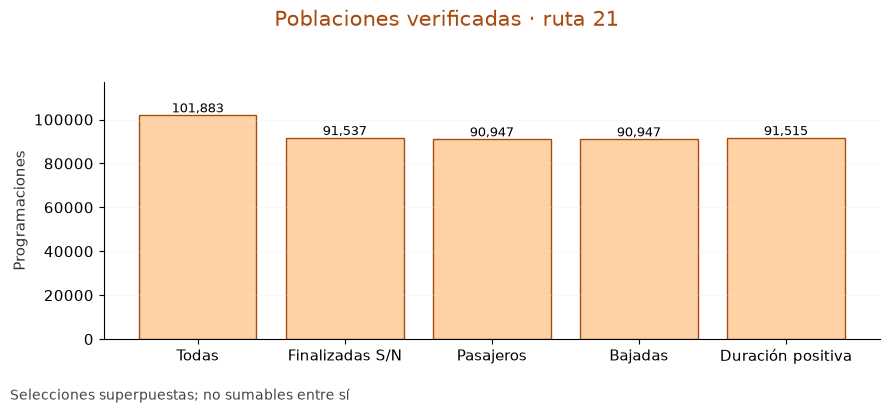

In [3]:
antecedentes={'Programaciones':101883,'Finalizadas S/N':91537,'Selección pasajeros':90947,'Selección bajadas':90947,
 'Ambos conteos ausentes en S/N':590,'Duración seleccionada positiva':91515,'Vehículos':353,'Detalle':494362,
 'Programaciones con detalle':4649,'Celdas anuales 2023–2025':6542,'Celdas anuales 2026':2334,'Franjas por salida':66254}
observados=[len(p9),int(final9.sum()),int(m9['numeropasajeros'].sum()),int(m9['numerobajadas'].sum()),
 int((final9&p9.numeropasajeros.isna()&p9.numerobajadas.isna()).sum()),int(m9['duracion'].sum()),len(v9),len(t9),t9.id_viaje.nunique(),
 int(a9.ano.isin([2023,2024,2025]).sum()),int(a9.ano.eq(2026).sum()),pq.read_metadata(BASE_EDA/'preparadas/conteos_programaciones_por_salida_franja15.parquet').num_rows]
conc9=pd.DataFrame([{'Antecedente':k,'Referencia_ETL':v,'Observado':w,'Coincide':v==w} for (k,v),w in zip(antecedentes.items(),observados)])
tabla(OUT_EDA,'9_1_antecedentes',conc9,n=len(conc9));tabla(OUT_EDA,'9_1_selecciones_ID',pd.DataFrame(CONTROL_EDA),3)
fig,ax=plt.subplots(figsize=(9,4));labels=['Todas','Finalizadas S/N','Pasajeros','Bajadas','Duración positiva']
valores=[len(p9),int(final9.sum()),int(m9['numeropasajeros'].sum()),int(m9['numerobajadas'].sum()),int(m9['duracion'].sum())]
ax.bar(labels,valores,color=CLARO,edgecolor=OSCURO);ax.set_ylabel('Programaciones');ax.grid(axis='y',alpha=.4)
for i,val in enumerate(valores):ax.text(i,val,f'{val:,}',ha='center',va='bottom',fontsize=9)
ax.set_ylim(0,max(valores)*1.15)
figura(OUT_EDA,'9_1_poblaciones',fig,'Poblaciones verificadas · ruta 21','Selecciones superpuestas; no sumables entre sí. Criterios del ETL conservados.')
narrativa(OUT_EDA,'9_1',f'La conciliación de antecedentes tiene {int(conc9.Coincide.sum())}/{len(conc9)} coincidencias. Las tres máscaras aprobadas coinciden fila a fila por identificador con CSV y Parquet del ETL. Hay {int(duracion9.gt(0).sum()):,} duraciones positivas en todas las programaciones, frente a {int(m9["duracion"].sum()):,} bajo S/N: son poblaciones distintas, no un error de conteo.')

**Lectura del resultado.** La conciliación de antecedentes tiene 12/12 coincidencias. Las tres máscaras aprobadas coinciden fila a fila por identificador con CSV y Parquet del ETL. Hay 91,516 duraciones positivas en todas las programaciones, frente a 91,515 bajo S/N: son poblaciones distintas, no un error de conteo.

### **9.2. Clasificación semántica y cobertura real del análisis**
**Pregunta:** ¿qué columnas son medidas, códigos, calendarios o información ajena a las preguntas? Se inventarían todas las columnas extraídas, usando el diccionario y el significado, sin graficar identificadores como continuas ni datos personales, textos libres, credenciales o geometrías. El estado final se actualiza con las salidas realmente producidas.

Tabla,Columna,Tipo_almacenado,Semantica,Estado,Motivo,Unidad_documentada,Codificacion_documentada,Descripcion,Riesgo_fuga,Filas,Presentes,Unicos_presentes,Trabajo_ejecutado
progvehiculos,idprogramacion,int64[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,PK de la programación/viaje (referenciado por id_viaje).,"Nulo — es un identificador, conocido antes del viaje.","101,883","101,883","101,883",pendiente de cotejo con artefactos
progvehiculos,idvehiculo,string[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Vehículo asignado (placa/interno).,Nulo — conocido antes del viaje (parte de la programación).,"101,883","101,883",353,pendiente de cotejo con artefactos
progvehiculos,idconductor,int64[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Conductor asignado.,Nulo — conocido antes del viaje.,"101,883","101,883",756,pendiente de cotejo con artefactos
progvehiculos,idruta,int64[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Ruta del viaje (FK rutas.idruta).,Nulo — conocido antes del viaje.,"101,883","101,883",1,pendiente de cotejo con artefactos
progvehiculos,proceso,string[pyarrow],Categoría/código,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Proceso (sobusa).,Nulo.,"101,883","101,883",1,pendiente de cotejo con artefactos
progvehiculos,fechasalida,timestamp[us][pyarrow],Temporal; significado según fuente,Análisis principal,Población y filtro declarados en el bloque,pendiente de confirmación,No especificada en el diccionario,Fecha/hora programada de salida.,"Nulo — es programación, conocida con anticipación. Es la columna de tiempo natural para ordenar los viajes (útil como columna_orden en el mini-EDA).","101,883","101,883","100,553",pendiente de cotejo con artefactos
progvehiculos,fecharegistro,timestamp[us][pyarrow],Temporal; significado según fuente,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Fecha/hora de registro de la programación.,Nulo — es anterior o igual al viaje en sí.,"101,883","101,883","101,883",pendiente de cotejo con artefactos
progvehiculos,fechainicio,timestamp[us][pyarrow],Temporal; significado según fuente,Análisis principal,Población y filtro declarados en el bloque,pendiente de confirmación,No especificada en el diccionario,Inicio efectivo del viaje.,ALTO — solo se conoce una vez el viaje ya inició. No usar para predecir ese mismo viaje; sí es válida como dato histórico de viajes ya ocurridos.,"101,883","101,054","101,019",pendiente de cotejo con artefactos


Vista: 8 de 183 filas. Detalle completo: tablas/9_2_inventario_semantico.csv


Estado,Semantica,Columnas
Análisis principal,Año/categoría ordenada; no magnitud continua,1
Análisis principal,Categoría/código,3
Análisis principal,Medida/conteo documentado,13
Análisis principal,Temporal; significado según fuente,4
Exclusión justificada,Año/categoría ordenada; no magnitud continua,1
Exclusión justificada,Categoría/código,71
Exclusión justificada,Geometría; sin distribución de valores,2
Exclusión justificada,Identificador; no medida continua,45
Exclusión justificada,Temporal; significado según fuente,16
Interpretación pendiente,Medida con interpretación pendiente,7


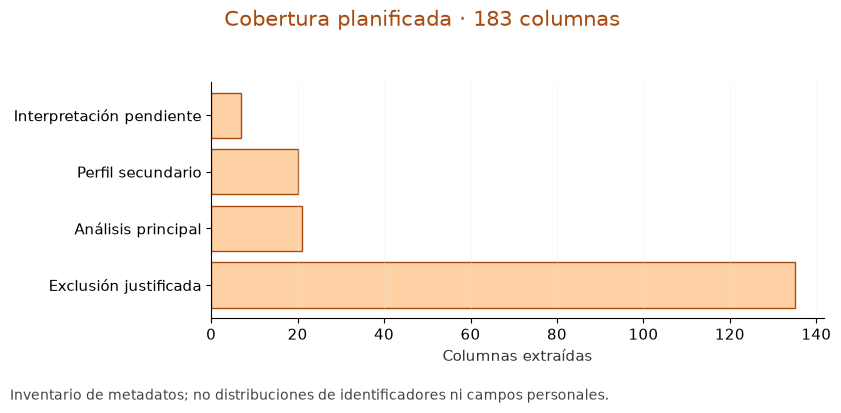

In [4]:
principal9={'progvehiculos':{'numeropasajeros','numerobajadas','numerobloqueos','finalizado','cancelada','activa','fechasalida','fechainicio','fechafin'},
 'timbradas_segmentos':{'subidas','bajadas','fecha'},'vehiculos':{'capacidad','n_sentados','n_depie'},
 'timbradas_anio':{'subidas','bajadas','nro_viajes','promedio_subidas','promedio_bajadas','ano'}}
secundarias9={'cantidad_subida_puerta1','cantidad_subida_puerta2','cantidad_bajada_puerta1','cantidad_bajada_puerta2',
 'marca','modelo','tipo_carroceria','estado','tipo','grupo','excepcion','modificado_manual','viaje_culminado','apto_estadisticas_historicas'}
pendientes9={'distancia_recorrida','distancia_global','pasajeros','acumulada_subida','acumulada_bajada','torniqueteinicial','torniquetefinal'}
d_etl9=pd.read_csv(BASE_EDA/'reportes/diccionario_variables.csv')
unidades9={(row.tabla,row.variable_original):row.unidad for row in d_etl9.itertuples()}
inventario9=[]
for t,df in DAT_EDA.items():
    for c in df:
        d=DOC.get(t,{}).get(c,{})
        sem='Medida/conteo documentado' if c in principal9.get(t,set()) and 'fecha' not in c and c not in ['finalizado','cancelada','activa','ano'] else 'Categoría/código'
        if c.startswith('id') or c=='placa':sem='Identificador; no medida continua'
        elif 'fecha' in c or c.startswith('hora'):sem='Temporal; significado según fuente'
        elif c in ['ano','modelo']:sem='Año/categoría ordenada; no magnitud continua'
        elif c in pendientes9:sem='Medida con interpretación pendiente'
        elif 'geom' in c:sem='Geometría; sin distribución de valores'
        estado='Análisis principal' if c in principal9.get(t,set()) else 'Perfil secundario' if c in secundarias9 else 'Interpretación pendiente' if c in pendientes9 else 'Exclusión justificada'
        motivo='No es necesaria para las preguntas; identificación, administración o configuración' if estado=='Exclusión justificada' else 'Población y filtro declarados en el bloque'
        if t=='timbradas_consolidado' and c in ['subidas','bajadas','nro_viajes','promedio_subidas','promedio_bajadas']:estado='Perfil secundario';motivo='Período y aditividad no confirmados; perfiles de celdas'
        inventario9.append({'Tabla':t,'Columna':c,'Tipo_almacenado':str(df[c].dtype),'Semantica':sem,'Estado':estado,'Motivo':motivo,
            'Unidad_documentada':unidades9.get((t,c),'pendiente de confirmación'),'Codificacion_documentada':d.get('codificacion','pendiente de confirmación'),'Descripcion':d.get('descripcion','pendiente de confirmación'),
            'Riesgo_fuga':d.get('riesgo_leakage','pendiente de confirmación'),'Filas':len(df),'Presentes':int(df[c].notna().sum()),'Unicos_presentes':df[c].nunique(),'Trabajo_ejecutado':'pendiente de cotejo con artefactos'})
INVENTARIO9=pd.DataFrame(inventario9)
tabla(OUT_EDA,'9_2_inventario_semantico',INVENTARIO9,n=8)
res=INVENTARIO9.groupby(['Estado','Semantica']).size().rename('Columnas').reset_index()
tabla(OUT_EDA,'9_2_cobertura_semantica',res,n=len(res))
fig,ax=plt.subplots(figsize=(8.5,4));g=INVENTARIO9.Estado.value_counts()
ax.barh(g.index,g.values,color=CLARO,edgecolor=OSCURO);ax.set_xlabel('Columnas extraídas');ax.grid(axis='x',alpha=.4)
figura(OUT_EDA,'9_2_semantica',fig,f'Cobertura planificada · {len(INVENTARIO9)} columnas','Inventario de metadatos; no distribuciones de identificadores ni campos personales.')
narrativa(OUT_EDA,'9_2','La cobertura se define por significado y utilidad. El inventario permite ver qué campos quedan fuera y por qué; no presenta códigos numéricos como cantidades. En 9.7 se diferencia el trabajo ejecutado de las exclusiones y pendientes.')

**Lectura del resultado.** La cobertura se define por significado y utilidad. El inventario permite ver qué campos quedan fuera y por qué; no presenta códigos numéricos como cantidades. En 9.7 se diferencia el trabajo ejecutado de las exclusiones y pendientes.

### **9.3. Variables numéricas**
**Estadísticas principales:** valores presentes y finitos dentro de cada población declarada. Se conservan ceros y extremos. DE es muestral (ddof=1); cercas Q1−1,5×IQR y Q3+1,5×IQR describen posiciones, no errores. Si IQR=0, no se etiquetan automáticamente los valores distintos. Los cálculos auxiliares usan float64, sin modificar tipos ni valores Arrow originales. Cada gráfico declara si amplía una región y cuánto queda fuera; las estadísticas nunca se recortan.

#### **9.3.1. ¿Cómo se distribuyen pasajeros registrados?**

Unidad: una programación. Población: finalizado S, cancelada N, campo presente y no negativo; selección independiente. Para bloqueos se aplica esta selección descriptiva específica sin alterar los criterios ETL. No se excluyen valores mayores de 500.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"101,883.00",Min,0.00
Seleccionadas criterio,"90,947.00",Max,747.00
N utilizado,"90,947.00",Q1,54.00
Fuera criterio,"10,936.00",Q3,108.00
Faltantes universo,"1,736.00",P5,20.00
No finitos universo,0.00,P95,148.00
Faltantes seleccion,0.00,IQR,54.00
No finitos seleccion,0.00,Asimetria muestral,0.26
Ceros,"1,907.00",Limite IQR inferior,-27.00
Negativos,0.00,Limite IQR superior,189.00


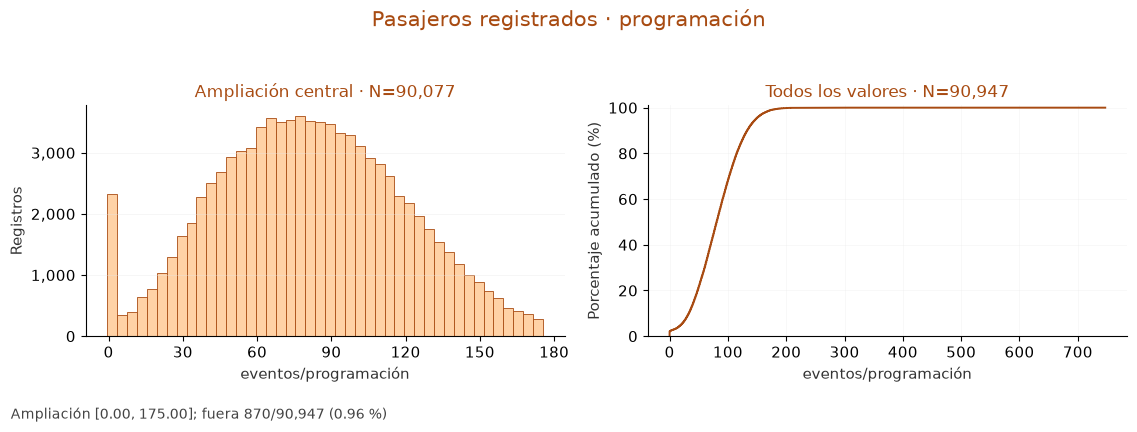

In [5]:
r_numeropasajeros=numerica(OUT_EDA,'9_3_numeropasajeros',p9['numeropasajeros'],m9['numeropasajeros'],'Pasajeros registrados · programación','eventos/programación',identificadores=p9.idprogramacion,nota='Resultado histórico; no ocupación ni predictor disponible antes del despacho.')

**Lectura del resultado.** El conteo típico se sitúa alrededor de 81 eventos por programación; la media cercana a la mediana no elimina la variación individual. Los ceros (2.10 %) se conservan como valores registrados. Las posiciones IQR y el máximo se exportan para revisión sin excluirlos ni interpretar el total acumulado como ocupación.

#### **9.3.2. ¿Cómo se distribuyen bajadas registradas?**

Unidad: una programación. Población: finalizado S, cancelada N, campo presente y no negativo; selección independiente. Para bloqueos se aplica esta selección descriptiva específica sin alterar los criterios ETL. No se excluyen valores mayores de 500.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"101,883.00",Min,0.00
Seleccionadas criterio,"90,947.00",Max,"1,107,795.00"
N utilizado,"90,947.00",Q1,55.00
Fuera criterio,"10,936.00",Q3,107.00
Faltantes universo,"1,736.00",P5,23.00
No finitos universo,0.00,P95,145.00
Faltantes seleccion,0.00,IQR,52.00
No finitos seleccion,0.00,Asimetria muestral,137.84
Ceros,"1,801.00",Limite IQR inferior,-23.00
Negativos,0.00,Limite IQR superior,185.00


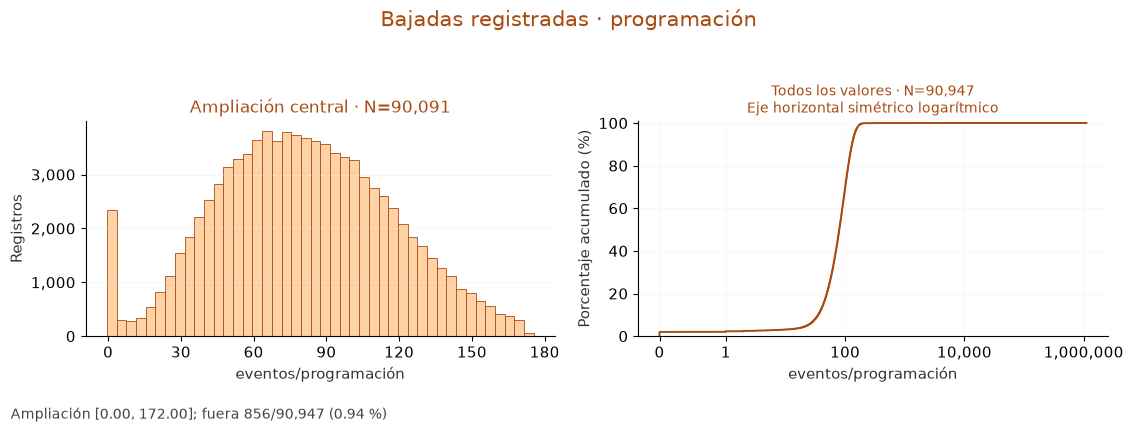

In [6]:
r_numerobajadas=numerica(OUT_EDA,'9_3_numerobajadas',p9['numerobajadas'],m9['numerobajadas'],'Bajadas registradas · programación','eventos/programación',identificadores=p9.idprogramacion,nota='Resultado histórico; no ocupación ni predictor disponible antes del despacho.')

**Lectura del resultado.** El centro de la distribución es parecido al de pasajeros, pero la media (130.22) supera claramente a la mediana (80). El extremo de 1,107,795 influye en sumas y asociaciones lineales: permanece en el análisis principal y tiene identificador de revisión. No se inventa una causa ni se convierte en una regla de limpieza.

#### **9.3.3. ¿Cómo se distribuyen bloqueos de puerta registrados?**

Unidad: una programación. Población: finalizado S, cancelada N, campo presente y no negativo; selección independiente. Para bloqueos se aplica esta selección descriptiva específica sin alterar los criterios ETL. No se excluyen valores mayores de 500.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"101,883.00",Min,0.00
Seleccionadas criterio,"90,947.00",Max,"339,571.00"
N utilizado,"90,947.00",Q1,0.00
Fuera criterio,"10,936.00",Q3,1.00
Faltantes universo,"1,736.00",P5,0.00
No finitos universo,0.00,P95,52.00
Faltantes seleccion,0.00,IQR,1.00
No finitos seleccion,0.00,Asimetria muestral,259.05
Ceros,"67,745.00",Limite IQR inferior,-1.50
Negativos,0.00,Limite IQR superior,2.50


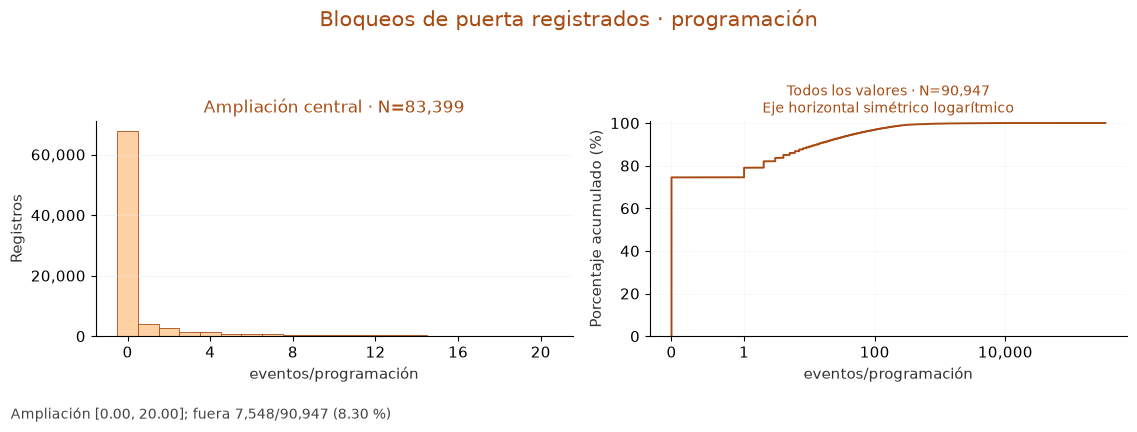

In [7]:
r_numerobloqueos=numerica(OUT_EDA,'9_3_numerobloqueos',p9['numerobloqueos'],m9['numerobloqueos'],'Bloqueos de puerta registrados · programación','eventos/programación',identificadores=p9.idprogramacion,nota='Resultado histórico; no ocupación ni predictor disponible antes del despacho.')

**Lectura del resultado.** Los ceros representan el 74.49 % de los registros seleccionados. La media se aleja de la experiencia de la mayoría por una cola marcada, por lo que conviene acompañarla de mediana y cuantiles. Este campo cuenta bloqueos registrados; no valida el funcionamiento de sensores ni acredita calidad operativa.

In [8]:
# Comprobación original fuera de selecciones: faltantes, ceros, negativos y extremos.
original_counts=[]
for c in ['numeropasajeros','numerobajadas','numerobloqueos']:
    z,x=estadisticas(p9[c]);z['Variable']=c;original_counts.append(z)
    ids=x.nlargest(5).index
    q=p9.loc[ids,['idprogramacion','fechasalida','finalizado','cancelada',c]].copy()
    tabla(OUT_EDA,'9_3_extremos_originales_'+c,q,n=len(q))
tabla(OUT_EDA,'9_3_conteos_originales_todos',pd.DataFrame(original_counts),3)
narrativa(OUT_EDA,'9_3_originales','Los extremos originales se muestran con sus estados y salida para reconocer si pertenecen a la selección principal. La diferencia entre todo el archivo y S/N no autoriza eliminar o reinterpretar una cancelación. Los registros de revisión se exportan, sin imputación ni cambios en RAW.')

idprogramacion,fechasalida,finalizado,cancelada,numeropasajeros
"6,330,910",2024-07-09 09:36:00,S,N,747
"6,332,504",2024-07-09 19:56:00,S,N,459
"6,754,658",2025-01-16 08:20:00,S,N,398
"6,565,196",2024-10-22 09:10:00,S,N,350
"6,506,544",2024-09-25 10:44:00,S,N,307


idprogramacion,fechasalida,finalizado,cancelada,numerobajadas
"5,446,141",2023-06-23 08:00:00,S,N,"1,107,795"
"6,405,492",2024-08-10 16:24:00,N,S,"845,577"
"5,938,923",2024-01-21 14:24:00,N,S,"782,067"
"5,457,377",2023-06-28 10:04:00,S,N,"716,522"
"5,447,203",2023-06-23 14:00:00,S,N,"714,950"


idprogramacion,fechasalida,finalizado,cancelada,numerobloqueos
"5,708,605",2023-10-12 15:12:00,S,N,"339,571"
"6,918,638",2025-03-28 12:18:00,S,N,"77,589"
"6,212,338",2024-05-17 08:30:00,S,N,"65,150"
"7,322,444",2025-09-21 10:12:00,S,N,"38,042"
"7,210,123",2025-08-01 17:16:00,S,N,"12,243"


Variable,Universo,N_utilizado,Faltantes_universo,No_finitos_seleccion,Ceros,Negativos,Media,Mediana,Max
numeropasajeros,"101,883","100,147","1,736",0,"2,524",0,80.64,80.00,747.00
numerobajadas,"101,883","100,147","1,736",0,"3,070",0,140.42,79.00,"1,107,795.00"
numerobloqueos,"101,883","100,147","1,736",0,"74,822",0,22.08,0.00,"339,571.00"


**Lectura del resultado.** Los extremos originales se muestran con sus estados y salida para reconocer si pertenecen a la selección principal. La diferencia entre todo el archivo y S/N no autoriza eliminar o reinterpretar una cancelación. Los registros de revisión se exportan, sin imputación ni cambios en RAW.

#### **9.3.4. Duración registrada y extremos temporales**

Unidad: programación. Selección aprobada de duración positiva en S/N. Inicio–fin se expresa en minutos, pero no se confirma como recorrido, ciclo o turno. Se conservan valores largos.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"101,883.00",Min,0.02
Seleccionadas criterio,"91,515.00",Max,"59,680.40"
N utilizado,"91,515.00",Q1,199.40
Fuera criterio,"10,368.00",Q3,264.00
Faltantes universo,"10,345.00",P5,105.00
No finitos universo,0.00,P95,320.98
Faltantes seleccion,0.00,IQR,64.60
No finitos seleccion,0.00,Asimetria muestral,71.23
Ceros,0.00,Limite IQR inferior,102.50
Negativos,0.00,Limite IQR superior,360.90


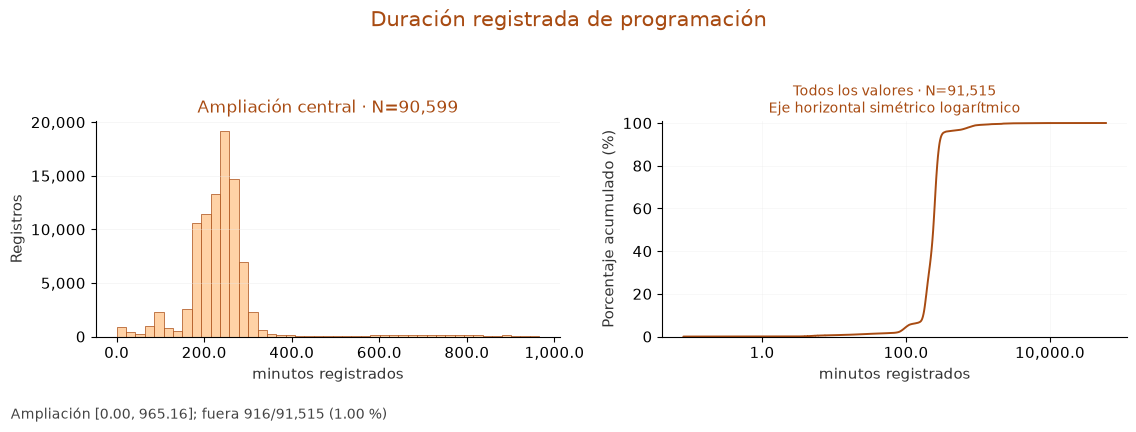

In [9]:
r_duracion=numerica(OUT_EDA,'9_3_duracion',duracion9,m9['duracion'],'Duración registrada de programación','minutos registrados',discreta=False,identificadores=p9.idprogramacion,nota='Inicio–fin no acredita unidad operativa de recorrido o ciclo.')

**Lectura del resultado.** La duración típica ronda 238.3 minutos registrados, pero hay una cola extensa que se conserva en la vista completa y en la desviación muestral. La positividad bajo S/N no demuestra que inicio y fin delimiten un recorrido o ciclo. Los registros largos deben revisarse por su identificador y contexto temporal, sin adoptar 60–480 minutos como validez.

In [10]:
ext=p9.loc[duracion9.nlargest(10).index,['idprogramacion','fechasalida','fechainicio','fechafin','finalizado','cancelada']].copy()
ext['duracion_min']=duracion9.loc[ext.index]
fuera_tiempo9=(inicio9.lt(pd.Timestamp('2023-01-01'))|inicio9.ge(pd.Timestamp('2026-01-01'))|fin9.lt(pd.Timestamp('2023-01-01'))|fin9.ge(pd.Timestamp('2026-01-01'))).fillna(False)
ext['alguna_fecha_fuera_ventana']=fuera_tiempo9.loc[ext.index]
tabla(OUT_EDA,'9_3_extremos_duracion',ext,10)
res_dur=pd.DataFrame([{'Universo':'Todas las programaciones','Fechas_ausentes':int((inicio9.isna()|fin9.isna()).sum()),'Negativas':int(duracion9.lt(0).sum()),'Cero':int(duracion9.eq(0).sum()),'Positivas':int(duracion9.gt(0).sum()),'Alguna_fecha_fuera_ventana':int(fuera_tiempo9.sum()),'Denominador':len(p9)}])
tabla(OUT_EDA,'9_3_diagnostico_tiempo',res_dur,1)
q=p9.loc[fuera_tiempo9,['idprogramacion','fechasalida','fechainicio','fechafin','finalizado','cancelada']]
q.to_parquet(OUT_EDA/'incidencias/fechas_fuera_ventana.parquet',index=False)
comparacion_tiempo=[]
for nombre,mask in [('Selección principal',m9['duracion']),('Sensibilidad: inicio y fin dentro de ventana',m9['duracion']&~fuera_tiempo9)]:
    z,_=estadisticas(duracion9,mask);z['Poblacion']=nombre;comparacion_tiempo.append(z)
tabla(OUT_EDA,'9_3_sensibilidad_cierre',pd.DataFrame(comparacion_tiempo),2)
narrativa(OUT_EDA,'9_3_tiempo_ext',f'Hay {int(fuera_tiempo9.sum()):,} programaciones con alguna fecha efectiva fuera de la ventana definida por salida. La sensibilidad temporal aparta {int((m9["duracion"]&fuera_tiempo9).sum()):,} de la selección principal únicamente para comparar; no las invalida ni modifica el criterio aprobado. Los registros largos necesitan confirmar qué eventos marcan inicio y fin.')

idprogramacion,fechasalida,fechainicio,fechafin,finalizado,cancelada,duracion_min,alguna_fecha_fuera_ventana
"5,535,665",2023-08-01 08:00:00,2023-08-01 17:50:53,2023-09-12 04:31:17,S,N,"59,680.40",False
"6,648,407",2024-11-28 05:51:00,2024-12-07 07:54:02,2025-01-12 09:09:58,S,N,"51,915.93",False
"7,519,066",2025-12-18 05:00:00,2025-12-18 11:56:02,2026-01-08 08:21:51,S,N,"30,025.82",True
"7,545,871",2025-12-30 15:35:00,2025-12-30 15:34:13,2026-01-14 12:11:33,S,N,"21,397.33",True
"7,410,346",2025-10-30 05:34:00,2025-10-30 05:59:41,2025-11-11 16:07:48,S,N,"17,888.12",False
"7,511,906",2025-12-15 05:17:00,2025-12-15 09:29:08,2025-12-27 08:53:00,S,N,"17,243.87",False
"5,610,062",2023-09-01 15:08:00,2023-09-01 15:07:59,2023-09-13 14:09:20,S,N,"17,221.35",False
"6,214,206",2024-05-18 04:50:00,2024-05-23 14:45:06,2024-06-04 08:38:26,S,N,"16,913.33",False
"5,174,038",2023-02-23 04:30:00,2023-02-23 04:30:40,2023-03-06 18:20:26,S,N,"16,669.77",False
"5,939,181",2024-01-22 05:41:00,2024-01-22 06:01:09,2024-02-01 10:33:16,S,N,"14,672.12",False


Universo,Fechas_ausentes,Negativas,Cero,Positivas,Alguna_fecha_fuera_ventana,Denominador
Todas las programaciones,"10,345",21,1,"91,516",12,"101,883"


Poblacion,Universo,N_utilizado,Faltantes_universo,No_finitos_seleccion,Ceros,Negativos,Media,Mediana,Max
Selección principal,"101,883","91,515","10,345",0,0,0,260.11,238.30,"59,680.40"
Sensibilidad: inicio y fin dentro de ventana,"101,883","91,507","10,345",0,0,0,259.44,238.30,"59,680.40"


**Lectura del resultado.** Hay 12 programaciones con alguna fecha efectiva fuera de la ventana definida por salida. La sensibilidad temporal aparta 8 de la selección principal únicamente para comparar; no las invalida ni modifica el criterio aprobado. Los registros largos necesitan confirmar qué eventos marcan inicio y fin.

#### **9.3.5. ¿Cuánto difieren inicio y salida programada?**

Unidad: programación S/N con ambos campos presentes; el signo positivo indica inicio posterior a la salida programada. Se conservan desfases negativos, cero y positivos, sin exigir igualdad.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"101,883.00",Min,-11.07
Seleccionadas criterio,"91,537.00",Max,"83,832.63"
N utilizado,"91,537.00",Q1,0.10
Fuera criterio,"10,346.00",Q3,2.97
Faltantes universo,829.00,P5,-0.90
No finitos universo,0.00,P95,11.13
Faltantes seleccion,0.00,IQR,2.87
No finitos seleccion,0.00,Asimetria muestral,171.82
Ceros,229.00,Limite IQR inferior,-4.20
Negativos,"21,564.00",Limite IQR superior,7.27


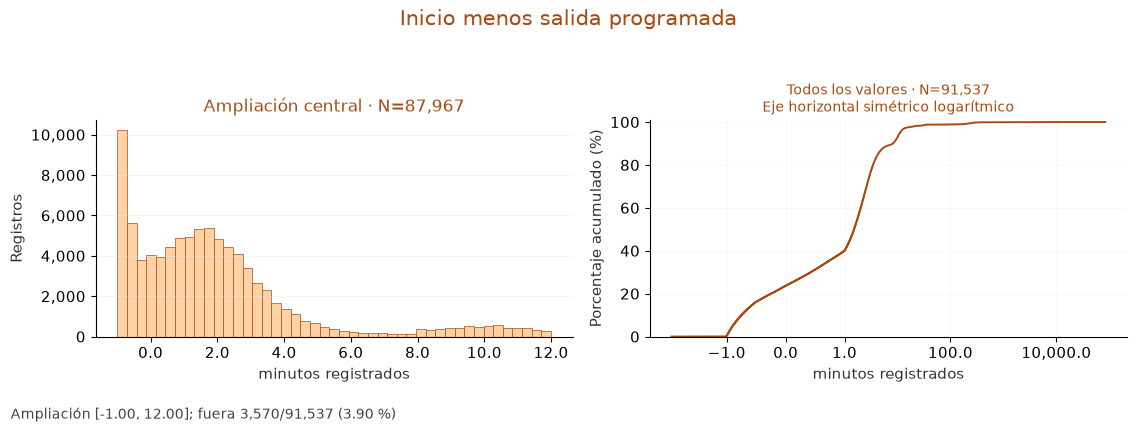

In [11]:
r_desfase=numerica(OUT_EDA,'9_3_desfase',desfase9,final9&inicio9.notna()&salida9.notna(),'Inicio menos salida programada','minutos registrados',discreta=False,centro=(-1,12),identificadores=p9.idprogramacion,nota='No se interpreta automáticamente como retraso real de despacho.')

**Lectura del resultado.** La mediana es positiva (1.52 minutos), mientras el 23.56 % de los desfases es negativo. La ampliación cercana a cero permite leer ambos signos sin perder la cola de la vista completa. No se interpreta automáticamente esta diferencia de marcas como retraso o anticipación real de despacho.

#### **9.3.6. Detalle por segmento: su propio nivel y cobertura**

Una fila es un registro segmento–programación, entre las fechas observadas del detalle. Se usan todos los valores presentes y finitos; se conservan negativos y no se hereda S/N de programación. `pasajeros` se describe como campo registrado con interpretación pendiente, no como ocupación habilitada.

**Detalle: subidas**

Población: todos los registros de detalle disponibles. Unidad: registro segmento–programación. La fuente mantiene su ventana de enero–febrero de 2023.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"494,362.00",Min,0.00
Seleccionadas criterio,"494,362.00",Max,63.00
N utilizado,"494,362.00",Q1,0.00
Fuera criterio,0.00,Q3,1.00
Faltantes universo,0.00,P5,0.00
No finitos universo,0.00,P95,4.00
Faltantes seleccion,0.00,IQR,1.00
No finitos seleccion,0.00,Asimetria muestral,3.49
Ceros,"314,897.00",Limite IQR inferior,-1.50
Negativos,0.00,Limite IQR superior,2.50


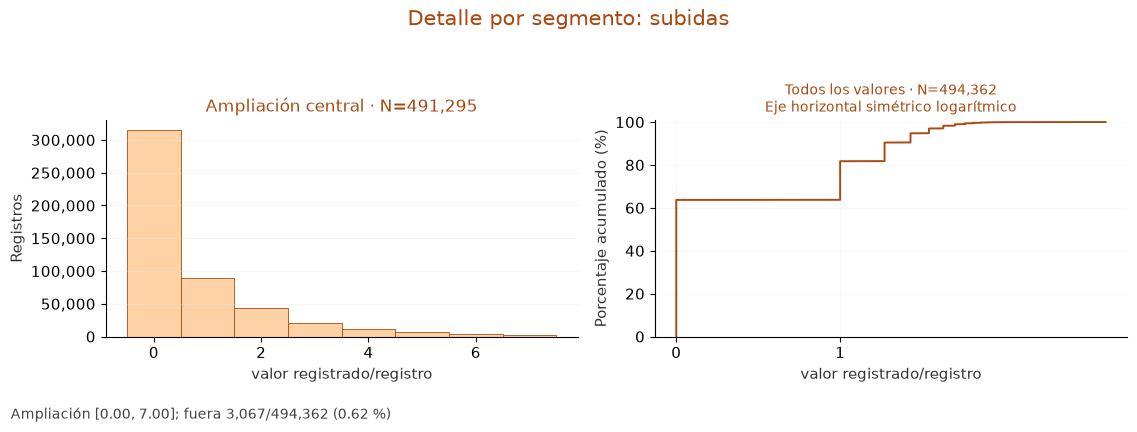

In [12]:
rd_subidas=numerica(OUT_EDA,'9_3_detalle_subidas',t9['subidas'],None,'Detalle por segmento: subidas','valor registrado/registro',identificadores=t9.id_timbrada_segmento,nota='Sin filtros heredados; pasajeros no habilitado como ocupación.')

**Lectura del resultado.** El 63.70 % de registros tiene cero en subidas. La mediana nula y la concentración de eventos en parte de los registros explican que la media aporte información distinta; cero no prueba falta de medición ni fallo. Esta distribución pertenece al registro segmento–programación y a la ventana observada, no a todo 2023–2025.

**Detalle: bajadas**

Población: todos los registros de detalle disponibles. Unidad: registro segmento–programación. La fuente mantiene su ventana de enero–febrero de 2023.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"494,362.00",Min,0.00
Seleccionadas criterio,"494,362.00",Max,136.00
N utilizado,"494,362.00",Q1,0.00
Fuera criterio,0.00,Q3,1.00
Faltantes universo,0.00,P5,0.00
No finitos universo,0.00,P95,3.00
Faltantes seleccion,0.00,IQR,1.00
No finitos seleccion,0.00,Asimetria muestral,7.12
Ceros,"307,617.00",Limite IQR inferior,-1.50
Negativos,0.00,Limite IQR superior,2.50


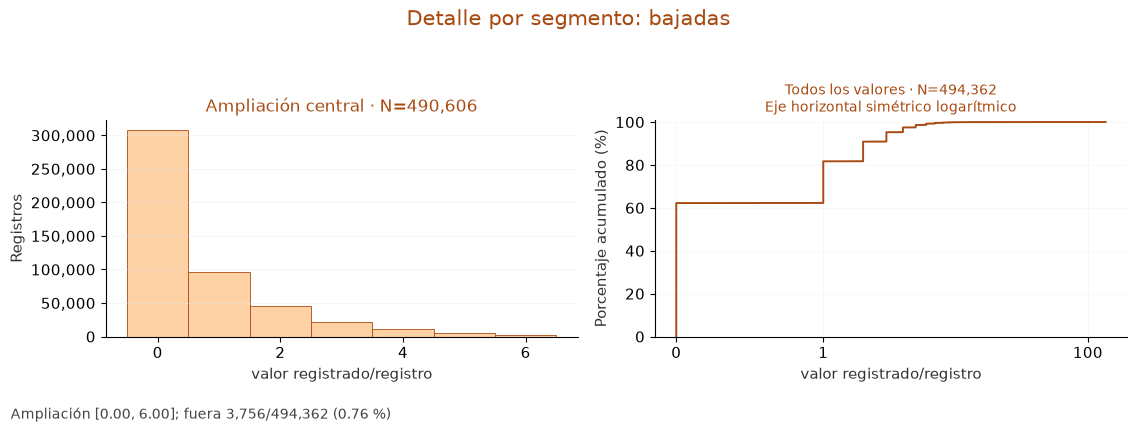

In [13]:
rd_bajadas=numerica(OUT_EDA,'9_3_detalle_bajadas',t9['bajadas'],None,'Detalle por segmento: bajadas','valor registrado/registro',identificadores=t9.id_timbrada_segmento,nota='Sin filtros heredados; pasajeros no habilitado como ocupación.')

**Lectura del resultado.** El 62.23 % de registros tiene cero en bajadas. La mediana nula y la concentración de eventos en parte de los registros explican que la media aporte información distinta; cero no prueba falta de medición ni fallo. Esta distribución pertenece al registro segmento–programación y a la ventana observada, no a todo 2023–2025.

**Detalle: pasajeros**

Población: todos los registros de detalle disponibles. Unidad: registro segmento–programación. La fuente mantiene su ventana de enero–febrero de 2023.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"494,362.00",Min,"-174,440.00"
Seleccionadas criterio,"494,362.00",Max,"64,417.00"
N utilizado,"494,362.00",Q1,-448.00
Fuera criterio,0.00,Q3,"15,006.75"
Faltantes universo,0.00,P5,"-60,218.00"
No finitos universo,0.00,P95,"29,847.00"
Faltantes seleccion,0.00,IQR,"15,454.75"
No finitos seleccion,0.00,Asimetria muestral,-2.72
Ceros,20.00,Limite IQR inferior,"-23,630.12"
Negativos,"137,134.00",Limite IQR superior,"38,188.88"


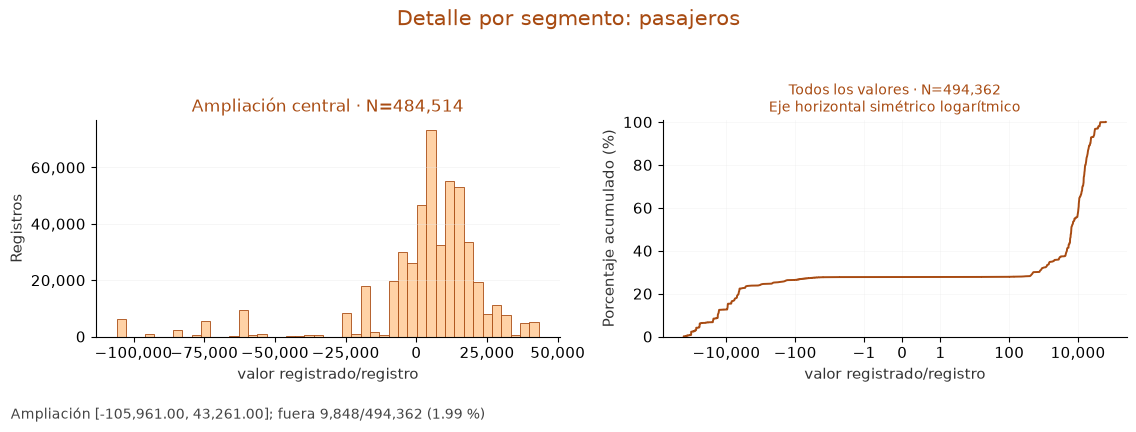

In [14]:
rd_pasajeros=numerica(OUT_EDA,'9_3_detalle_pasajeros',t9['pasajeros'],None,'Detalle por segmento: pasajeros','valor registrado/registro',identificadores=t9.id_timbrada_segmento,nota='Sin filtros heredados; pasajeros no habilitado como ocupación.')

**Lectura del resultado.** El campo contiene negativos en el 27.74 % de los registros y magnitudes elevadas. Se describe tal como está almacenado, pero su lectura como personas presentes a bordo queda pendiente de confirmación y revisión del cálculo. No se usa como ocupación ni se divide por capacidad.

#### **9.3.7. Capacidad y plazas declaradas**

Una fila es una ficha del catálogo extraído, no una programación. Se conservan ceros, faltantes y negativos. Atributos actuales sin vigencia histórica confirmada; no se sustituye capacidad ni se calcula ocupación.

**Atributo declarado: capacidad**

Población: todas las fichas de vehículos referenciados. La unidad y vigencia de capacidad requieren confirmación; plazas son atributos declarados.

In [15]:
rv_capacidad=numerica(OUT_EDA,'9_3_vehiculo_capacidad',v9['capacidad'],None,'Vehículos: capacidad','valor declarado/ficha',identificadores=v9.idvehiculo,nota='No acredita capacidad efectiva ni vigencia histórica.')

Medida,Valor,Medida complementaria,Valor complementario
Universo,353.00,Min,0.00
Seleccionadas criterio,353.00,Max,0.00
N utilizado,353.00,Q1,0.00
Fuera criterio,0.00,Q3,0.00
Faltantes universo,0.00,P5,0.00
No finitos universo,0.00,P95,0.00
Faltantes seleccion,0.00,IQR,0.00
No finitos seleccion,0.00,Asimetria muestral,No evaluable
Ceros,353.00,Limite IQR inferior,No evaluable
Negativos,0.00,Limite IQR superior,No evaluable


**Lectura del resultado.** Las 353 fichas tienen capacidad declarada igual a cero. No existe una capacidad positiva utilizable en esta extracción: la tabla documenta el bloqueo del uso, sin fabricar una distribución ni sustituir el campo por plazas.

**Atributo declarado: n_sentados**

Población: todas las fichas de vehículos referenciados. La unidad y vigencia de capacidad requieren confirmación; plazas son atributos declarados.

Medida,Valor,Medida complementaria,Valor complementario
Universo,353.00,Min,0.00
Seleccionadas criterio,353.00,Max,47.00
N utilizado,353.00,Q1,30.00
Fuera criterio,0.00,Q3,37.00
Faltantes universo,0.00,P5,0.00
No finitos universo,0.00,P95,39.00
Faltantes seleccion,0.00,IQR,7.00
No finitos seleccion,0.00,Asimetria muestral,-1.90
Ceros,35.00,Limite IQR inferior,19.50
Negativos,0.00,Limite IQR superior,47.50


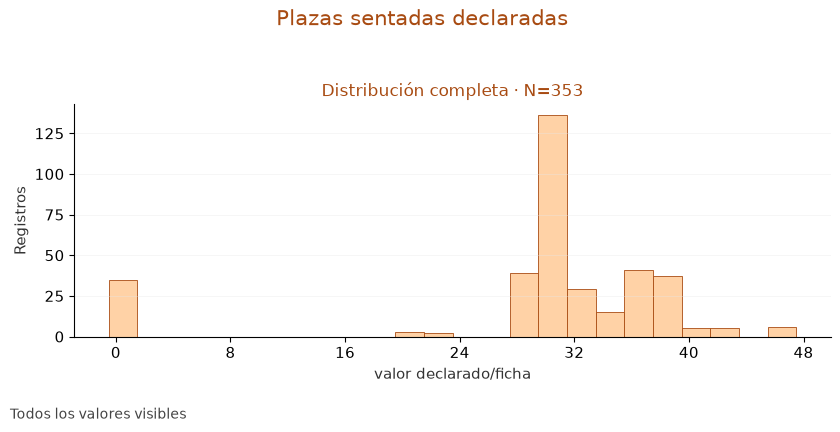

In [16]:
rv_n_sentados=numerica(OUT_EDA,'9_3_vehiculo_n_sentados',v9['n_sentados'],None,'Plazas sentadas declaradas','valor declarado/ficha',identificadores=v9.idvehiculo,nota='No acredita capacidad efectiva ni vigencia histórica.')

**Lectura del resultado.** La mediana declarada es 31, y 35 fichas registran cero. Estos valores describen atributos del catálogo, sin acreditar capacidad efectiva ni vigencia en cada fecha histórica. Se conservan originales y ceros; la suma de plazas no sustituye capacidad.

**Atributo declarado: n_depie**

Población: todas las fichas de vehículos referenciados. La unidad y vigencia de capacidad requieren confirmación; plazas son atributos declarados.

Medida,Valor,Medida complementaria,Valor complementario
Universo,353.00,Min,0.00
Seleccionadas criterio,353.00,Max,34.00
N utilizado,353.00,Q1,15.00
Fuera criterio,0.00,Q3,20.00
Faltantes universo,0.00,P5,0.00
No finitos universo,0.00,P95,22.00
Faltantes seleccion,0.00,IQR,5.00
No finitos seleccion,0.00,Asimetria muestral,-1.33
Ceros,35.00,Limite IQR inferior,7.50
Negativos,0.00,Limite IQR superior,27.50


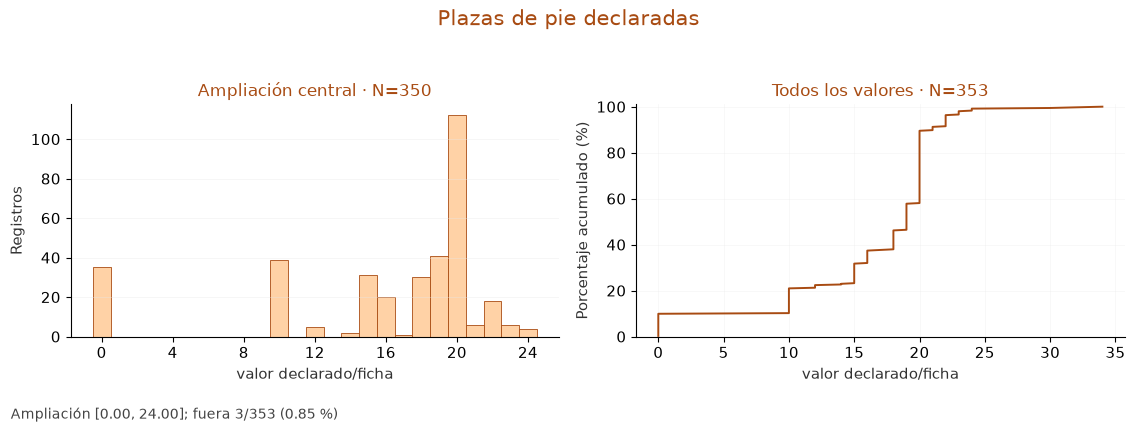

In [17]:
rv_n_depie=numerica(OUT_EDA,'9_3_vehiculo_n_depie',v9['n_depie'],None,'Plazas de pie declaradas','valor declarado/ficha',identificadores=v9.idvehiculo,nota='No acredita capacidad efectiva ni vigencia histórica.')

**Lectura del resultado.** La mediana declarada es 19, y 35 fichas registran cero. Estos valores describen atributos del catálogo, sin acreditar capacidad efectiva ni vigencia en cada fecha histórica. Se conservan originales y ceros; la suma de plazas no sustituye capacidad.

### **9.4. Variables categóricas**

Se conservan códigos originales, faltantes y denominador de filas de cada fuente. S/N procede del diccionario; otros códigos se muestran sin inventar interpretación. No se hacen rankings univariados de identificadores personales o de vehículo.

**Estados registrados: finalizado**

Población: todas las programaciones, sin selección S/N. Los valores son estados registrados; no acreditan calidad operativa.

Categoria,N,Denominador,Porcentaje
S,"91,537","101,883",89.85
N,"10,346","101,883",10.15


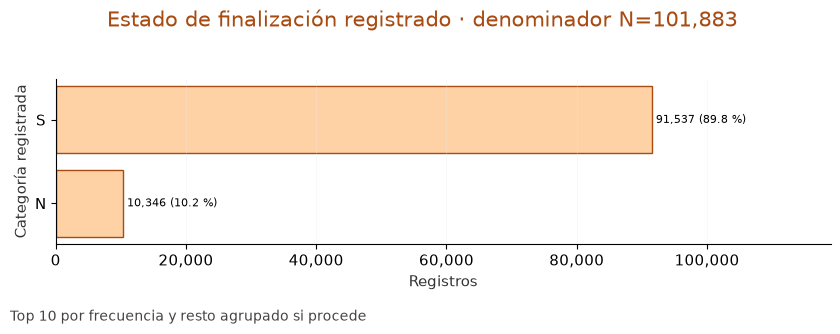

In [18]:
categorica(OUT_EDA,'9_4_finalizado',p9['finalizado'],'Estado de finalización registrado','S/N documentado; estado descriptivo posterior o actual, no predictor previo.')

**Lectura del resultado.** La categoría más frecuente es **S**, con 89.845 % de 101,883 registros. S/N documentado; estado descriptivo posterior o actual, no predictor previo. Las etiquetas desconocidas se conservan sin atribuirles significado.

**Estados registrados: cancelada**

Población: todas las programaciones, sin selección S/N. Los valores son estados registrados; no acreditan calidad operativa.

Categoria,N,Denominador,Porcentaje
N,"91,544","101,883",89.85
S,"10,339","101,883",10.15


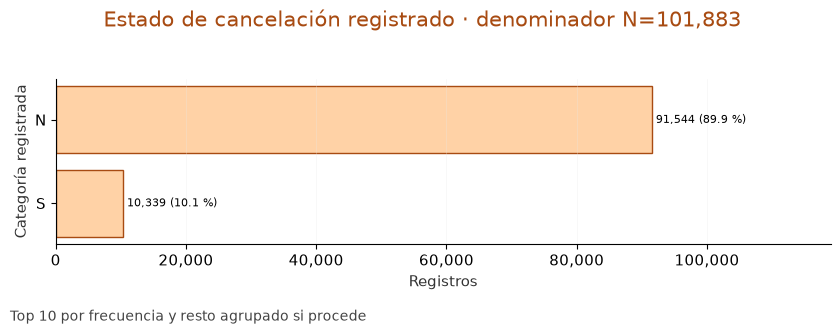

In [19]:
categorica(OUT_EDA,'9_4_cancelada',p9['cancelada'],'Estado de cancelación registrado','S/N documentado; estado descriptivo posterior o actual, no predictor previo.')

**Lectura del resultado.** La categoría más frecuente es **N**, con 89.852 % de 101,883 registros. S/N documentado; estado descriptivo posterior o actual, no predictor previo. Las etiquetas desconocidas se conservan sin atribuirles significado.

**Estados registrados: activa**

Población: todas las programaciones, sin selección S/N. Los valores son estados registrados; no acreditan calidad operativa.

In [20]:
categorica(OUT_EDA,'9_4_activa',p9['activa'],'Programaciones: activa','S/N documentado; estado descriptivo posterior o actual, no predictor previo.')

Categoria,N,Denominador,Porcentaje
N,"101,880","101,883",100.00
S,3,"101,883",0.00


**Lectura del resultado.** La variable es casi constante: solo tres programaciones registran S. Se muestra esa excepción con precisión suficiente, pero no sostiene una comparación operativa ni reconstruye retrospectivamente el estado de cada servicio.

In [21]:
sin_contraste=[]
for c in ['tipo','grupo','excepcion','modificado_manual','viaje_culminado','apto_estadisticas_historicas']:
    g=p9[c].astype('string').fillna('[Ausente]').value_counts()
    sin_contraste.append({'Campo':c,'Denominador':len(p9),'Presentes':int(p9[c].notna().sum()),'Categorias_presentes':p9[c].nunique(),'Valores_observados':'; '.join(f'{k}: {v:,}' for k,v in g.items()),'Grafico':'No: ausencia completa o constancia' if p9[c].nunique()<2 else 'Perfil secundario'})
tabla(OUT_EDA,'9_4_sin_contraste',pd.DataFrame(sin_contraste),len(sin_contraste))
narrativa(OUT_EDA,'9_4_sin_contraste','Los campos sin variación o completamente ausentes se documentan en tabla. No se construyen grupos artificiales ni distribuciones gráficas vacías; tipo y grupo no sostienen comparaciones bivariadas si carecen de valores.')

Campo,Denominador,Presentes,Categorias_presentes,Valores_observados,Grafico
tipo,"101,883",0,0,"[Ausente]: 101,883",No: ausencia completa o constancia
grupo,"101,883",0,0,"[Ausente]: 101,883",No: ausencia completa o constancia
excepcion,"101,883","101,883",1,"N: 101,883",No: ausencia completa o constancia
modificado_manual,"101,883","101,883",1,"False: 101,883",No: ausencia completa o constancia
viaje_culminado,"101,883","101,883",1,"False: 101,883",No: ausencia completa o constancia
apto_estadisticas_historicas,"101,883","101,883",1,"True: 101,883",No: ausencia completa o constancia


**Lectura del resultado.** Los campos sin variación o completamente ausentes se documentan en tabla. No se construyen grupos artificiales ni distribuciones gráficas vacías; tipo y grupo no sostienen comparaciones bivariadas si carecen de valores.

**Perfil del catálogo: estado**

Población: fichas, una por vehículo referenciado. Top 10 por frecuencia más otras cuando procede, con faltantes incluidos. No reconstruye el atributo histórico de cada programación.

Categoria,N,Denominador,Porcentaje
Y,317,353,89.80
N,36,353,10.20


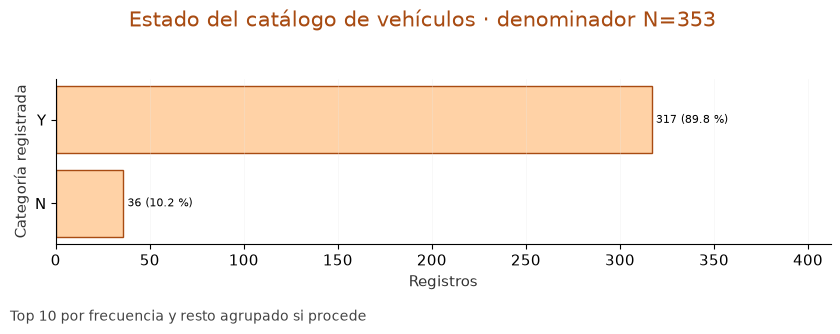

In [22]:
categorica(OUT_EDA,'9_4_ficha_estado',v9['estado'],'Estado del catálogo de vehículos','Atributo del archivo; sin vigencia histórica confirmada.')

**Lectura del resultado.** La categoría más frecuente es **Y**, con 89.802 % de 353 registros. Atributo del archivo; sin vigencia histórica confirmada. Las etiquetas desconocidas se conservan sin atribuirles significado.

**Perfil del catálogo: marca**

Población: fichas, una por vehículo referenciado. Top 10 por frecuencia más otras cuando procede, con faltantes incluidos. No reconstruye el atributo histórico de cada programación.

Categoria,N,Denominador,Porcentaje
CHEVROLET,93,353,26.35
CHEVROLET NPR,67,353,18.98
CHEVROLET NQR,66,353,18.70
[Ausente],43,353,12.18
NQR,28,353,7.93
AGRALE,11,353,3.12
CHEVROLET B70,11,353,3.12
CHEVROLET FRR,5,353,1.42
HINO,4,353,1.13
AGRALES,3,353,0.85


Vista: 10 de 28 filas. Detalle completo: tablas/9_4_ficha_marca_frecuencias.csv


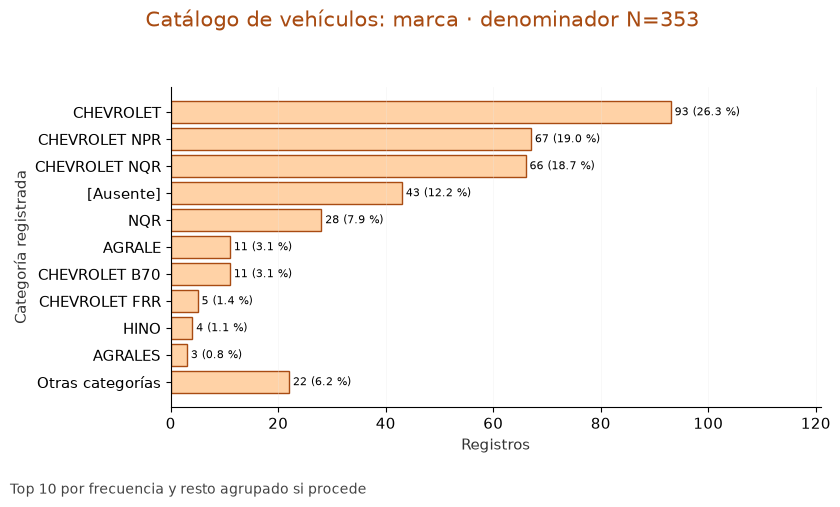

In [23]:
categorica(OUT_EDA,'9_4_ficha_marca',v9['marca'],'Catálogo de vehículos: marca','Atributo del archivo; sin vigencia histórica confirmada.')

**Lectura del resultado.** Las etiquetas del catálogo son heterogéneas, incluidas distintas denominaciones que contienen Chevrolet y fichas sin valor. Se conservan literalmente; no se unifican marcas ni se atribuyen efectos a una categoría de fabricante. El top por frecuencia y otras resume sin perder la tabla completa.

**Perfil del catálogo: modelo**

Población: fichas, una por vehículo referenciado. Top 10 por frecuencia más otras cuando procede, con faltantes incluidos. No reconstruye el atributo histórico de cada programación.

Categoria,N,Denominador,Porcentaje
[Ausente],85,353,24.08
2016,48,353,13.60
2020,42,353,11.90
2011,24,353,6.80
2010,22,353,6.23
2018,21,353,5.95
2019,17,353,4.82
2008,15,353,4.25
2017,14,353,3.97
2022,12,353,3.40


Vista: 10 de 25 filas. Detalle completo: tablas/9_4_ficha_modelo_frecuencias.csv


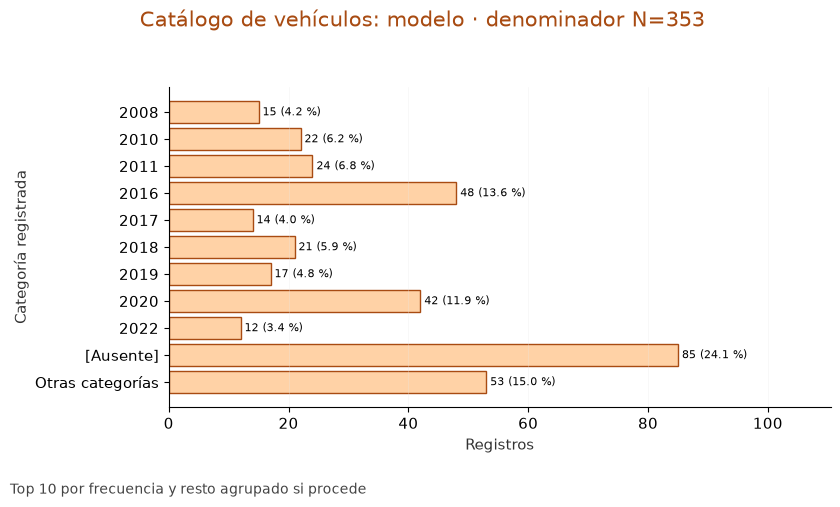

In [24]:
categorica(OUT_EDA,'9_4_ficha_modelo',v9['modelo'],'Catálogo de vehículos: modelo','Atributo del archivo; sin vigencia histórica confirmada.',ordenar_anios=True)

**Lectura del resultado.** Las ausencias alcanzan 85 de 353 fichas. Los códigos/años mostrados se ordenan cronológicamente, pero siguen siendo categorías del catálogo extraído: no se calcula una antigüedad histórica ni se presupone disponibilidad uniforme del atributo.

**Perfil del catálogo: tipo_carroceria**

Población: fichas, una por vehículo referenciado. Top 10 por frecuencia más otras cuando procede, con faltantes incluidos. No reconstruye el atributo histórico de cada programación.

In [25]:
categorica(OUT_EDA,'9_4_ficha_tipo_carroceria',v9['tipo_carroceria'],'Catálogo de vehículos: tipo_carroceria','Atributo del archivo; sin vigencia histórica confirmada.')

Categoria,N,Denominador,Porcentaje
[Ausente],353,353,100.00


**Lectura del resultado.** La variable es completamente ausente; no ofrece contraste distributivo. Atributo del archivo; sin vigencia histórica confirmada.

### **9.5. Variables temporales**
**Pregunta:** ¿cuándo hay registros y cuántas programaciones se observan? Las frecuencias cuentan filas, no pasajeros. Se ordenan años, meses, días y horas por calendario. No se rellenan automáticamente fechas ausentes con ceros. Los índices Python 0–6 se vinculan con nombres y luego con el catálogo SQL, sin asumir que sus códigos son iguales.

Indice_Python,Nombre,id_dia_semana
0,Lunes,1
1,Martes,2
2,Miércoles,3
3,Jueves,4
4,Viernes,5
5,Sábado,6
6,Domingo,7


mes,N,Denominador,Porcentaje
2023-01,"2,952","101,883",2.90
2023-02,"2,578","101,883",2.53
2023-03,"2,996","101,883",2.94
2023-04,"2,703","101,883",2.65
2023-05,"2,873","101,883",2.82
2023-06,"2,779","101,883",2.73
2023-07,"3,118","101,883",3.06
2023-08,"2,882","101,883",2.83


Vista: 8 de 36 filas. Detalle completo: tablas/9_5_mes.csv


dia,N,Denominador,Porcentaje
0,"14,045","101,883",13.79
1,"15,569","101,883",15.28
2,"15,735","101,883",15.44
3,"15,541","101,883",15.25
4,"15,474","101,883",15.19
5,"15,226","101,883",14.94
6,"10,293","101,883",10.10


hora,N,Denominador,Porcentaje
3,1,"101,883",0.00
4,"2,838","101,883",2.79
5,"15,132","101,883",14.85
6,"7,240","101,883",7.11
7,"6,567","101,883",6.45
8,"5,828","101,883",5.72
9,"5,749","101,883",5.64
10,"5,535","101,883",5.43


Vista: 8 de 18 filas. Detalle completo: tablas/9_5_hora.csv


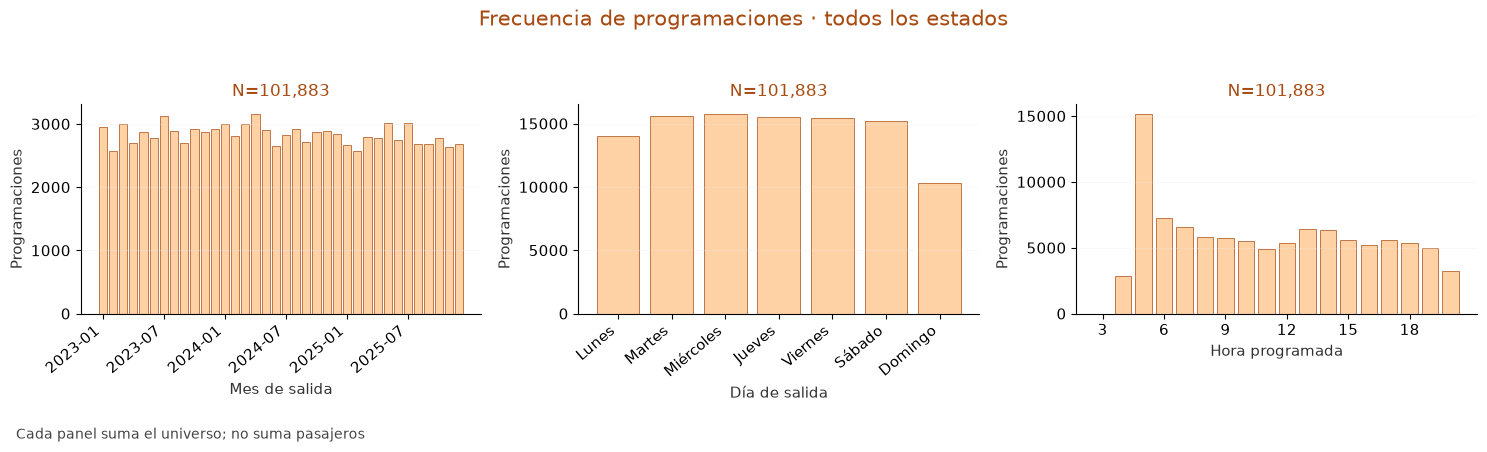

In [26]:
ORDEN_DIAS9=['Lunes','Martes','Miércoles','Jueves','Viernes','Sábado','Domingo']
assert cat_dias9.dia_semana.is_unique and set(cat_dias9.dia_semana)==set(ORDEN_DIAS9)
p9['dia']=salida9.dt.dayofweek;p9['hora']=salida9.dt.hour;p9['anio']=salida9.dt.year;p9['mes']=salida9.dt.strftime('%Y-%m')
map_dias=pd.DataFrame({'Indice_Python':range(7),'Nombre':ORDEN_DIAS9})
map_dias=map_dias.merge(cat_dias9.rename(columns={'dia_semana':'Nombre'}).astype({'Nombre':'string'}),on='Nombre',validate='one_to_one')
tabla(OUT_EDA,'9_5_mapa_dias',map_dias,7)
fig,axes=plt.subplots(1,3,figsize=(15,4.4))
for ax,campo,label in zip(axes,['mes','dia','hora'],['Mes de salida','Día de salida','Hora programada']):
    g=p9.groupby(campo,observed=True).size().rename('N').reset_index().sort_values(campo)
    g['Denominador']=len(p9);g['Porcentaje']=100*g.N/len(p9);tabla(OUT_EDA,'9_5_'+campo,g,n=len(g) if len(g)<=12 else 8)
    xx=np.arange(len(g));ax.bar(xx,g.N,color=CLARO,edgecolor=OSCURO,lw=.5)
    labels=[ORDEN_DIAS9[int(x)] for x in g[campo]] if campo=='dia' else g[campo].astype(str).tolist()
    step=max(1,int(np.ceil(len(g)/7)));ax.set_xticks(xx[::step],labels[::step],rotation=40 if campo!='hora' else 0,ha='right' if campo!='hora' else 'center')
    ax.set(xlabel=label,ylabel='Programaciones',title=f'N={int(g.N.sum()):,}');ax.grid(axis='y',alpha=.4)
figura(OUT_EDA,'9_5_calendario_programaciones',fig,'Frecuencia de programaciones · todos los estados','Cada panel suma el universo; no suma pasajeros. Categorías sin registros no se imputan.')
narrativa(OUT_EDA,'9_5_calendario','Las frecuencias describen oferta programada observada y su cobertura. Un horario con menos registros no demuestra menor demanda. Día y hora se derivan de la salida programada; no se usa el calendario de festividades discrepante.')

**Lectura del resultado.** Las frecuencias describen oferta programada observada y su cobertura. Un horario con menos registros no demuestra menor demanda. Día y hora se derivan de la salida programada; no se usa el calendario de festividades discrepante.

Fecha,N
2023-01-01 00:00:00,23
2023-01-02 00:00:00,61
2023-01-03 00:00:00,105
2023-01-04 00:00:00,103
2023-01-05 00:00:00,100
2023-01-06 00:00:00,95


Vista: 6 de 1096 filas. Detalle completo: tablas/9_5_diaria_programaciones.csv


Fecha,N
2023-01-01 00:00:00,"1,300"
2023-01-02 00:00:00,"4,998"
2023-01-03 00:00:00,"10,066"
2023-01-04 00:00:00,"10,472"
2023-01-05 00:00:00,"9,953"
2023-01-06 00:00:00,"9,496"


Vista: 6 de 56 filas. Detalle completo: tablas/9_5_diaria_detalle.csv


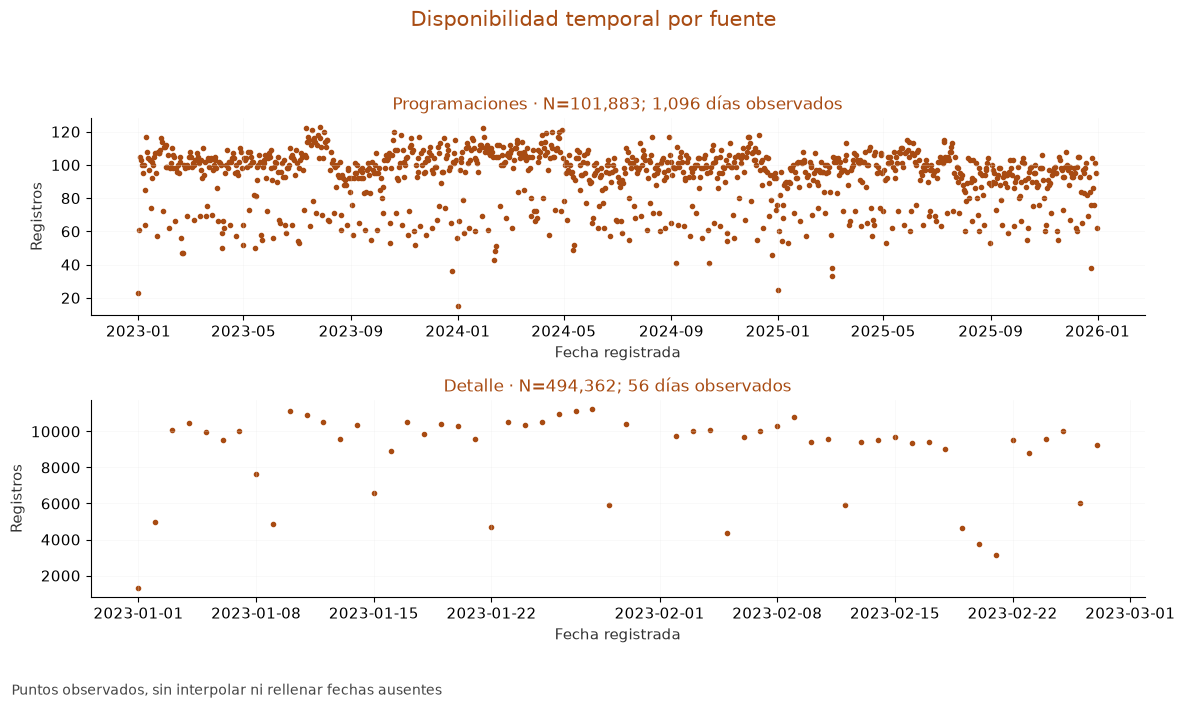

Fuente,Primera,Ultima,Fechas_presentes,Dias_observados
Programaciones,2023-01-01 05:00:00,2025-12-31 18:00:00,"101,883","1,096"
Detalle,2023-01-01 00:00:00,2023-02-27 00:00:00,"494,362",56


Campo,Universo,N_presente,Primera,Ultima,Unidad
fechasalida,"101,883","101,883",2023-01-01 05:00:00,2025-12-31 18:00:00,Fecha registrada de programación; sin validar ciclo
fechainicio,"101,883","101,054",2023-01-01 05:04:31,2026-01-16 12:06:14,Fecha registrada de programación; sin validar ciclo
fechafin,"101,883","91,539",2014-03-25 00:00:04,2026-01-20 10:16:21.820018,Fecha registrada de programación; sin validar ciclo


,Campo,Universo,N_presente,Primera,Ultima,Unidad
0,fechasalida,101883,101883,2023-01-01 05:00:00,2025-12-31 18:00:00.000000,Fecha registrada de programación; sin validar ...
1,fechainicio,101883,101054,2023-01-01 05:04:31,2026-01-16 12:06:14.000000,Fecha registrada de programación; sin validar ...
2,fechafin,101883,91539,2014-03-25 00:00:04,2026-01-20 10:16:21.820018,Fecha registrada de programación; sin validar ...


In [27]:
fig,axes=plt.subplots(2,1,figsize=(12,7))
cobertura=[]
for ax,t,serie in [(axes[0],'Programaciones',salida9),(axes[1],'Detalle',pd.to_datetime(t9.fecha))]:
    g=serie.dt.normalize().value_counts().sort_index().rename('N').rename_axis('Fecha').reset_index()
    tabla(OUT_EDA,'9_5_diaria_'+t.lower(),g,n=6)
    ax.scatter(g.Fecha,g.N,s=9,color=OSCURO);ax.set(title=f'{t} · N={int(g.N.sum()):,}; {len(g):,} días observados',ylabel='Registros',xlabel='Fecha registrada');ax.grid(alpha=.35)
    cobertura.append({'Fuente':t,'Primera':serie.min(),'Ultima':serie.max(),'Fechas_presentes':int(serie.notna().sum()),'Dias_observados':len(g)})
figura(OUT_EDA,'9_5_disponibilidad_diaria',fig,'Disponibilidad temporal por fuente','Puntos observados, sin interpolar ni rellenar fechas ausentes. Las escalas temporales son distintas.')
tabla(OUT_EDA,'9_5_cobertura',pd.DataFrame(cobertura),2)
narrativa(OUT_EDA,'9_5_diaria',f'Las programaciones cubren {salida9.dt.normalize().nunique():,} días; el detalle cubre {pd.to_datetime(t9.fecha).nunique():,}. Su disponibilidad más corta impide extrapolar la distribución por segmentos a todo 2023–2025. Los huecos de registro no se convierten en cero pasajeros.')
fechas_perfil=pd.DataFrame([{'Campo':c,'Universo':len(p9),'N_presente':int(p9[c].notna().sum()),'Primera':pd.to_datetime(p9[c]).min(),'Ultima':pd.to_datetime(p9[c]).max(),'Unidad':'Fecha registrada de programación; sin validar ciclo'} for c in ['fechasalida','fechainicio','fechafin']])
tabla(OUT_EDA,'9_5_fechas_efectivas',fechas_perfil,3)

**Lectura del resultado.** Las programaciones cubren 1,096 días; el detalle cubre 56. Su disponibilidad más corta impide extrapolar la distribución por segmentos a todo 2023–2025. Los huecos de registro no se convierten en cero pasajeros.

### **9.6. Agregados y perfiles secundarios**
**Población principal anual:** celdas de 2023–2025. El año 2026 se describe aparte. El consolidado se perfila sin atribuirle un período. Cada media de promedios da igual peso a las celdas: no es un promedio global por viaje. No se calcula media ponderada ni se presume aditividad sin verificar definiciones y denominadores.

Poblacion,Variable,Universo,N_utilizado,Faltantes_universo,No_finitos_seleccion,Ceros,Negativos,Media,Mediana,Max
Anual 2023–2025,subidas,"6,542","6,542",0,0,96,0,"1,181.64",108.00,"11,659.00"
Anual 2023–2025,bajadas,"6,542","6,542",0,0,98,0,"1,790.00",107.00,"1,115,946.00"
Anual 2023–2025,nro_viajes,"6,542","6,542",0,0,0,0,14.55,2.00,118.00
Anual 2023–2025,promedio_subidas,"6,542","6,542",0,0,96,0,71.58,69.00,225.00
Anual 2023–2025,promedio_bajadas,"6,542","6,542",0,0,98,0,80.14,68.00,"15,323.64"


Vista: 5 de 15 filas. Detalle completo: tablas/9_6_agregados_estadisticas.csv


ano,Celdas,Alcance
"2,023","2,079",Principal
"2,024","2,136",Principal
"2,025","2,327",Principal
"2,026","2,334",Separado


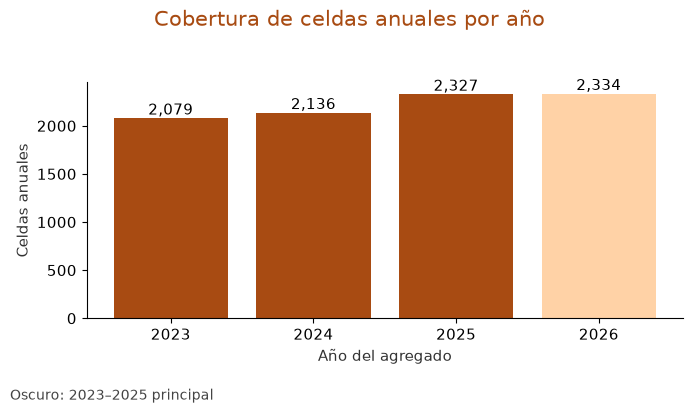

Fuente,Celdas,Viajes_nulos,Viajes_cero,Viajes_negativos,Grupos_con_varias_estacionalidades,Interpretacion,Aditividad
Anual principal,"6,542",0,0,0,"1,441",Misma franja/calendario base en más de una celda no prueba duplicación; estratos pueden solaparse,No confirmada: falta trazabilidad de programaciones componentes; no media global ponderada
"Consolidado, período pendiente","3,286",0,0,0,526,Misma franja/calendario base en más de una celda no prueba duplicación; estratos pueden solaparse,No confirmada: falta trazabilidad de programaciones componentes; no media global ponderada


,Fuente,Celdas,Viajes_nulos,Viajes_cero,Viajes_negativos,Grupos_con_varias_estacionalidades,Interpretacion,Aditividad
0,Anual principal,6542,0,0,0,1441,Misma franja/calendario base en más de una cel...,No confirmada: falta trazabilidad de programac...
1,"Consolidado, período pendiente",3286,0,0,0,526,Misma franja/calendario base en más de una cel...,No confirmada: falta trazabilidad de programac...


In [28]:
AGG9=[];AGG_COLS=['subidas','bajadas','nro_viajes','promedio_subidas','promedio_bajadas']
for nombre,df in [('Anual 2023–2025',a9.loc[a9.ano.isin([2023,2024,2025])]),('Anual 2026',a9.loc[a9.ano.eq(2026)]),('Consolidado: período desconocido',c9)]:
    for c in AGG_COLS:
        z,_=estadisticas(df[c]);z['Poblacion']=nombre;z['Variable']=c;AGG9.append(z)
AGG9=pd.DataFrame(AGG9);tabla(OUT_EDA,'9_6_agregados_estadisticas',AGG9,n=5)
g=a9.groupby('ano',dropna=False).size().rename('Celdas').reset_index().sort_values('ano');g['Alcance']=np.where(g.ano.isin([2023,2024,2025]),'Principal','Separado')
tabla(OUT_EDA,'9_6_anios_celdas',g,len(g))
fig,ax=plt.subplots(figsize=(7,4));ax.bar(g.ano.astype(str),g.Celdas,color=[OSCURO if v=='Principal' else CLARO for v in g.Alcance]);ax.set(ylabel='Celdas anuales',xlabel='Año del agregado')
for i,row in enumerate(g.itertuples()):ax.text(i,row.Celdas,f'{row.Celdas:,}',ha='center',va='bottom')
figura(OUT_EDA,'9_6_anios_celdas',fig,'Cobertura de celdas anuales por año','Oscuro: 2023–2025 principal. Claro: año separado. Celdas, no viajes ni programaciones.')
narrativa(OUT_EDA,'9_6_alcance',f'El alcance principal contiene {int(a9.ano.isin([2023,2024,2025]).sum()):,} celdas; 2026 aporta {int(a9.ano.eq(2026).sum()):,} fuera del principal. Las {len(c9):,} celdas del consolidado mantienen período pendiente. Sus perfiles no habilitan una suma comparable a la programación ni uso predictivo histórico.')
aditividad9=[]
for nombre,q,claves in [('Anual principal',a9.loc[a9.ano.isin([2023,2024,2025])],['ano','id_ruta','id_dia_semana','hora','hora_inicio','hora_fin']),
 ('Consolidado, período pendiente',c9,['id_ruta','id_dia_semana','hora','hora_inicio','hora_fin'])]:
    base=q.groupby(claves,dropna=False,observed=True).size()
    aditividad9.append({'Fuente':nombre,'Celdas':len(q),'Viajes_nulos':int(q.nro_viajes.isna().sum()),
      'Viajes_cero':int(q.nro_viajes.eq(0).sum()),'Viajes_negativos':int(q.nro_viajes.lt(0).sum()),
      'Grupos_con_varias_estacionalidades':int(base.gt(1).sum()),
      'Interpretacion':'Misma franja/calendario base en más de una celda no prueba duplicación; estratos pueden solaparse',
      'Aditividad':'No confirmada: falta trazabilidad de programaciones componentes; no media global ponderada'})
tabla(OUT_EDA,'9_6_auditoria_aditividad',pd.DataFrame(aditividad9),2)

**Lectura del resultado.** El alcance principal contiene 6,542 celdas; 2026 aporta 2,334 fuera del principal. Las 3,286 celdas del consolidado mantienen período pendiente. Sus perfiles no habilitan una suma comparable a la programación ni uso predictivo histórico.

**Celdas anuales principales: nro_viajes**

Unidad: celda anual 2023–2025, igual peso por celda. Se conservan valores presentes, incluidos ceros. No se interpreta como distribución de viajes individuales.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"8,876.00",Min,1.00
Seleccionadas criterio,"6,542.00",Max,118.00
N utilizado,"6,542.00",Q1,1.00
Fuera criterio,"2,334.00",Q3,4.00
Faltantes universo,0.00,P5,1.00
No finitos universo,0.00,P95,72.00
Faltantes seleccion,0.00,IQR,3.00
No finitos seleccion,0.00,Asimetria muestral,1.69
Ceros,0.00,Limite IQR inferior,-3.50
Negativos,0.00,Limite IQR superior,8.50


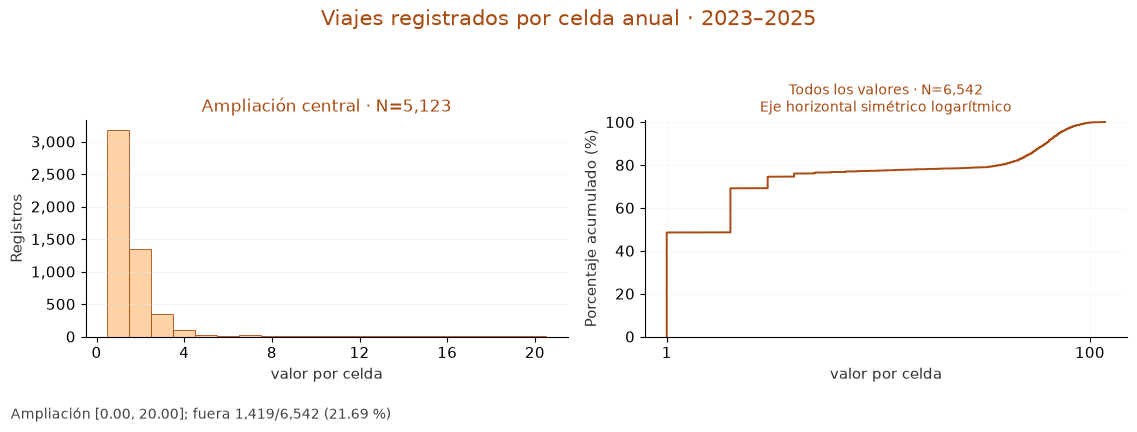

In [29]:
ra_nro_viajes=numerica(OUT_EDA,'9_6_anual_nro_viajes',a9['nro_viajes'],a9.ano.isin([2023,2024,2025]),'Viajes registrados por celda anual · 2023–2025','valor por celda',discreta=True,identificadores=a9.id_timbrada_anio,nota='Igual peso por celda; no promedio global por viaje.')

**Lectura del resultado.** Las celdas tienen denominadores muy diferentes: la mediana de nro_viajes es 2 y la media es mayor. Dar igual peso a cada celda describe su distribución, no una programación típica. Las coincidencias de franja/calendario base y la falta de trazabilidad impiden confirmar aditividad o una media global ponderada.

**Celdas anuales principales: promedio_subidas**

Unidad: celda anual 2023–2025, igual peso por celda. Se conservan valores presentes, incluidos ceros. No se interpreta como distribución de viajes individuales.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"8,876.00",Min,0.00
Seleccionadas criterio,"6,542.00",Max,225.00
N utilizado,"6,542.00",Q1,49.00
Fuera criterio,"2,334.00",Q3,92.43
Faltantes universo,0.00,P5,26.00
No finitos universo,0.00,P95,124.48
Faltantes seleccion,0.00,IQR,43.43
No finitos seleccion,0.00,Asimetria muestral,0.41
Ceros,96.00,Limite IQR inferior,-16.14
Negativos,0.00,Limite IQR superior,157.57


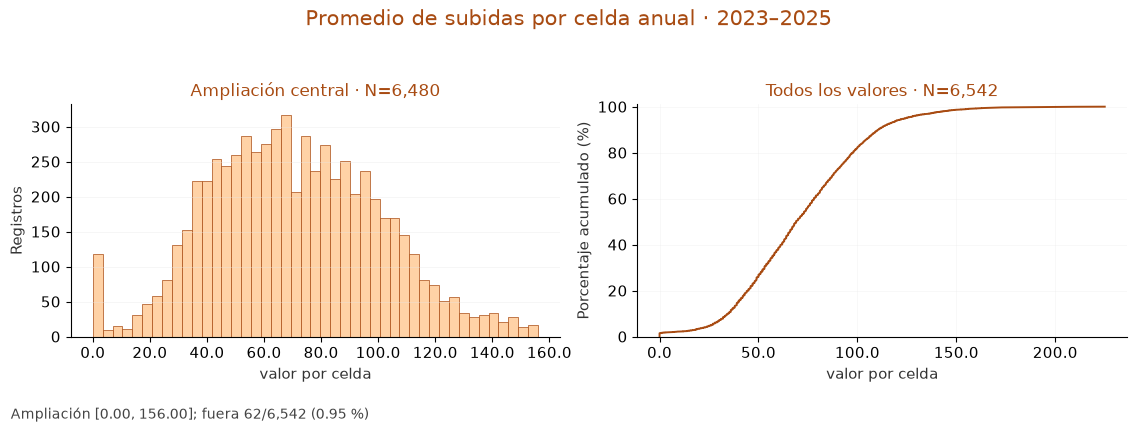

In [30]:
ra_promedio_subidas=numerica(OUT_EDA,'9_6_anual_promedio_subidas',a9['promedio_subidas'],a9.ano.isin([2023,2024,2025]),'Promedio de subidas por celda anual · 2023–2025','valor por celda',discreta=False,identificadores=a9.id_timbrada_anio,nota='Igual peso por celda; no promedio global por viaje.')

**Lectura del resultado.** La mediana por celda es 69.00, con igual peso por celda. La cola y los denominadores variables hacen que esta media de promedios no equivalga a un promedio global por viaje. No se suma ni pondera sin confirmar definiciones, aditividad y programaciones componentes; 2026 y el consolidado se perfilan por separado.

**Celdas anuales principales: promedio_bajadas**

Unidad: celda anual 2023–2025, igual peso por celda. Se conservan valores presentes, incluidos ceros. No se interpreta como distribución de viajes individuales.

Medida,Valor,Medida complementaria,Valor complementario
Universo,"8,876.00",Min,0.00
Seleccionadas criterio,"6,542.00",Max,"15,323.64"
N utilizado,"6,542.00",Q1,49.00
Fuera criterio,"2,334.00",Q3,91.00
Faltantes universo,0.00,P5,27.50
No finitos universo,0.00,P95,122.31
Faltantes seleccion,0.00,IQR,42.00
No finitos seleccion,0.00,Asimetria muestral,37.40
Ceros,98.00,Limite IQR inferior,-14.00
Negativos,0.00,Limite IQR superior,154.00


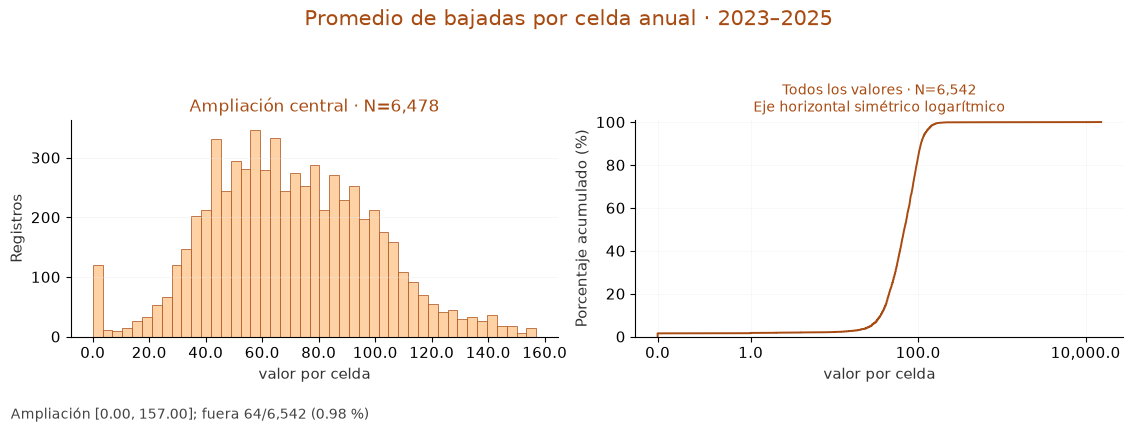

In [31]:
ra_promedio_bajadas=numerica(OUT_EDA,'9_6_anual_promedio_bajadas',a9['promedio_bajadas'],a9.ano.isin([2023,2024,2025]),'Promedio de bajadas por celda anual · 2023–2025','valor por celda',discreta=False,identificadores=a9.id_timbrada_anio,nota='Igual peso por celda; no promedio global por viaje.')

**Lectura del resultado.** La mediana por celda es 68.00, con igual peso por celda. La cola y los denominadores variables hacen que esta media de promedios no equivalga a un promedio global por viaje. No se suma ni pondera sin confirmar definiciones, aditividad y programaciones componentes; 2026 y el consolidado se perfilan por separado.

In [32]:
sec=[]
for t,cols in {'progvehiculos':['cantidad_subida_puerta1','cantidad_subida_puerta2','cantidad_bajada_puerta1','cantidad_bajada_puerta2','acumulada_subida','acumulada_bajada','torniqueteinicial','torniquetefinal','distancia_recorrida'],
 'rutas':['distancia_global'],'rutas_segmentos':['longitud_m']}.items():
    for c in cols:
        z,_=estadisticas(DAT_EDA[t][c]);z.update(Tabla=t,Variable=c,Unidad=('pendiente de confirmación' if 'distancia' in c else 'Según diccionario; ver evidencia'))
        sec.append(z)
tabla(OUT_EDA,'9_6_perfiles_secundarios_seguros',pd.DataFrame(sec),n=5)
evid=pd.DataFrame([{'Fuente':t,'Campo':c,'Descripcion':DOC.get(t,{}).get(c,{}).get('descripcion','pendiente'),'Significado':DOC.get(t,{}).get(c,{}).get('significado','pendiente')} for t,cols in {'timbradas_segmentos':['subidas','bajadas','pasajeros'],'progvehiculos':['numeropasajeros','numerobajadas','numerobloqueos']}.items() for c in cols])
tabla(OUT_EDA,'9_6_evidencia_unidad',evid,len(evid))
narrativa(OUT_EDA,'9_6_secundarios','Los perfiles secundarios conservan todos los valores presentes del archivo y no generan distribuciones administrativas sin utilidad. Distancias y contadores acumulados no se usan como magnitudes operativas confirmadas ni para definir viaje completo. El diccionario define subidas/bajadas específicamente por segmento y programación; esa evidencia permite describir la suma de conteos declarados, sin acreditar la medición ni convertir pasajeros en ocupación.')

Tabla,Variable,Universo,N_utilizado,Faltantes_universo,No_finitos_seleccion,Ceros,Negativos,Media,Mediana,Max
progvehiculos,cantidad_subida_puerta1,"101,883","100,089","1,794",0,"2,533",0,80.18,79.00,387.00
progvehiculos,cantidad_subida_puerta2,"101,883","100,089","1,794",0,"77,328",0,0.47,0.00,606.00
progvehiculos,cantidad_bajada_puerta1,"101,883","100,089","1,794",0,"69,357",0,0.77,0.00,352.00
progvehiculos,cantidad_bajada_puerta2,"101,883","100,089","1,794",0,"3,982",0,121.18,78.00,"782,067.00"
progvehiculos,acumulada_subida,"101,883","100,224","1,659",0,0,0,"401,550.95","437,227.50","807,439.00"


Vista: 5 de 11 filas. Detalle completo: tablas/9_6_perfiles_secundarios_seguros.csv


Fuente,Campo,Descripcion,Significado
timbradas_segmentos,subidas,Subidas en el segmento para ese viaje.,"Cantidad de pasajeros que subieron específicamente en este segmento, durante este viaje puntual."
timbradas_segmentos,bajadas,Bajadas en el segmento para ese viaje.,"Cantidad de pasajeros que bajaron específicamente en este segmento, durante este viaje puntual."
timbradas_segmentos,pasajeros,Carga/pasajeros a bordo (ojo: suma negativa → revisar semántica).,"Cantidad de pasajeros que van a bordo del vehículo al pasar por este segmento (la carga, no solo quienes suben o bajan ahí). El propio diccionario de datos advierte que se han observado sumas negativas, lo cual indica una inconsistencia en el cálculo que debe revisarse antes de usar esta columna con confianza."
progvehiculos,numeropasajeros,Total de pasajeros transportados (subidas).,Cantidad total de pasajeros que subieron durante este viaje.
progvehiculos,numerobajadas,Total de bajadas del viaje.,Cantidad total de pasajeros que bajaron durante este viaje.
progvehiculos,numerobloqueos,Total de bloqueos de puerta del viaje.,Cantidad total de veces que se registró un bloqueo de puerta durante el viaje.


**Lectura del resultado.** Los perfiles secundarios conservan todos los valores presentes del archivo y no generan distribuciones administrativas sin utilidad. Distancias y contadores acumulados no se usan como magnitudes operativas confirmadas ni para definir viaje completo. El diccionario define subidas/bajadas específicamente por segmento y programación; esa evidencia permite describir la suma de conteos declarados, sin acreditar la medición ni convertir pasajeros en ocupación.

### **9.7. Síntesis univariada y cobertura ejecutada**

Se concilian perfiles con el inventario y se exportan exclusiones y pendientes. Las posiciones extremas no se eliminan; las preguntas pasan al bivariado según su unidad y cobertura.

In [33]:
INVENTARIO9=cobertura_artefactos(OUT_EDA,INVENTARIO9)
tabla(OUT_EDA,'9_7_cobertura_final_univariado',INVENTARIO9,n=6)
res=INVENTARIO9.groupby(['Estado','Trabajo_ejecutado']).size().rename('Columnas').reset_index()
tabla(OUT_EDA,'9_7_resumen_cobertura',res,len(res))
narrativa(OUT_EDA,'9_7',f'La selección descriptiva conserva {int(m9["numeropasajeros"].sum()):,} pasajeros y {int(m9["numerobajadas"].sum()):,} bajadas registradas como variables independientes. El inventario cita archivos y filas verificadas, no listas de análisis propuestos. Las bajadas extremas se revisan en 10.1 sin recortarlas; duración, capacidad, calendario y agregados conservan sus límites conceptuales.')

Tabla,Columna,Tipo_almacenado,Semantica,Estado,Motivo,Unidad_documentada,Codificacion_documentada,Descripcion,Riesgo_fuga,Filas,Presentes,Unicos_presentes,Trabajo_ejecutado,Artefactos_verificados
progvehiculos,idprogramacion,int64[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,PK de la programación/viaje (referenciado por id_viaje).,"Nulo — es un identificador, conocido antes del viaje.","101,883","101,883","101,883",Sin artefacto analítico; metadatos/identificación fuera de preguntas,Ninguno
progvehiculos,idvehiculo,string[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Vehículo asignado (placa/interno).,Nulo — conocido antes del viaje (parte de la programación).,"101,883","101,883",353,Sin artefacto analítico; metadatos/identificación fuera de preguntas,Ninguno
progvehiculos,idconductor,int64[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Conductor asignado.,Nulo — conocido antes del viaje.,"101,883","101,883",756,Sin artefacto analítico; metadatos/identificación fuera de preguntas,Ninguno
progvehiculos,idruta,int64[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Ruta del viaje (FK rutas.idruta).,Nulo — conocido antes del viaje.,"101,883","101,883",1,Sin artefacto analítico; metadatos/identificación fuera de preguntas,Ninguno
progvehiculos,proceso,string[pyarrow],Categoría/código,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Proceso (sobusa).,Nulo.,"101,883","101,883",1,Sin artefacto analítico; metadatos/identificación fuera de preguntas,Ninguno
progvehiculos,fechasalida,timestamp[us][pyarrow],Temporal; significado según fuente,Análisis principal con resultados visibles,Población y filtro declarados en el bloque,pendiente de confirmación,No especificada en el diccionario,Fecha/hora programada de salida.,"Nulo — es programación, conocida con anticipación. Es la columna de tiempo natural para ordenar los viajes (útil como columna_orden en el mini-EDA).","101,883","101,883","100,553",Frecuencias temporales y cobertura visible,9_5_fechas_efectivas.csv; 9_5_diaria_programaciones.csv


Vista: 6 de 183 filas. Detalle completo: tablas/9_7_cobertura_final_univariado.csv


Estado,Trabajo_ejecutado,Columnas
Análisis principal con resultados visibles,Celdas por año; 2026 separado,1
Análisis principal con resultados visibles,Cobertura temporal del detalle visible,1
Análisis principal con resultados visibles,Estadísticas y figura,7
Análisis principal con resultados visibles,Frecuencias temporales y cobertura visible,1
Análisis principal con resultados visibles,Frecuencias visibles,5
Análisis principal con resultados visibles,"Perfil de celdas; igual peso, sin aditividad confirmada",3
"Disponibilidad comprobada, sin distribución",Disponibilidad y rango/constancia en tabla,8
"Disponibilidad comprobada, sin distribución","Disponibilidad, constancia o ausencia; sin figura",1
"Disponibilidad comprobada, sin distribución",Tabla de disponibilidad o casi constancia; sin figura,2
Exclusión justificada,Sin artefacto analítico; metadatos/identificación fuera de preguntas,135


**Lectura del resultado.** La selección descriptiva conserva 90,947 pasajeros y 90,947 bajadas registradas como variables independientes. El inventario cita archivos y filas verificadas, no listas de análisis propuestos. Las bajadas extremas se revisan en 10.1 sin recortarlas; duración, capacidad, calendario y agregados conservan sus límites conceptuales.

## **10. Análisis exploratorio bivariado**
Se ejecuta después de 9 en el mismo kernel. Para un kernel nuevo, comenzar en 9.1; no hace falta ejecutar 1–8. Se seleccionan relaciones por preguntas, sin matrices de correlación indiscriminadas ni pruebas de significación. Programaciones repetidas por vehículo y fecha no se suponen independientes. No se estima causalidad ni desempeño predictivo.

### **10.1. ¿La asociación entre pasajeros y bajadas implica igualdad?**

Unidad: programación. Población: intersección de ambas selecciones independientes S/N, conteos presentes y no negativos. Se conservan todos los pares en las correlaciones; el hexbin evita superposición y compara con igualdad.

El diagnóstico siguiente usa la selección independiente de bajadas para describir magnitudes y su contribución a la suma disponible; las correlaciones usan únicamente la intersección finita de ambas selecciones. La suma no representa demanda completa.

**Diagnóstico localizado de las bajadas extremas.** Selección independiente de bajadas: S/N, presentes y no negativas. Top 10 por magnitud, orden estable; una fila por programación. Se muestran contexto y conteos en dos tablas vinculadas por ID; el archivo Parquet conserva todo. Los porcentajes usan como denominador la suma registrada de la selección, no una demanda completa.

In [34]:
_,bajadas_principales=estadisticas(p9.numerobajadas,m9['numerobajadas'])
assert np.isclose(bajadas_principales.max(),r_numerobajadas['Max']) and np.isclose(bajadas_principales.mean(),r_numerobajadas['Media'])
orden_extremos=bajadas_principales.sort_values(ascending=False,kind='stable')
cols_contexto=['idprogramacion','idvehiculo','fechasalida','fechainicio','fechafin','finalizado','cancelada','modificado_manual','excepcion']
cols_conteos=['numeropasajeros','numerobajadas','cantidad_subida_puerta1','cantidad_subida_puerta2','cantidad_bajada_puerta1','cantidad_bajada_puerta2']
extremos_bajadas=p9.loc[orden_extremos.head(10).index,cols_contexto+cols_conteos].copy()
extremos_bajadas['duracion_registrada_min']=duracion9.loc[extremos_bajadas.index]
extremos_bajadas.to_parquet(OUT_EDA/'incidencias/bajadas_extremas_top10.parquet',index=False)
tabla(OUT_EDA,'10_1_extremos_bajadas_contexto',extremos_bajadas[cols_contexto+['duracion_registrada_min']],10)
tabla(OUT_EDA,'10_1_extremos_bajadas_conteos',extremos_bajadas[['idprogramacion']+cols_conteos],10)
contribucion_extremos=pd.DataFrame([{'Grupo':f'Top {k} por bajadas','N':min(k,len(orden_extremos)),
 'Suma_bajadas':orden_extremos.head(k).sum(min_count=1),'Denominador_suma_disponible':bajadas_principales.sum(min_count=1),
 'Denominador_programaciones':len(bajadas_principales)} for k in [1,5,10]])
contribucion_extremos['Porcentaje_suma']=100*contribucion_extremos.Suma_bajadas/contribucion_extremos.Denominador_suma_disponible
tabla(OUT_EDA,'10_1_contribucion_extremos',contribucion_extremos,len(contribucion_extremos))
narrativa(OUT_EDA,'10_1_extremos',f'Se comprueban máximo {bajadas_principales.max():,.0f}, media {bajadas_principales.mean():.2f} y mediana {bajadas_principales.median():.0f} en la selección independiente de bajadas. El mayor registro representa {contribucion_extremos.iloc[0].Porcentaje_suma:.2f} % de la suma disponible, y los diez mayores {contribucion_extremos.iloc[2].Porcentaje_suma:.2f} %. Identificadores, fechas, puertas e indicadores se muestran literalmente: no prueban una causa. La decisión pendiente es confirmar medición y contexto de esos registros; no se sustituyen ni excluyen automáticamente.')

idprogramacion,idvehiculo,fechasalida,fechainicio,fechafin,finalizado,cancelada,modificado_manual,excepcion,duracion_registrada_min
"5,446,141",SOBUSA156,2023-06-23 08:00:00,2023-06-23 08:01:18,2023-06-23 11:45:51,S,N,False,N,224.55
"5,457,377",SOBUSA156,2023-06-28 10:04:00,2023-06-28 10:05:04,2023-06-28 13:44:04,S,N,False,N,219.00
"5,447,203",SOBUSA156,2023-06-23 14:00:00,2023-06-23 14:00:09,2023-06-23 18:10:48,S,N,False,N,250.65
"5,445,473",SOBUSA156,2023-06-22 19:48:00,2023-06-22 19:48:07,2023-06-22 22:45:28,S,N,False,N,177.35
"6,421,506",SOBUSA156,2024-08-17 12:12:00,2024-08-17 12:15:15,2024-08-17 16:40:09,S,N,False,N,264.90
"5,750,561",SOBUSA156,2023-10-31 07:00:00,2023-10-31 07:00:29,2023-10-31 11:33:38,S,N,False,N,273.15
"5,447,918",SOBUSA156,2023-06-23 18:40:00,2023-06-23 18:41:27,2023-06-23 22:15:51,S,N,False,N,214.40
"6,423,885",SOBUSA556,2024-08-18 15:18:00,2024-08-18 15:21:05,2024-08-18 18:50:56,S,N,False,N,209.85
"6,969,391",SOBUSA431,2025-04-19 13:56:00,2025-04-19 13:55:56,2025-04-19 17:09:20,S,N,False,N,193.40
"6,565,196",SOBUSA537,2024-10-22 09:10:00,2024-10-22 09:11:31,2024-10-22 20:42:20,S,N,False,N,690.82


idprogramacion,numeropasajeros,numerobajadas,cantidad_subida_puerta1,cantidad_subida_puerta2,cantidad_bajada_puerta1,cantidad_bajada_puerta2
"5,446,141",77,"1,107,795",71,0,2,"750,439"
"5,457,377",65,"716,522",64,0,1,"358,277"
"5,447,203",106,"714,950",105,0,5,"357,491"
"5,445,473",44,"714,734",40,2,0,"357,508"
"6,421,506",112,"423,648",112,0,1,"423,647"
"5,750,561",126,"379,432",126,0,1,"379,431"
"5,447,918",59,"357,544",59,0,1,"357,543"
"6,423,885",76,"23,451",76,0,0,"23,451"
"6,969,391",67,487,67,0,0,487
"6,565,196",350,374,284,66,93,281


Grupo,N,Suma_bajadas,Denominador_suma_disponible,Denominador_programaciones,Porcentaje_suma
Top 1 por bajadas,1,"1,107,795.00","11,842,792.00","90,947",9.35
Top 5 por bajadas,5,"3,677,649.00","11,842,792.00","90,947",31.05
Top 10 por bajadas,10,"4,438,937.00","11,842,792.00","90,947",37.48


**Lectura del resultado.** Se comprueban máximo 1,107,795, media 130.22 y mediana 80 en la selección independiente de bajadas. El mayor registro representa 9.35 % de la suma disponible, y los diez mayores 37.48 %. Identificadores, fechas, puertas e indicadores se muestran literalmente: no prueban una causa. La decisión pendiente es confirmar medición y contexto de esos registros; no se sustituyen ni excluyen automáticamente.

N_pares,Pearson,Spearman
"90,947",0.0058,0.9738


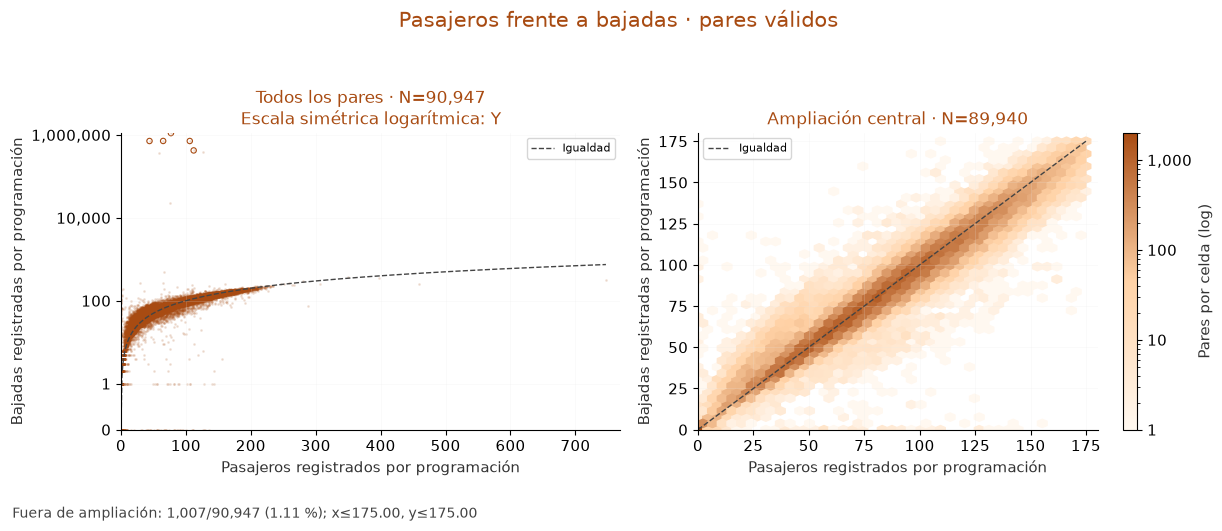

In [35]:
r_pares=relaciones(OUT_EDA,'10_1_pares',p9.loc[pares9,'numeropasajeros'],p9.loc[pares9,'numerobajadas'],'Pasajeros frente a bajadas · pares válidos',['Pasajeros registrados por programación','Bajadas registradas por programación'],igualdad=True)

**Lectura del resultado.** Con 90,947 pares, Pearson=0.006 y Spearman=0.974. La asociación por rangos es fuerte, pero la asociación lineal con todos los extremos es débil. Correlación no es igualdad y la diferencia no mide ocupación.

Caso,N,Denominador_pares,Porcentaje
Bajadas menores,"44,406","90,947",48.83
Iguales,"8,419","90,947",9.26
Bajadas mayores,"38,122","90,947",41.92


Medida,Valor,Medida complementaria,Valor complementario
Universo,"90,947.00",Min,-429.00
Seleccionadas criterio,"90,947.00",Max,"1,107,718.00"
N utilizado,"90,947.00",Q1,-4.00
Fuera criterio,0.00,Q3,3.00
Faltantes universo,0.00,P5,-13.00
No finitos universo,0.00,P95,12.00
Faltantes seleccion,0.00,IQR,7.00
No finitos seleccion,0.00,Asimetria muestral,137.85
Ceros,"8,419.00",Limite IQR inferior,-14.50
Negativos,"44,406.00",Limite IQR superior,13.50


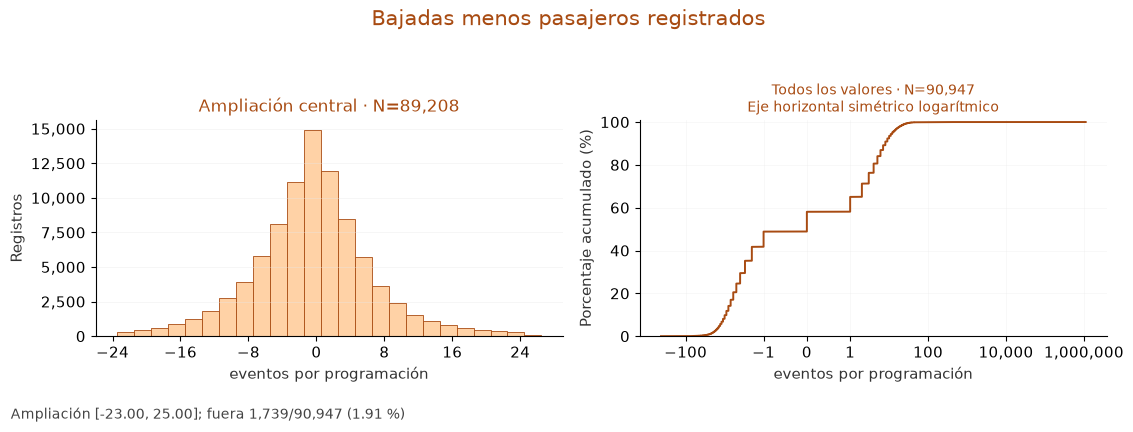

Medida,Valor,Medida complementaria,Valor complementario
N pares,"90,947.00",P95,12.00
Diferencia media,48.26,Min,-429.00
Diferencia mediana,0.00,Max,"1,107,718.00"
P5,-13.00,Absoluta media,54.53
Q1,-4.00,Absoluta mediana,4.00
Q3,3.00,,


Poblacion,N_pares,Pearson,Spearman,Denominador_principal,Pares_apartados,Porcentaje_apartado
Principal: todos los pares,"90,947",0.0058,0.9738,"90,947",0,0.0000
Sensibilidad central: ambos conteos ≤ 175.00,"89,940",0.9726,0.9735,"90,947","1,007",1.1072
Influencia localizada: sin ID 5446141,"90,946",0.0077,0.9738,"90,947",1,0.0011


In [36]:
q_pares,diagnostico_pares=pares_validos(p9.loc[pares9,'numeropasajeros'],p9.loc[pares9,'numerobajadas'])
assert len(q_pares)==r_pares['N_pares'] and diagnostico_pares['Pares_descartados_no_comparables']==0
diferencia9=q_pares.y-q_pares.x
igualdad10=pd.DataFrame([{'Caso':'Bajadas menores','N':int(diferencia9.lt(0).sum())},
 {'Caso':'Iguales','N':int(diferencia9.eq(0).sum())},{'Caso':'Bajadas mayores','N':int(diferencia9.gt(0).sum())}])
igualdad10['Denominador_pares']=len(diferencia9);igualdad10['Porcentaje']=100*igualdad10.N/len(diferencia9)
tabla(OUT_EDA,'10_1_igualdad',igualdad10,3)
numerica(OUT_EDA,'10_1_diferencias',diferencia9,None,'Bajadas menos pasajeros registrados','eventos por programación',identificadores=p9.idprogramacion,nota='Diferencia descriptiva; no ocupación.')
res_diferencia=pd.DataFrame([{'N_pares':len(diferencia9),'Diferencia_media':diferencia9.mean(),
 'Diferencia_mediana':diferencia9.median(),'P5':diferencia9.quantile(.05),'Q1':diferencia9.quantile(.25),
 'Q3':diferencia9.quantile(.75),'P95':diferencia9.quantile(.95),'Min':diferencia9.min(),'Max':diferencia9.max(),
 'Absoluta_media':diferencia9.abs().mean(),'Absoluta_mediana':diferencia9.abs().median()}])
tabla(OUT_EDA,'10_1_diferencia_resumen',res_diferencia,1)
limite_pares=max(q_pares.x.quantile(.99),q_pares.y.quantile(.99))
region=q_pares.x.between(0,limite_pares)&q_pares.y.between(0,limite_pares)
indice_mayor=q_pares.y.idxmax();sin_mayor=q_pares.index!=indice_mayor
sens_pares=pd.DataFrame([{'Poblacion':'Principal: todos los pares',**r_pares},
 {'Poblacion':f'Sensibilidad central: ambos conteos ≤ {limite_pares:.2f}',**correlaciones(q_pares.loc[region,'x'],q_pares.loc[region,'y'])},
 {'Poblacion':f'Influencia localizada: sin ID {p9.loc[indice_mayor,"idprogramacion"]}',**correlaciones(q_pares.loc[sin_mayor,'x'],q_pares.loc[sin_mayor,'y'])}])
sens_pares['Denominador_principal']=len(q_pares);sens_pares['Pares_apartados']=len(q_pares)-sens_pares.N_pares
sens_pares['Porcentaje_apartado']=100*sens_pares.Pares_apartados/len(q_pares)
tabla(OUT_EDA,'10_1_sensibilidad_region',sens_pares,len(sens_pares))
narrativa(OUT_EDA,'10_1_diferencias',f'La igualdad exacta alcanza {100*diferencia9.eq(0).mean():.2f} %; la diferencia típica es {diferencia9.median():.0f}, con Q1={diferencia9.quantile(.25):.0f} y Q3={diferencia9.quantile(.75):.0f}. La diferencia absoluta mediana es {diferencia9.abs().median():.0f}, frente a una media de {diferencia9.abs().mean():.2f}, sensible a magnitudes extremas. Pearson principal ({r_pares["Pearson"]:.4f}) mide asociación lineal; Spearman ({r_pares["Spearman"]:.4f}) describe rangos. La sensibilidad central conserva {int(region.sum()):,} pares y aparta {100*(~region).mean():.2f} %; sin solo el mayor registro Pearson pasa a {sens_pares.iloc[2].Pearson:.4f}. Retirar solo el mayor no restablece una asociación lineal alta: la influencia no se reduce a un único registro. Ninguna sensibilidad cambia la selección aprobada, acredita limpieza ni convierte el saldo en ocupación.')

**Lectura del resultado.** La igualdad exacta alcanza 9.26 %; la diferencia típica es 0, con Q1=-4 y Q3=3. La diferencia absoluta mediana es 4, frente a una media de 54.53, sensible a magnitudes extremas. Pearson principal (0.0058) mide asociación lineal; Spearman (0.9738) describe rangos. La sensibilidad central conserva 89,940 pares y aparta 1.11 %; sin solo el mayor registro Pearson pasa a 0.0077. Retirar solo el mayor no restablece una asociación lineal alta: la influencia no se reduce a un único registro. Ninguna sensibilidad cambia la selección aprobada, acredita limpieza ni convierte el saldo en ocupación.

### **10.2. Conteos frente al calendario de salida**

Unidad: programación. Cada variable utiliza su propia selección. Se exportan N, universo de grupo, cobertura, suma disponible, media, mediana, DE, Q1, Q3 e IQR. Las sumas son totales registrados en la selección, no demanda completa; las bandas son distribución interna, no intervalos inferenciales.

**Comparación por día de la semana**

Grupos ordenados por calendario programado; sin festividades no validadas. Los N completos y coberturas por grupo quedan en CSV.

Variable,grupo,N_universo,Seleccionadas_criterio,Faltantes_universo,No_finitos_universo,N,Media,Mediana,DE_muestral,Min,Max,Total_registrado,Q1,Q3,IQR,Porcentaje_cobertura
numeropasajeros,0,"14,045","12,472",275,0,"12,472",84.77,85.00,40.42,0.00,266.00,"1,057,280.00",55.00,113.00,58.00,88.80
numeropasajeros,1,"15,569","14,070",254,0,"14,070",87.62,89.00,41.28,0.00,747.00,"1,232,804.00",59.00,115.00,56.00,90.37
numeropasajeros,2,"15,735","14,233",242,0,"14,233",86.26,87.00,39.87,0.00,307.00,"1,227,780.00",59.00,113.00,54.00,90.45
numeropasajeros,3,"15,541","14,040",233,0,"14,040",85.28,86.00,40.09,0.00,398.00,"1,197,282.00",57.00,113.00,56.00,90.34
numeropasajeros,4,"15,474","14,033",232,0,"14,033",86.39,86.00,39.72,0.00,251.00,"1,212,333.00",59.00,114.00,55.00,90.69
numeropasajeros,5,"15,226","13,664",292,0,"13,664",72.99,72.00,33.25,0.00,207.00,"997,304.00",52.00,94.00,42.00,89.74
numeropasajeros,6,"10,293","8,435",208,0,"8,435",62.74,60.00,26.96,0.00,199.00,"529,199.00",44.00,79.00,35.00,81.95
numerobajadas,0,"14,045","12,472",275,0,"12,472",84.12,83.00,38.86,0.00,240.00,"1,049,126.00",56.00,111.00,55.00,88.80
numerobajadas,1,"15,569","14,070",254,0,"14,070",113.89,87.00,"3,198.30",0.00,"379,432.00","1,602,488.00",60.00,113.00,53.00,90.37
numerobajadas,2,"15,735","14,233",242,0,"14,233",136.01,86.00,"6,005.35",0.00,"716,522.00","1,935,797.00",59.00,112.00,53.00,90.45


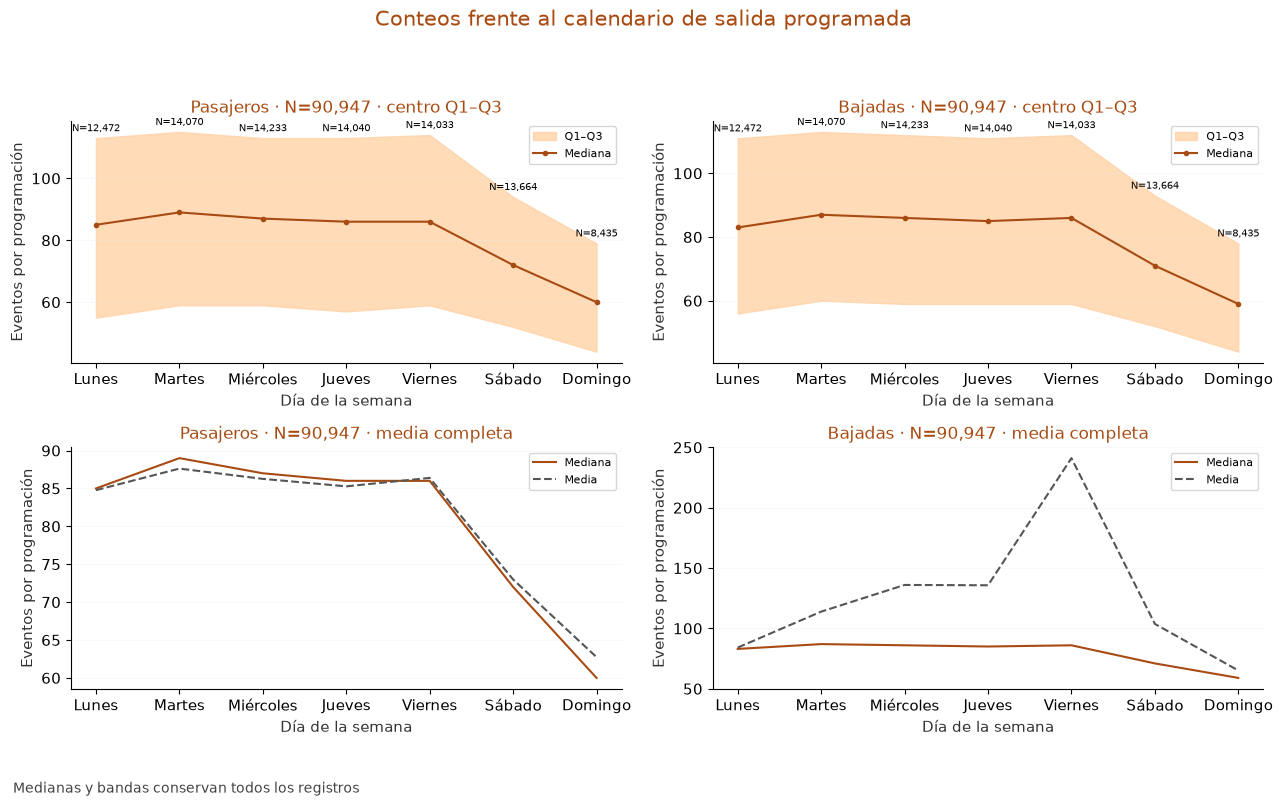

In [37]:
g_dia=calendario(OUT_EDA,'10_2_dia',p9,{v:m9[v] for v in ['numeropasajeros','numerobajadas']},'dia',dict(enumerate(ORDEN_DIAS9)))

**Lectura del resultado.** En pasajeros, las medianas van de 60.00 a 89.00. Las bandas Q1–Q3 describen variación interna, no incertidumbre inferencial. Las medias de bajadas pueden ser mucho mayores por la influencia aritmética de extremos conservados; no se les atribuye causa. N, cobertura y totales distinguen programaciones, conteo típico y suma registrada. El calendario de salida no identifica todos los momentos de abordaje.

**Comparación por hora programada**

Grupos ordenados por calendario programado; sin festividades no validadas. Los N completos y coberturas por grupo quedan en CSV.

Variable,grupo,N_universo,Seleccionadas_criterio,Faltantes_universo,No_finitos_universo,N,Media,Mediana,DE_muestral,Min,Max,Total_registrado,Q1,Q3,IQR,Porcentaje_cobertura
numeropasajeros,3,1,0,0,0,0,No evaluable,No evaluable,No evaluable,No evaluable,No evaluable,No evaluable,No evaluable,No evaluable,No evaluable,0.00
numeropasajeros,4,"2,838","2,532",94,0,"2,532",82.39,83.00,37.92,0.00,184.00,"208,602.00",60.00,109.00,49.00,89.22
numeropasajeros,5,"15,132","13,565",452,0,"13,565",65.54,59.00,42.83,0.00,264.00,"889,089.00",31.00,96.00,65.00,89.64
numeropasajeros,6,"7,240","6,771",91,0,"6,771",90.83,93.00,36.15,0.00,230.00,"615,002.00",66.00,115.00,49.00,93.52
numeropasajeros,7,"6,567","6,177",64,0,"6,177",83.46,83.00,31.10,0.00,198.00,"515,534.00",62.00,104.00,42.00,94.06
numeropasajeros,8,"5,828","5,456",42,0,"5,456",90.57,88.00,35.29,0.00,398.00,"494,173.00",67.00,112.00,45.00,93.62
numeropasajeros,9,"5,749","5,359",52,0,"5,359",87.72,85.00,34.93,0.00,747.00,"470,071.00",64.00,108.00,44.00,93.22
numeropasajeros,10,"5,535","5,143",32,0,"5,143",83.89,81.00,35.20,0.00,307.00,"431,424.00",60.00,105.00,45.00,92.92
numeropasajeros,11,"4,928","4,441",50,0,"4,441",88.35,85.00,36.76,0.00,216.00,"392,370.00",62.00,112.00,50.00,90.12
numeropasajeros,12,"5,369","4,818",37,0,"4,818",97.75,97.00,39.18,0.00,232.00,"470,957.00",70.00,123.00,53.00,89.74


Vista: 12 de 36 filas. Detalle completo: tablas/10_2_hora.csv


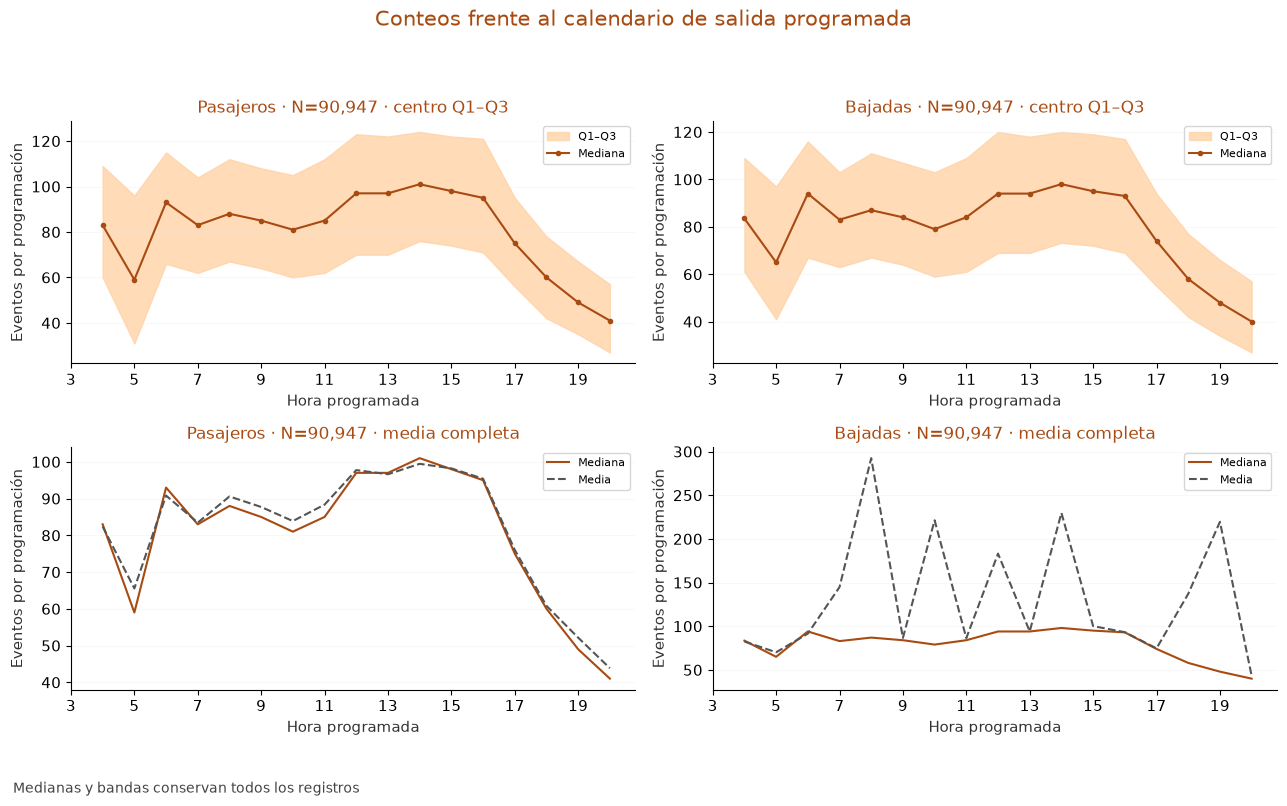

In [38]:
g_hora=calendario(OUT_EDA,'10_2_hora',p9,{v:m9[v] for v in ['numeropasajeros','numerobajadas']},'hora',None)

**Lectura del resultado.** En pasajeros, las medianas van de 41.00 a 101.00. Las bandas Q1–Q3 describen variación interna, no incertidumbre inferencial. Las medias de bajadas pueden ser mucho mayores por la influencia aritmética de extremos conservados; no se les atribuye causa. N, cobertura y totales distinguen programaciones, conteo típico y suma registrada. El calendario de salida no identifica todos los momentos de abordaje.

**Comparación por año**

Grupos ordenados por calendario programado; sin festividades no validadas. Los N completos y coberturas por grupo quedan en CSV.

Variable,grupo,N_universo,Seleccionadas_criterio,Faltantes_universo,No_finitos_universo,N,Media,Mediana,DE_muestral,Min,Max,Total_registrado,Q1,Q3,IQR,Porcentaje_cobertura
numeropasajeros,"2,023","34,270","30,866",445,0,"30,866",85.32,84.00,38.25,0.00,288.00,"2,633,406.00",58.00,111.00,53.00,90.07
numeropasajeros,"2,024","34,560","30,736",742,0,"30,736",82.47,82.00,40.09,0.00,747.00,"2,534,901.00",54.00,110.00,56.00,88.94
numeropasajeros,"2,025","33,053","29,345",549,0,"29,345",77.89,77.00,38.26,0.00,398.00,"2,285,675.00",50.00,104.00,54.00,88.78
numerobajadas,"2,023","34,270","30,866",445,0,"30,866",213.88,83.00,"9,913.39",0.00,"1,107,795.00","6,601,774.00",59.00,109.00,50.00,90.07
numerobajadas,"2,024","34,560","30,736",742,0,"30,736",96.11,80.00,"2,419.98",0.00,"423,648.00","2,954,071.00",55.00,107.00,52.00,88.94
numerobajadas,"2,025","33,053","29,345",549,0,"29,345",77.93,76.00,37.10,0.00,487.00,"2,286,947.00",51.00,103.00,52.00,88.78


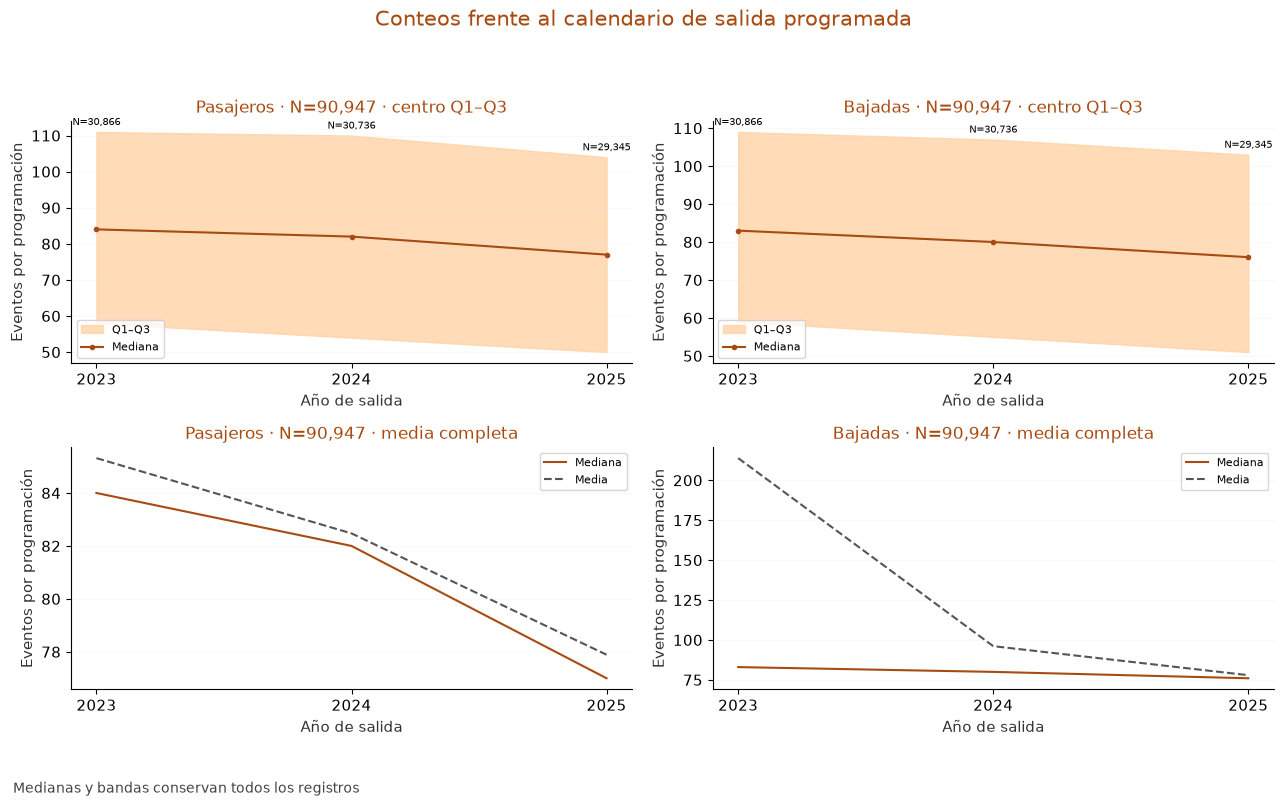

In [39]:
g_anio=calendario(OUT_EDA,'10_2_anio',p9,{v:m9[v] for v in ['numeropasajeros','numerobajadas']},'anio',None)

**Lectura del resultado.** En pasajeros, las medianas van de 77.00 a 84.00. Las bandas Q1–Q3 describen variación interna, no incertidumbre inferencial. Las medias de bajadas pueden ser mucho mayores por la influencia aritmética de extremos conservados; no se les atribuye causa. N, cobertura y totales distinguen programaciones, conteo típico y suma registrada. El calendario de salida no identifica todos los momentos de abordaje.

**Comparación por mes**

Grupos ordenados por calendario programado; sin festividades no validadas. Los N completos y coberturas por grupo quedan en CSV.

Variable,grupo,N_universo,Seleccionadas_criterio,Faltantes_universo,No_finitos_universo,N,Media,Mediana,DE_muestral,Min,Max,Total_registrado,Q1,Q3,IQR,Porcentaje_cobertura
numeropasajeros,2023-01,"2,952","2,661",44,0,"2,661",75.51,74.00,31.85,0.00,199.00,"200,941.00",54.00,97.00,43.00,90.14
numeropasajeros,2023-02,"2,578","2,280",37,0,"2,280",90.02,88.50,39.81,0.00,246.00,"205,240.00",61.00,117.00,56.00,88.44
numeropasajeros,2023-03,"2,996","2,690",39,0,"2,690",91.00,90.00,38.91,0.00,221.00,"244,791.00",63.00,118.00,55.00,89.79
numeropasajeros,2023-04,"2,703","2,437",24,0,"2,437",84.00,82.00,37.23,0.00,230.00,"204,716.00",58.00,109.00,51.00,90.16
numeropasajeros,2023-05,"2,873","2,608",31,0,"2,608",87.75,86.00,39.05,0.00,211.00,"228,841.00",59.00,115.00,56.00,90.78
numeropasajeros,2023-06,"2,779","2,497",26,0,"2,497",81.63,80.00,35.59,0.00,220.00,"203,823.00",55.00,106.00,51.00,89.85
numeropasajeros,2023-07,"3,118","2,824",37,0,"2,824",77.79,77.00,34.43,0.00,222.00,"219,676.00",54.00,100.00,46.00,90.57
numeropasajeros,2023-08,"2,882","2,568",41,0,"2,568",91.01,91.00,40.49,0.00,206.00,"233,705.00",61.00,120.00,59.00,89.10
numeropasajeros,2023-09,"2,693","2,422",33,0,"2,422",93.88,93.00,41.95,0.00,220.00,"227,388.00",67.00,124.00,57.00,89.94
numeropasajeros,2023-10,"2,912","2,620",46,0,"2,620",85.11,85.00,38.70,0.00,288.00,"222,984.00",58.00,111.00,53.00,89.97


Vista: 12 de 72 filas. Detalle completo: tablas/10_2_mes.csv


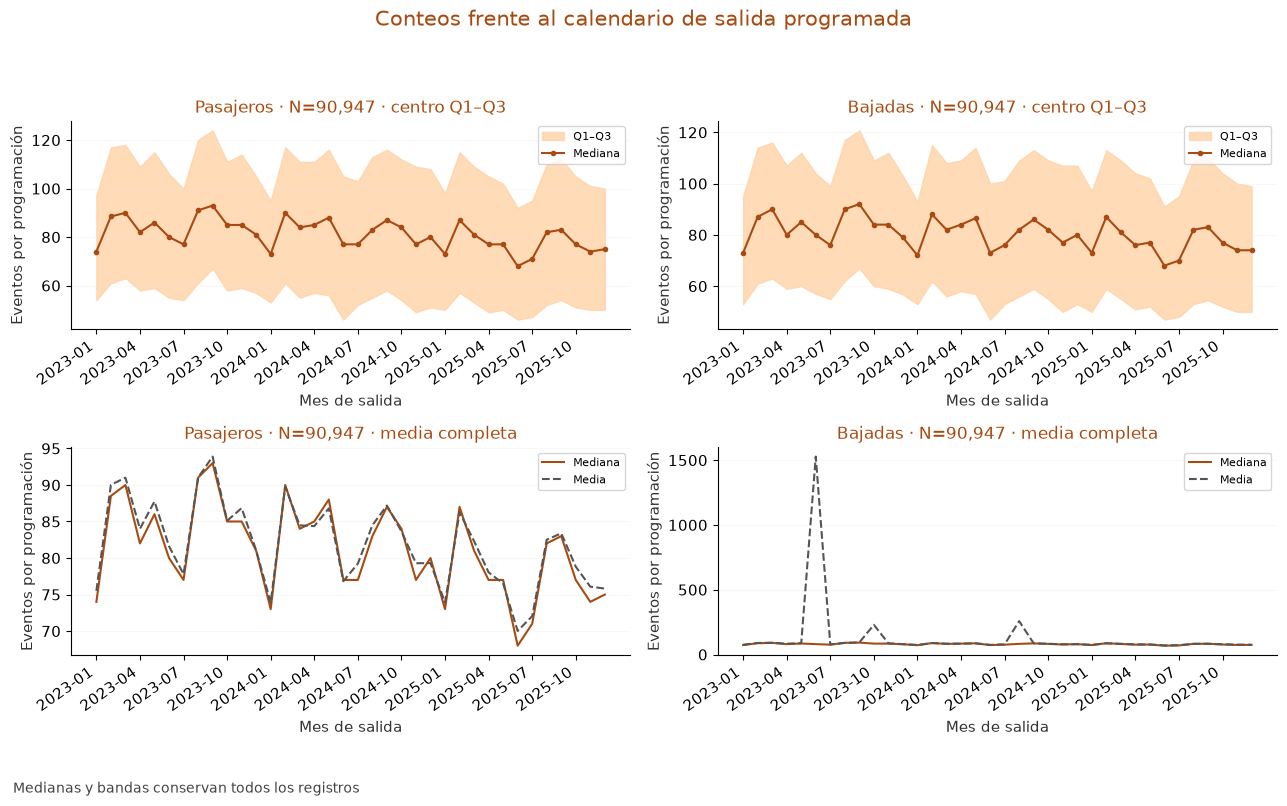

In [40]:
g_mes=calendario(OUT_EDA,'10_2_mes',p9,{v:m9[v] for v in ['numeropasajeros','numerobajadas']},'mes',None)

**Lectura del resultado.** En pasajeros, las medianas van de 68.00 a 93.00. Las bandas Q1–Q3 describen variación interna, no incertidumbre inferencial. Las medias de bajadas pueden ser mucho mayores por la influencia aritmética de extremos conservados; no se les atribuye causa. N, cobertura y totales distinguen programaciones, conteo típico y suma registrada. El calendario de salida no identifica todos los momentos de abordaje.

**Mapa día × hora: mediana y disponibilidad**

Dos dimensiones de calendario de salida. Selecciones independientes; celdas sin observaciones quedan grises, no se rellenan con cero. El mapa de N acompaña las medianas y permite reconocer coberturas distintas.

dia,hora,N,Media,Mediana
0,4,340,84.22,89.00
0,5,"1,767",70.11,62.00
0,6,902,94.79,98.00
0,7,840,84.62,85.00
0,8,743,92.41,91.00
0,9,731,86.78,86.00
0,10,720,82.75,78.00


Vista: 7 de 118 filas. Detalle completo: tablas/10_2_mapa_numeropasajeros.csv


dia,hora,N,Media,Mediana
0,4,340,84.08,89.00
0,5,"1,767",75.06,71.00
0,6,902,95.36,99.00
0,7,840,84.71,84.00
0,8,743,90.85,89.00
0,9,731,86.20,85.00
0,10,720,80.24,75.00


Vista: 7 de 118 filas. Detalle completo: tablas/10_2_mapa_numerobajadas.csv


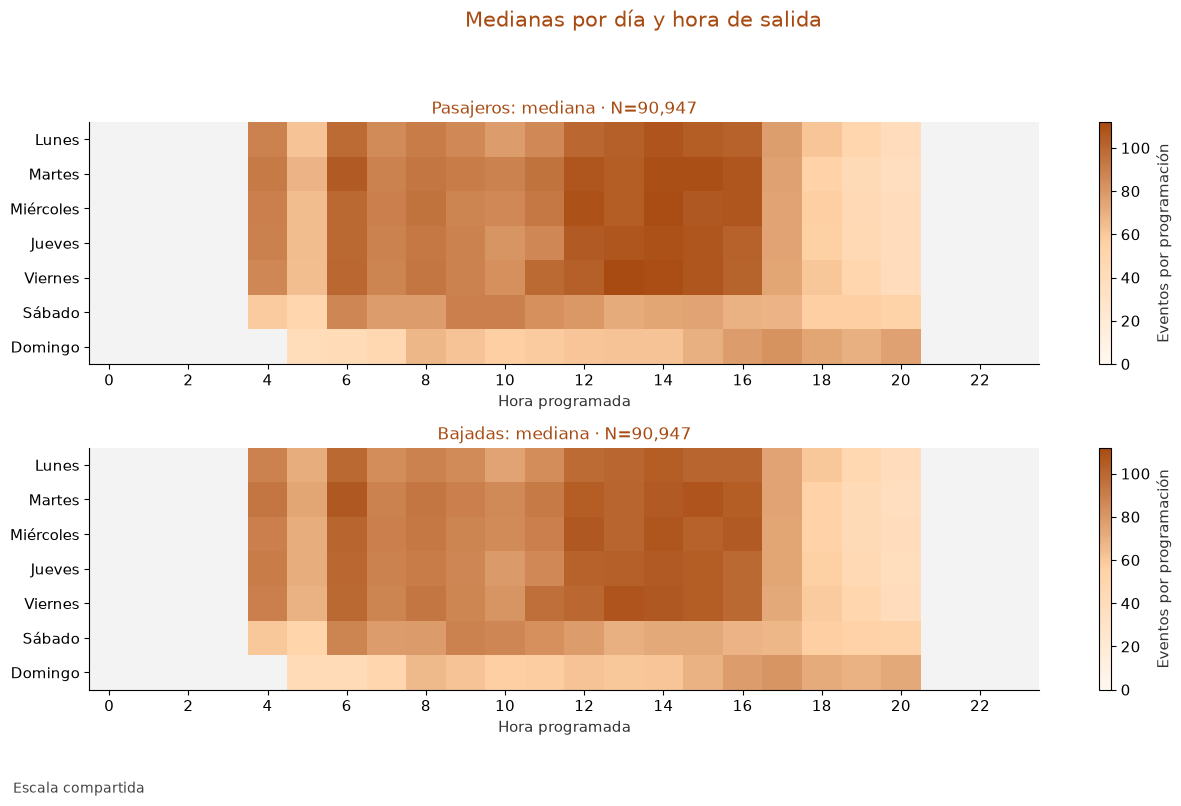

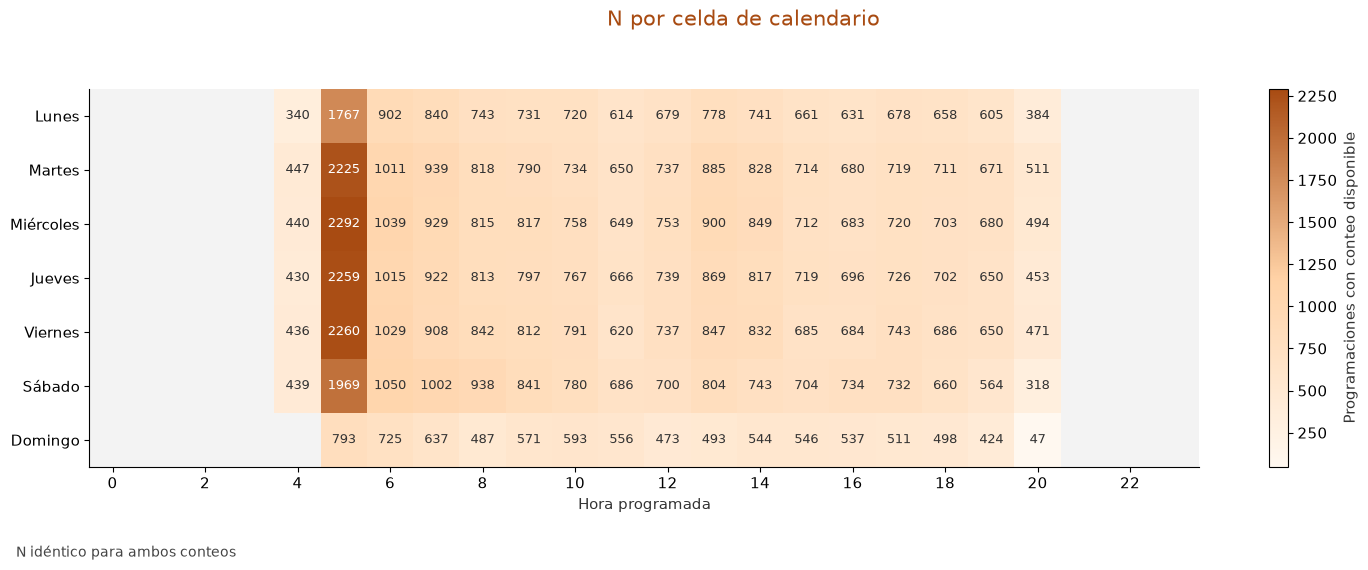

In [41]:
mapas10={}
for var in ['numeropasajeros','numerobajadas']:
    q=p9.loc[m9[var],['dia','hora',var]].copy();q[var]=numeros(q[var]);q=q.loc[q[var].notna()&np.isfinite(q[var])]
    g=q.groupby(['dia','hora'],observed=True)[var].agg(N='size',Media='mean',Mediana='median').reset_index()
    tabla(OUT_EDA,'10_2_mapa_'+var,g,n=7)
    mapas10[var]={'mediana':g.pivot(index='dia',columns='hora',values='Mediana').reindex(index=range(7),columns=range(24)),
       'N':g.pivot(index='dia',columns='hora',values='N').reindex(index=range(7),columns=range(24))}
fig,axes=plt.subplots(2,1,figsize=(13,8))
max_color=max(float(x['mediana'].max().max()) for x in mapas10.values())
for ax,(var,data) in zip(axes,mapas10.items()):
    im=ax.imshow(data['mediana'],cmap=MAPA,aspect='auto',vmin=0,vmax=max_color)
    ax.set_xticks(range(0,24,2),range(0,24,2));ax.set_yticks(range(7),ORDEN_DIAS9);ax.set(xlabel='Hora programada',title={'numeropasajeros':'Pasajeros','numerobajadas':'Bajadas'}[var]+f': mediana · N={int(m9[var].sum()):,}')
    fig.colorbar(im,ax=ax,label='Eventos por programación')
figura(OUT_EDA,'10_2_mapas_mediana',fig,'Medianas por día y hora de salida','Escala compartida. Gris: sin observaciones, distinto de cero registrado. N por celda en el mapa complementario y CSV.')
iguales=mapas10['numeropasajeros']['N'].equals(mapas10['numerobajadas']['N'])
for var,data in list(mapas10.items())[:1] if iguales else mapas10.items():
    fig,ax=plt.subplots(figsize=(15,5.6));im=ax.imshow(data['N'],cmap=MAPA,aspect='auto')
    ax.set_xticks(range(0,24,2),range(0,24,2));ax.set_yticks(range(7),ORDEN_DIAS9);ax.set_xlabel('Hora programada')
    for i in range(7):
        for j in range(24):
            val=data['N'].iloc[i,j]
            if pd.notna(val):ax.text(j,i,str(int(val)),ha='center',va='center',fontsize=9,color='white' if val>data['N'].max().max()*.65 else '#333333')
    fig.colorbar(im,ax=ax,label='Programaciones con conteo disponible')
    figura(OUT_EDA,'10_2_mapa_N_'+var,fig,'N por celda de calendario','N idéntico para ambos conteos. Gris: sin registros; distinto de cero.' if iguales else f'N específico de {var}. Gris: sin observaciones.')
narrativa(OUT_EDA,'10_2_mapas','Los mapas muestran variación conjunta por día y hora, no un efecto independiente de cada dimensión. La disponibilidad debe acompañar las medianas: las celdas grises no son conteos cero. El calendario de salida no identifica todos los momentos de abordaje, y no se asignan festividades no validadas.')

**Lectura del resultado.** Los mapas muestran variación conjunta por día y hora, no un efecto independiente de cada dimensión. La disponibilidad debe acompañar las medianas: las celdas grises no son conteos cero. El calendario de salida no identifica todos los momentos de abordaje, y no se asignan festividades no validadas.

### **10.3. Conteos frente a asignación de vehículo**

Unidad: programación seleccionada por variable. El vehículo es categoría de asignación; no se estima un efecto causal. Se exportan todos los vehículos y se muestran los 12 con mayor suma de N disponibles en ambas selecciones, no los de mayor conteo. Etiquetas anónimas para lectura; la correspondencia queda en CSV.

Variable,grupo,N_universo,Seleccionadas_criterio,Faltantes_universo,No_finitos_universo,N,Media,Mediana,DE_muestral,Min,Max,Total_registrado,Q1,Q3,IQR,Porcentaje_cobertura,Etiqueta
numeropasajeros,SOBUSA03,37,33,0,0,33,71.55,65.00,37.37,0.00,154.00,"2,361.00",49.00,99.00,50.00,89.19,V001
numeropasajeros,SOBUSA05,38,33,0,0,33,65.48,61.00,28.03,0.00,113.00,"2,161.00",49.00,87.00,38.00,86.84,V002
numeropasajeros,SOBUSA06,6,6,0,0,6,86.50,83.50,28.68,44.00,127.00,519.00,75.25,102.25,27.00,100.00,V003
numeropasajeros,SOBUSA07,1,1,0,0,1,45.00,45.00,No evaluable,45.00,45.00,45.00,45.00,45.00,0.00,100.00,V004
numeropasajeros,SOBUSA08,3,1,1,0,1,60.00,60.00,No evaluable,60.00,60.00,60.00,60.00,60.00,0.00,33.33,V005


Vista: 5 de 706 filas. Detalle completo: tablas/10_3_vehiculos_completo.csv


Variable,grupo,N_universo,Seleccionadas_criterio,Faltantes_universo,No_finitos_universo,N,Media,Mediana,DE_muestral,Min,Max,Total_registrado,Q1,Q3,IQR,Porcentaje_cobertura,Etiqueta
numeropasajeros,SOBUSA13,"1,333","1,278",16,0,"1,278",90.93,91.00,36.92,0.00,216.00,"116,205.00",64.00,117.00,53.00,95.87,V027
numeropasajeros,SOBUSA180,"1,346","1,295",22,0,"1,295",80.19,82.00,39.11,0.00,207.00,"103,849.00",53.00,109.00,56.00,96.21,V048
numeropasajeros,SOBUSA285,"1,413","1,255",26,0,"1,255",89.44,89.00,41.03,0.00,234.00,"112,252.00",59.00,118.50,59.50,88.82,V107
numeropasajeros,SOBUSA363,"1,350","1,244",15,0,"1,244",81.25,81.00,39.16,0.00,215.00,"101,081.00",53.00,108.00,55.00,92.15,V162
numeropasajeros,SOBUSA445,"1,357","1,259",15,0,"1,259",82.08,84.00,37.94,0.00,192.00,"103,339.00",55.50,108.00,52.50,92.78,V205
numeropasajeros,SOBUSA448,"1,343","1,286",24,0,"1,286",87.55,84.00,41.24,0.00,218.00,"112,592.00",57.00,115.75,58.75,95.76,V208
numeropasajeros,SOBUSA471,"1,446","1,266",19,0,"1,266",90.71,90.00,41.42,0.00,398.00,"114,837.00",62.00,121.00,59.00,87.55,V224
numeropasajeros,SOBUSA480,"1,468","1,368",14,0,"1,368",79.08,79.00,36.80,0.00,213.00,"108,180.00",52.75,105.00,52.25,93.19,V229
numeropasajeros,SOBUSA497,"1,577","1,396",27,0,"1,396",88.42,88.00,39.75,0.00,211.00,"123,441.00",60.00,114.00,54.00,88.52,V246
numeropasajeros,SOBUSA534,"1,429","1,320",23,0,"1,320",85.11,83.00,38.93,0.00,230.00,"112,339.00",56.00,112.00,56.00,92.37,V273


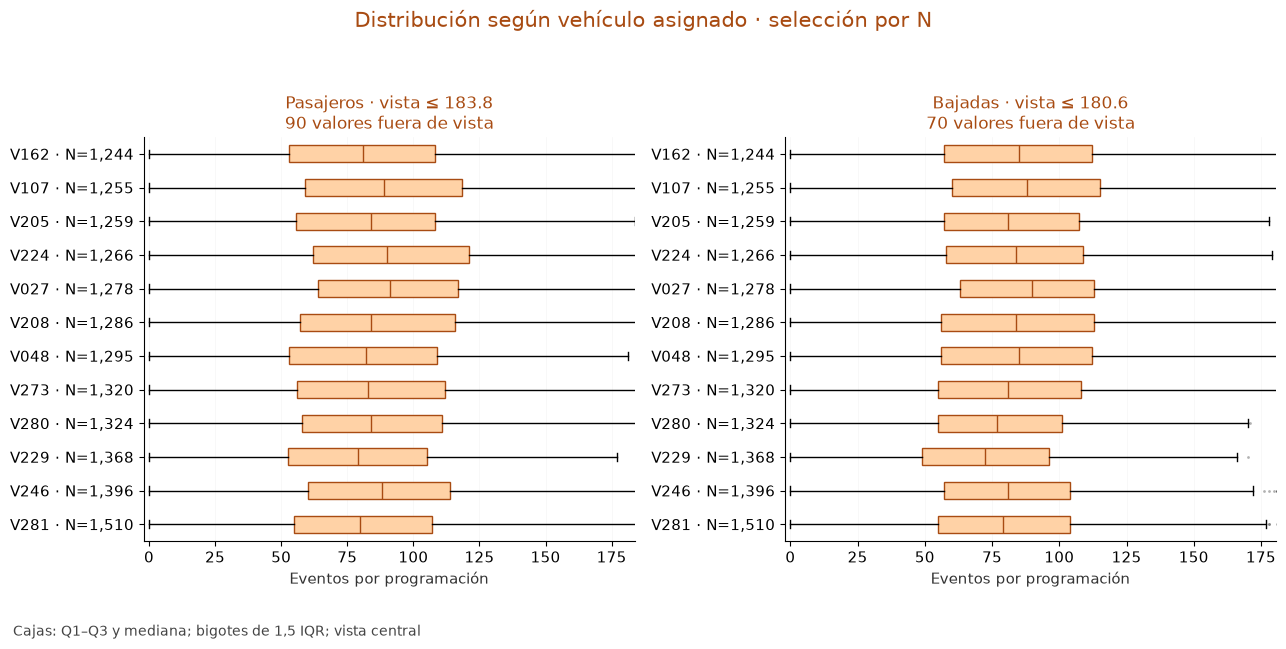

Variable,En_vehiculos_mostrados,N,Max
numerobajadas,False,416,"1,107,795"
numerobajadas,True,70,363
numeropasajeros,False,425,747
numeropasajeros,True,90,398


In [42]:
anonimos9={v:f'V{i+1:03d}' for i,v in enumerate(sorted(v9.idvehiculo.dropna().astype(str)))}
GV10=[]
for var in ['numeropasajeros','numerobajadas']:
    g=grupos(p9,var,'idvehiculo',m9[var]);g.insert(0,'Variable',var);g['Etiqueta']=g.grupo.astype(str).map(anonimos9);GV10.append(g)
gv10=pd.concat(GV10,ignore_index=True)
seleccion_veh=gv10.groupby('grupo').N.sum().sort_values(ascending=False).head(12).index
vista_veh=gv10.loc[gv10.grupo.isin(seleccion_veh)]
tabla(OUT_EDA,'10_3_vehiculos_completo',gv10,n=5);tabla(OUT_EDA,'10_3_vehiculos_seleccion',vista_veh,n=len(vista_veh))
fig,axes=plt.subplots(1,2,figsize=(13,6.4))
for ax,var in zip(axes,['numeropasajeros','numerobajadas']):
    datos=[numeros(p9.loc[m9[var]&p9.idvehiculo.eq(v),var]).to_numpy() for v in seleccion_veh]
    labels=[f'{anonimos9[str(v)]} · N={len(x):,}' for v,x in zip(seleccion_veh,datos)]
    ax.boxplot(datos,orientation='horizontal',tick_labels=labels,showfliers=True,patch_artist=True,
        boxprops={'facecolor':CLARO,'edgecolor':OSCURO},medianprops={'color':OSCURO},flierprops={'marker':'.','markersize':2,'alpha':.3})
    ax.set(title={'numeropasajeros':'Pasajeros','numerobajadas':'Bajadas'}[var],xlabel='Eventos por programación');ax.grid(axis='x',alpha=.4)
    # Puntos de fliers dibujados; solo los límites de vista amplían el centro.
    centro_veh=max(1,numeros(p9.loc[m9[var],var]).quantile(.99))
    ax.set_xlim(-2,centro_veh*1.05)
    fuera=sum(int((x>centro_veh*1.05).sum()) for x in datos)
    ax.set_title({'numeropasajeros':'Pasajeros','numerobajadas':'Bajadas'}[var]+f' · vista ≤ {centro_veh*1.05:.1f}\n{fuera:,} valores fuera de vista')
figura(OUT_EDA,'10_3_vehiculos',fig,'Distribución según vehículo asignado · selección por N','Cajas: Q1–Q3 y mediana; bigotes de 1,5 IQR; vista central. Extremos identificados en reporte complementario; selección por N.')
nsel=int(vista_veh.loc[vista_veh.Variable.eq('numeropasajeros'),'N'].sum())

REV_VEH10=[]
for var in ['numeropasajeros','numerobajadas']:
    limite=numeros(p9.loc[m9[var],var]).quantile(.99)*1.05
    mask=m9[var]&p9[var].gt(limite)
    z=p9.loc[mask,['idprogramacion','idvehiculo','fechasalida',var]].rename(columns={var:'Valor'}).copy()
    z['Variable']=var;z['En_vehiculos_mostrados']=z.idvehiculo.isin(seleccion_veh);z['Limite_vista']=limite
    REV_VEH10.append(z)
revision_veh10=pd.concat(REV_VEH10,ignore_index=True)
revision_veh10.to_parquet(OUT_EDA/'incidencias/extremos_vista_vehiculos.parquet',index=False)
res_veh10=revision_veh10.groupby(['Variable','En_vehiculos_mostrados']).agg(N=('Valor','size'),Max=('Valor','max')).reset_index()
tabla(OUT_EDA,'10_3_extremos_fuera_vista',res_veh10,len(res_veh10))
narrativa(OUT_EDA,'10_3_vehiculos',f'Los doce vehículos con mayor N conjunto concentran {nsel:,}/{int(m9["numeropasajeros"].sum()):,} registros de pasajeros seleccionados. La vista central declara límites y casos fuera de vista; todos sus valores, máximos e identificadores quedan en tablas e incidencias. No se atribuyen diferencias a efectos propios: fechas, horarios y asignaciones pueden intervenir, y el catálogo carece de vigencia histórica confirmada.')

**Lectura del resultado.** Los doce vehículos con mayor N conjunto concentran 15,801/90,947 registros de pasajeros seleccionados. La vista central declara límites y casos fuera de vista; todos sus valores, máximos e identificadores quedan en tablas e incidencias. No se atribuyen diferencias a efectos propios: fechas, horarios y asignaciones pueden intervenir, y el catálogo carece de vigencia histórica confirmada.

**Categorías pertinentes y límites del catálogo actual**

Se comprueba tipo/grupo de programación y un atributo declarado de vehículo, sin convertir códigos en medidas. Solo se grafica tipo de carrocería si hay al menos dos categorías con N≥30; 30 es un mínimo de presentación, no regla de validez ni exclusión de las tablas completas.

In [43]:
lim_cat=[]
for c in ['tipo','grupo']:
    lim_cat.append({'Campo':c,'N_presentes':int(p9[c].notna().sum()),'Categorias':p9[c].nunique(),'Decision':'Sin comparación si ausente o constante'})
assert v9.idvehiculo.is_unique and v9.idvehiculo.notna().all()
atributos10=p9[['idprogramacion','idvehiculo','numeropasajeros','numerobajadas']].merge(v9[['idvehiculo','tipo_carroceria']],on='idvehiculo',how='left',validate='many_to_one')
assert len(atributos10)==len(p9) and atributos10.idprogramacion.equals(p9.idprogramacion)
atributos10['categoria']=atributos10.tipo_carroceria.astype('string').fillna('[Ausente]')
catg=grupos(atributos10,'numeropasajeros','categoria',m9['numeropasajeros']);tabla(OUT_EDA,'10_3_carroceria',catg,n=len(catg))
legibles=catg.loc[catg.N.ge(30)&catg.grupo.ne('[Ausente]')]
if len(legibles)>=2:
    fig,ax=plt.subplots(figsize=(8,4));xx=np.arange(len(legibles))
    ax.errorbar(xx,legibles.Mediana,yerr=[legibles.Mediana-legibles.Q1,legibles.Q3-legibles.Mediana],fmt='o',color=OSCURO,capsize=5)
    ax.set_xticks(xx,[f'{x}\nN={int(nn):,}' for x,nn in zip(legibles.grupo,legibles.N)]);ax.set_ylabel('Pasajeros registrados por programación');ax.grid(axis='y',alpha=.4)
    figura(OUT_EDA,'10_3_carroceria',fig,'Atributo declarado de carrocería y conteos','Mediana y Q1–Q3. Atributo del catálogo extraído; vigencia histórica no confirmada.')
else:lim_cat.append({'Campo':'tipo_carroceria','N_presentes':int(atributos10.tipo_carroceria.notna().sum()),'Categorias':len(legibles),'Decision':'Sin gráfico: menos de dos categorías comparables'})
tabla(OUT_EDA,'10_3_categorias_no_comparables',pd.DataFrame(lim_cat),len(lim_cat))
narrativa(OUT_EDA,'10_3_categorias','Las variables ausentes o constantes no sostienen contrastes. La integración conserva una fila por programación y no multiplica conteos. Cualquier comparación con carrocería describe el atributo extraído, sin acreditar que ese valor estuviera vigente en la fecha de cada programación; no se usan estados actuales para reconstruir historia.')

grupo,N_universo,Seleccionadas_criterio,Faltantes_universo,No_finitos_universo,N,Media,Mediana,DE_muestral,Min,Max,Total_registrado,Q1,Q3,IQR,Porcentaje_cobertura
[Ausente],"101,883","90,947","1,736",0,"90,947",81.96,81.00,39.00,0.00,747.00,"7,453,982.00",54.00,108.00,54.00,89.27


Campo,N_presentes,Categorias,Decision
tipo,0,0,Sin comparación si ausente o constante
grupo,0,0,Sin comparación si ausente o constante
tipo_carroceria,0,0,Sin gráfico: menos de dos categorías comparables


**Lectura del resultado.** Las variables ausentes o constantes no sostienen contrastes. La integración conserva una fila por programación y no multiplica conteos. Cualquier comparación con carrocería describe el atributo extraído, sin acreditar que ese valor estuviera vigente en la fecha de cada programación; no se usan estados actuales para reconstruir historia.

### **10.4. ¿Cómo se combinan finalización y cancelación?**

Unidad: programación. Población: todas las programaciones; no se aplica previamente S/N. Contingencia absoluta, porcentaje del total y porcentaje por fila (denominador: cada estado de finalización). Ceros de combinaciones son frecuencias contadas, no imputación de pasajeros.

finalizado,cancelada,N,Denominador_total,Pct_total,Denominador_fila,Pct_fila
N,N,7,"101,883",0.01,"10,346",0.07
N,S,"10,339","101,883",10.15,"10,346",99.93
S,N,"91,537","101,883",89.85,"91,537",100.00
S,S,0,"101,883",0.00,"91,537",0.00


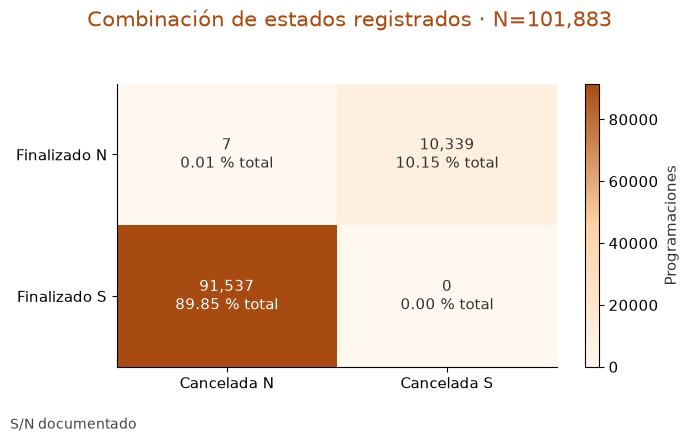

In [44]:
cruce10=pd.crosstab(p9.finalizado.astype('string').fillna('[Ausente]'),p9.cancelada.astype('string').fillna('[Ausente]'),dropna=False)
assert cruce10.to_numpy().sum()==len(p9)
long10=cruce10.stack().rename('N').reset_index();long10['Denominador_total']=len(p9);long10['Pct_total']=100*long10.N/len(p9)
long10['Denominador_fila']=long10.finalizado.map(cruce10.sum(axis=1));long10['Pct_fila']=100*long10.N/long10.Denominador_fila
tabla(OUT_EDA,'10_4_estados',long10,n=len(long10))
fig,ax=plt.subplots(figsize=(7,4.3));im=ax.imshow(cruce10,cmap=MAPA,aspect='auto');fig.colorbar(im,ax=ax,label='Programaciones')
ax.set_xticks(range(len(cruce10.columns)),[f'Cancelada {x}' for x in cruce10.columns]);ax.set_yticks(range(len(cruce10.index)),[f'Finalizado {x}' for x in cruce10.index])
for i in range(len(cruce10)):
    for j in range(len(cruce10.columns)):
        n=cruce10.iloc[i,j];ax.text(j,i,f'{n:,}\n{100*n/len(p9):.2f} % total',ha='center',va='center',color='white' if n>cruce10.to_numpy().max()*.65 else '#333333',fontsize=11)
figura(OUT_EDA,'10_4_estados',fig,f'Combinación de estados registrados · N={len(p9):,}','S/N documentado. La tabla exporta también porcentajes por fila; no se asume complementariedad.')
ambos_no=int(((p9.finalizado=='N')&(p9.cancelada=='N')).sum())
narrativa(OUT_EDA,'10_4',f'Hay {ambos_no:,} programaciones no finalizadas y no canceladas. Los estados no se tratan como complementarios por definición y se conservan todas sus combinaciones. Los porcentajes por fila responden una pregunta distinta a los del universo completo; describen estados registrados, no motivos de operación ni calidad de conteos.')

**Lectura del resultado.** Hay 7 programaciones no finalizadas y no canceladas. Los estados no se tratan como complementarios por definición y se conservan todas sus combinaciones. Los porcentajes por fila responden una pregunta distinta a los del universo completo; describen estados registrados, no motivos de operación ni calidad de conteos.

### **10.5. Detalle por segmentos dentro de su cobertura**

Unidad: registro segmento–programación en enero–febrero de 2023. El diccionario declara subidas y bajadas específicamente en el segmento para ese viaje, no lecturas acumuladas. Se suman como conteos declarados por registro, con esa limitación documental. Antes de integrar se verifica unicidad de segmento y de la pareja segmento–programación.

Campo,Descripcion,Significado,Interpretacion_suma
subidas,Subidas en el segmento para ese viaje.,"Cantidad de pasajeros que subieron específicamente en este segmento, durante este viaje puntual.",Conteos declarados por registro; no acumuladas según diccionario
bajadas,Bajadas en el segmento para ese viaje.,"Cantidad de pasajeros que bajaron específicamente en este segmento, durante este viaje puntual.",Conteos declarados por registro; no acumuladas según diccionario


id_segmento,nro_segmento,N_registros,Programaciones_distintas,Faltantes,No_finitos,Negativos,N_utilizados,Media,Mediana,DE_muestral,Suma_registrada,Q1,Q3,N_presentes,No_comparables,Variable
"1,684",1,"4,082","4,082",0,0,0,"4,082",0.33,0.00,1.23,"1,331.00",0.00,0.00,"4,082",0,bajadas
"1,685",2,"3,464","3,464",0,0,0,"3,464",0.31,0.00,0.83,"1,061.00",0.00,0.00,"3,464",0,bajadas
"1,686",3,"2,278","2,278",0,0,0,"2,278",1.15,1.00,1.37,"2,624.00",0.00,2.00,"2,278",0,bajadas
"1,687",4,746,746,0,0,0,746,0.03,0.00,0.19,19.00,0.00,0.00,746,0,bajadas
"1,688",5,"3,628","3,628",0,0,0,"3,628",0.03,0.00,0.26,101.00,0.00,0.00,"3,628",0,bajadas
"1,689",6,"4,014","4,014",0,0,0,"4,014",0.06,0.00,0.41,257.00,0.00,0.00,"4,014",0,bajadas
"1,690",7,"3,587","3,587",0,0,0,"3,587",0.06,0.00,0.41,210.00,0.00,0.00,"3,587",0,bajadas
"1,691",8,"3,722","3,722",0,0,0,"3,722",0.04,0.00,0.27,143.00,0.00,0.00,"3,722",0,bajadas


Vista: 8 de 256 filas. Detalle completo: tablas/10_5_segmentos.csv


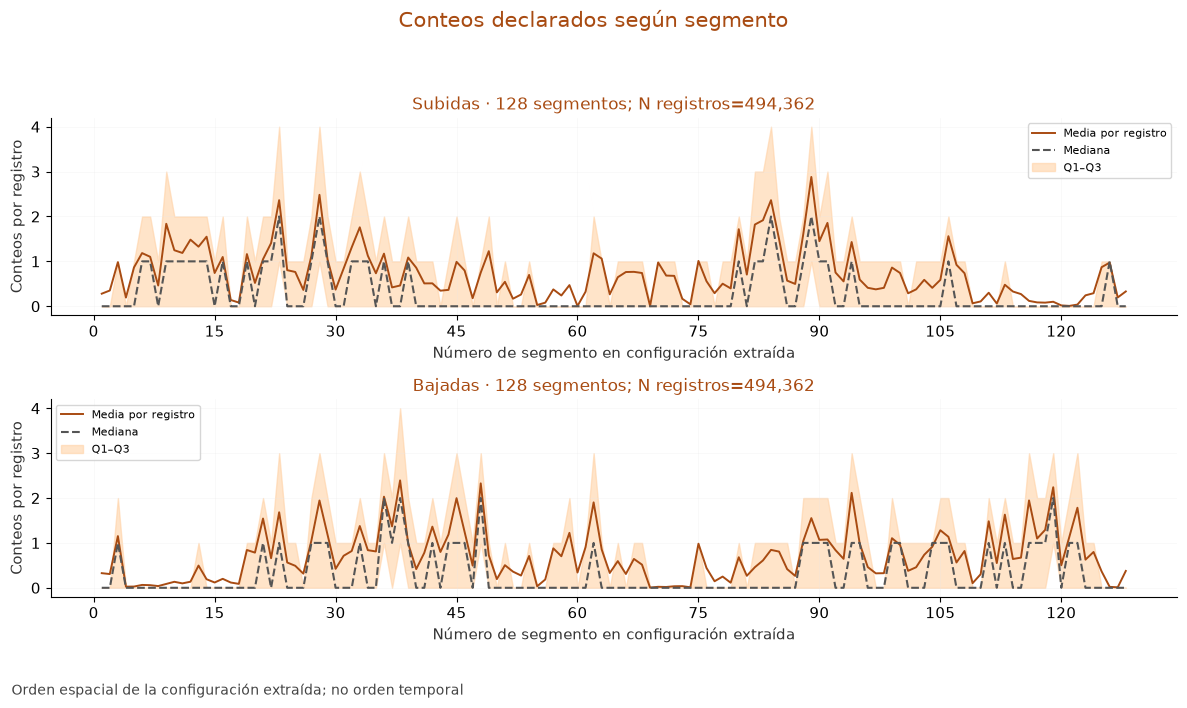

Variable,Registros,Utilizados,Faltantes,No_finitos,Negativos,No_comparables
bajadas,"494,362","494,362",0,0,0,0
subidas,"494,362","494,362",0,0,0,0


In [45]:
assert not t9.duplicated(['id_segmento','id_viaje']).any()
assert rs9.id.is_unique and rs9.id.notna().all()
evidencia10=pd.DataFrame([{'Campo':c,'Descripcion':DOC['timbradas_segmentos'][c]['descripcion'],'Significado':DOC['timbradas_segmentos'][c]['significado'],'Interpretacion_suma':'Conteos declarados por registro; no acumuladas según diccionario'} for c in ['subidas','bajadas']])
tabla(OUT_EDA,'10_5_evidencia_eventos',evidencia10,2)
det10=t9[['id_segmento','id_viaje','subidas','bajadas','fecha']].merge(rs9[['id','nro_segmento','idruta']].rename(columns={'id':'id_segmento'}),on='id_segmento',how='left',validate='many_to_one')
assert len(det10)==len(t9) and det10.idruta.eq(21).all()
SEG10=[]
for var in ['subidas','bajadas']:
    g=det10.groupby(['id_segmento','nro_segmento'],observed=True)
    base=g.agg(N_registros=('id_viaje','size'),Programaciones_distintas=('id_viaje','nunique'))
    val=numeros(det10[var]);valida=val.notna()&np.isfinite(val)
    det10['valor']=val.where(valida);det10['faltante']=val.isna();det10['no_finito']=val.notna()&~np.isfinite(val);det10['negativo']=val.lt(0)
    calidad=det10.groupby(['id_segmento','nro_segmento'],observed=True).agg(Faltantes=('faltante','sum'),No_finitos=('no_finito','sum'),Negativos=('negativo','sum'))
    gg=det10.groupby(['id_segmento','nro_segmento'],observed=True).valor
    a=base.join(calidad).join(gg.agg(N_utilizados='count',Media='mean',Mediana='median',DE_muestral='std'))
    a=a.join(gg.sum(min_count=1).rename('Suma_registrada')).join(gg.quantile(.25).rename('Q1')).join(gg.quantile(.75).rename('Q3')).reset_index()
    a['N_presentes']=a.N_registros-a.Faltantes;a['No_comparables']=a.Faltantes+a.No_finitos
    a['Variable']=var;SEG10.append(a)
    assert np.isclose(a.Suma_registrada.sum(min_count=1),val.loc[valida].sum(min_count=1),equal_nan=True)
seg10=pd.concat(SEG10,ignore_index=True).sort_values(['Variable','nro_segmento']);tabla(OUT_EDA,'10_5_segmentos',seg10,n=8)
fig,axes=plt.subplots(2,1,figsize=(12,7))
for ax,var in zip(axes,['subidas','bajadas']):
    g=seg10.loc[seg10.Variable.eq(var)].sort_values('nro_segmento');xx=g.nro_segmento.astype(int).to_numpy()
    ax.plot(xx,g.Media,color=OSCURO,lw=1.4,label='Media por registro');ax.plot(xx,g.Mediana,color='#555555',ls='--',label='Mediana');ax.fill_between(xx,numeros(g.Q1),numeros(g.Q3),color=CLARO,alpha=.6,label='Q1–Q3')
    ax.set(title=f'{var.capitalize()} · {len(g)} segmentos; N registros={int(g.N_registros.sum()):,}',xlabel='Número de segmento en configuración extraída',ylabel='Conteos por registro');ax.xaxis.set_major_locator(MaxNLocator(10,integer=True));ax.grid(alpha=.35);ax.legend(fontsize=8)
figura(OUT_EDA,'10_5_segmentos',fig,'Conteos declarados según segmento','Orden espacial de la configuración extraída; no orden temporal. N y programaciones distintas por segmento en CSV. No extrapolar a 2023–2025.')

calidad_seg10=seg10.groupby('Variable').agg(Registros=('N_registros','sum'),Utilizados=('N_utilizados','sum'),Faltantes=('Faltantes','sum'),No_finitos=('No_finitos','sum'),Negativos=('Negativos','sum'),No_comparables=('No_comparables','sum')).reset_index()
tabla(OUT_EDA,'10_5_calidad_segmentos',calidad_seg10,len(calidad_seg10))
assert int(calidad_seg10.Registros.sum())==2*len(t9)
narrativa(OUT_EDA,'10_5',f'El detalle contiene {len(t9):,} registros de {t9.id_viaje.nunique():,} programaciones de enero–febrero de 2023, con {int(seg10.N_registros.min()):,}–{int(seg10.N_registros.max()):,} registros por segmento. El diccionario define eventos en segmento; la tabla separa ausencias, no finitos y negativos antes de sumar los valores disponibles, sin convertirlos en ceros. La interpretación documental no demuestra calidad de sensores ni autoriza extrapolación.')

**Lectura del resultado.** El detalle contiene 494,362 registros de 4,649 programaciones de enero–febrero de 2023, con 746–4,481 registros por segmento. El diccionario define eventos en segmento; la tabla separa ausencias, no finitos y negativos antes de sumar los valores disponibles, sin convertirlos en ceros. La interpretación documental no demuestra calidad de sensores ni autoriza extrapolación.

**Conciliación del detalle agregado una vez por programación**

Se agrega primero el detalle a id_viaje y después se contrasta con una única fila de programación. No se repiten atributos de programación por segmento ni se heredan filtros S/N. Es una comparación diagnóstica entre mediciones con distinta cobertura, no una prueba de igualdad obligatoria.

Comparacion,Programaciones_con_detalle,N_comparables,No_comparables,Iguales,Discrepan,Diferencia_media,Diferencia_mediana
Diferencia_subidas,"4,649","4,645",4,"3,150","1,495",0.33,0.00
Diferencia_bajadas,"4,649","4,645",4,"4,601",44,0.02,0.00


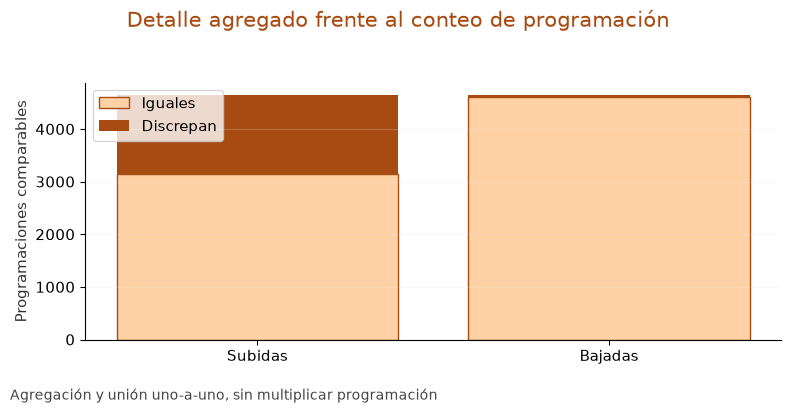

In [46]:
por_viaje10=t9.groupby('id_viaje',observed=True).agg(Registros=('id_timbrada_segmento','size'),Segmentos=('id_segmento','nunique'))
for var,nombre in [('subidas','Subidas_detalle'),('bajadas','Bajadas_detalle')]:
    z=numeros(t9[var]);valida=z.notna()&np.isfinite(z)
    parcial=z.where(valida).groupby(t9.id_viaje,observed=True).sum(min_count=1)
    completa=valida.groupby(t9.id_viaje,observed=True).all()
    por_viaje10[nombre+'_disponible']=parcial
    por_viaje10[nombre+'_completa']=completa
    # Comparación por programación exige todos sus registros de detalle comparables.
    por_viaje10[nombre]=parcial.where(completa)
por_viaje10=por_viaje10.reset_index()
assert por_viaje10.id_viaje.is_unique
comp10=por_viaje10.merge(p9[['idprogramacion','numeropasajeros','numerobajadas','finalizado','cancelada']],left_on='id_viaje',right_on='idprogramacion',how='left',validate='one_to_one')
assert len(comp10)==len(por_viaje10)
comp10['Diferencia_subidas']=numeros(comp10.Subidas_detalle)-numeros(comp10.numeropasajeros)
comp10['Diferencia_bajadas']=numeros(comp10.Bajadas_detalle)-numeros(comp10.numerobajadas)
comp10.to_parquet(OUT_EDA/'incidencias/conciliacion_detalle_programacion.parquet',index=False)
RES_COMP10=[]
for c in ['Diferencia_subidas','Diferencia_bajadas']:
    z=numeros(comp10[c]);ok=z.notna()&np.isfinite(z)
    RES_COMP10.append({'Comparacion':c,'Programaciones_con_detalle':len(comp10),'N_comparables':int(ok.sum()),'No_comparables':int((~ok).sum()),'Iguales':int(z.loc[ok].eq(0).sum()),'Discrepan':int(z.loc[ok].ne(0).sum()),'Diferencia_media':z.loc[ok].mean(),'Diferencia_mediana':z.loc[ok].median()})
tabla(OUT_EDA,'10_5_conciliacion_por_viaje',pd.DataFrame(RES_COMP10),2)
fig,ax=plt.subplots(figsize=(8,4));g=pd.DataFrame(RES_COMP10);xx=np.arange(2)
ax.bar(xx,g.Iguales,label='Iguales',color=CLARO,edgecolor=OSCURO);ax.bar(xx,g.Discrepan,bottom=g.Iguales,label='Discrepan',color=OSCURO)
ax.set_xticks(xx,['Subidas','Bajadas']);ax.set_ylabel('Programaciones comparables');ax.legend();ax.grid(axis='y',alpha=.35)
figura(OUT_EDA,'10_5_conciliacion_viajes',fig,'Detalle agregado frente al conteo de programación','Agregación y unión uno-a-uno, sin multiplicar programación. Sin filtros heredados. Igualdad no valida sensores; diferencia no prueba error.')
narrativa(OUT_EDA,'10_5_conciliacion','La comparación mantiene una observación por programación y separa campos ausentes. Las discrepancias pueden acompañar segmentación incompleta o definiciones distintas; son hipótesis pendientes, no causas demostradas. Las programaciones sin detalle quedan fuera de esta comparación por falta de medición, no como ceros.')

**Lectura del resultado.** La comparación mantiene una observación por programación y separa campos ausentes. Las discrepancias pueden acompañar segmentación incompleta o definiciones distintas; son hipótesis pendientes, no causas demostradas. Las programaciones sin detalle quedan fuera de esta comparación por falta de medición, no como ceros.

### **10.6. Duración registrada frente a conteos: diagnóstico condicionado**

Unidad: programación. Intersección de la selección de duración positiva y la selección independiente del conteo. No se impone rango 60–480 minutos, distancia ni umbral de 500. La duración registrada no se confirma como recorrido/ciclo; no se realiza inferencia suponiendo independencia.

N_pares,Pearson,Spearman
"90,931",0.0561,0.5868


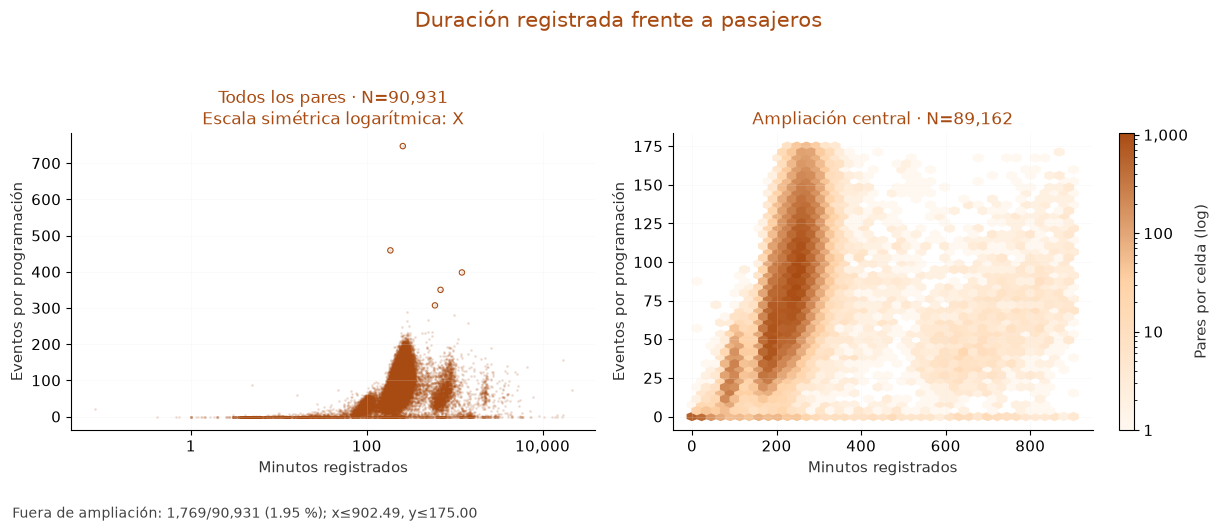

N_pares,Pearson,Spearman
"90,931",-0.0006,0.5588


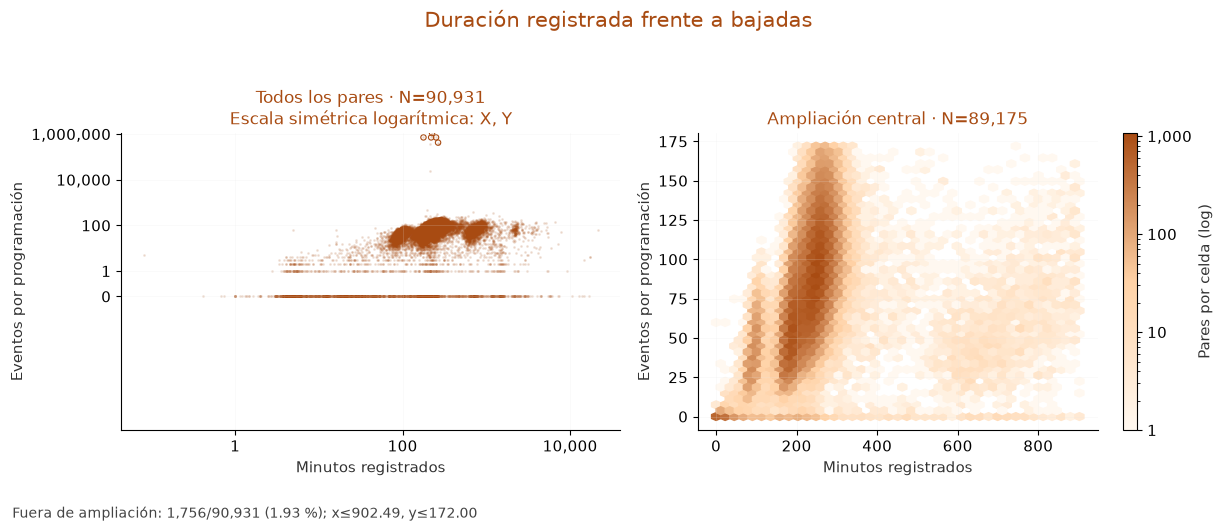

Poblacion,Variable,N_pares,Pearson,Spearman
"Principal, sin recorte",numeropasajeros,"90,931",0.0561,0.5868
Sensibilidad: ambas fechas dentro de ventana,numeropasajeros,"90,927",0.0589,0.5869
"Principal, sin recorte",numerobajadas,"90,931",-0.0006,0.5588
Sensibilidad: ambas fechas dentro de ventana,numerobajadas,"90,927",-0.0006,0.5589


In [47]:
REL_DUR10=[]
for var in ['numeropasajeros','numerobajadas']:
    mask=m9['duracion']&m9[var]
    r=relaciones(OUT_EDA,'10_6_duracion_'+var,duracion9.loc[mask],p9.loc[mask,var],'Duración registrada frente a '+{'numeropasajeros':'pasajeros','numerobajadas':'bajadas'}[var],['Minutos registrados','Eventos por programación'])
    r['Variable']=var;r['Poblacion']='Principal, sin recorte';REL_DUR10.append(r)
    sens=mask&~fuera_tiempo9
    x=numeros(duracion9.loc[sens]);y=numeros(p9.loc[sens,var])
    REL_DUR10.append({'Variable':var,'Poblacion':'Sensibilidad: ambas fechas dentro de ventana',**correlaciones(x,y)})
tabla(OUT_EDA,'10_6_sensibilidad_cierre',pd.DataFrame(REL_DUR10),4)
narrativa(OUT_EDA,'10_6',f'Las asociaciones principales usan todos los pares aprobados, incluidos extremos. La sensibilidad aparta {int((m9["duracion"]&m9["numeropasajeros"]&fuera_tiempo9).sum()):,} pares de pasajeros solo por el cierre temporal y permite reconocer cuánto cambia el resultado. No constituye limpieza ni demuestra una relación causal entre duración y conteos. Distancia queda pendiente por unidad no confirmada; capacidad no habilita ocupación.')

**Lectura del resultado.** Con los pares principales, Spearman es 0.587 para pasajeros y 0.559 para bajadas, mientras las asociaciones lineales son débiles. Eso no acredita un efecto de tiempo de recorrido: inicio–fin puede representar otra unidad operativa. La sensibilidad al cierre aparta cuatro pares de pasajeros y mantiene por separado el análisis principal, sin alterar selecciones ni afirmar causalidad.

### **10.7. Síntesis, controles y preguntas posteriores**

Se comprueba conservación de archivos y poblaciones, cobertura real de variables y consistencia de las figuras. No se anuncian resultados predictivos ni se realizan pruebas inferenciales sin tratar la dependencia por vehículo/fecha.

In [48]:
for rel,h in HUELLAS_EDA.items():
    assert hashlib.sha256((BASE_EDA/rel).read_bytes()).hexdigest()==h,'RAW modificado: '+rel
assert np.array_equal(m9['numeropasajeros'].to_numpy(dtype=bool),prep9.seleccion_pasajeros.to_numpy(dtype=bool))
assert len(p9)==len(prep9) and int(pares9.sum())==r_pares['N_pares']
for var in ['numeropasajeros','numerobajadas']:
    assert gv10.loc[gv10.Variable.eq(var),'N'].sum()==m9[var].sum()
assert a9.loc[a9.ano.isin([2023,2024,2025]),'ano'].isin([2023,2024,2025]).all()
INVENTARIO9=cobertura_artefactos(OUT_EDA,INVENTARIO9)
tabla(OUT_EDA,'10_7_cobertura_final',INVENTARIO9,n=6)
res=INVENTARIO9.groupby('Estado').size().rename('Columnas').reset_index()
tabla(OUT_EDA,'10_7_resumen_cobertura',res,len(res))
controles=pd.DataFrame([{'Control':'Máscaras aprobadas por identificador','Resultado':'Coinciden'},
 {'Control':'Ruta, proceso y ventana por salida','Resultado':'21 / sobusa / 2023–2025'},
 {'Control':'Originales conservados en preparada','Resultado':'Cada columna coincide'},
 {'Control':'RAW SHA256','Resultado':f'{len(HUELLAS_EDA)} archivos intactos'},
 {'Control':'Uniones vehículo y segmento','Resultado':'many_to_one, sin multiplicación'},
 {'Control':'Detalle agregado a programación','Resultado':'one_to_one, sin multiplicación'},
 {'Control':'N y sumas por calendario/vehículo','Resultado':'Conciliados con selección'},
 {'Control':'Año 2026','Resultado':'Perfil separado; no incluido en principal'},
 {'Control':'Campos no habilitados','Resultado':'Sin ocupación, distancia operativa, fiestas ni predicción'}])
tabla(OUT_EDA,'10_7_controles',controles,len(controles))
pendientes=pd.DataFrame([{'Tema':'Dependencia','Decision':'Tratar repetición por vehículo/fecha antes de inferencia; aquí solo descripción'},
 {'Tema':'Carga y capacidad','Decision':'Confirmar medición y capacidad vigente; no usar conteos acumulados como ocupación'},
 {'Tema':'Duración/distancia','Decision':'Confirmar unidad operativa y unidades físicas antes de interpretar ciclo o viaje completo'},
 {'Tema':'Tiempo','Decision':'Confirmar hora local original y momento real de medición antes de usar franjas de salida como abordajes'},
 {'Tema':'Calendario/agregados','Decision':'Confirmar aplicabilidad, período y aditividad; sin fiestas ni medias globales ponderadas no justificadas'},
 {'Tema':'Modelado posterior','Decision':'Definir objetivo, disponibilidad temporal y evaluación cronológica; estados finales y conteos no son predictores previos'}])
tabla(OUT_EDA,'10_7_pendientes',pendientes,len(pendientes))
(OUT_EDA/'configuracion_analisis.json').write_text(json.dumps({'ruta':21,'nombre':'CL 72','extraccion':str(BASE_EDA.relative_to(PROYECTO_EDA)),'run_eda':RUN_EDA,'zona':'America/Bogota','sin_PostgreSQL':True,'sin_modificar_RAW':True,'criterios':'ruta21-v1','figuras':len(json.loads((OUT_EDA/'figuras.json').read_text()))},ensure_ascii=False,indent=2))
(PROYECTO_EDA/'analisis_ruta21/ultima_ejecucion_verificada.json').write_text(json.dumps({'carpeta':str(OUT_EDA),'run_eda':RUN_EDA,'extraccion':'20261013T024459_762b3a10'},indent=2))

narrativa(OUT_EDA,'10_7',f'Los {r_pares["N_pares"]:,} pares aprobados mantienen una asociación por rangos alta (Spearman {r_pares["Spearman"]:.3f}), pero solo {100*diferencia9.eq(0).mean():.2f} % son iguales. El mayor registro concentra {contribucion_extremos.iloc[0].Porcentaje_suma:.2f} % de la suma de bajadas disponible, y Pearson pasa de {r_pares["Pearson"]:.4f} a {sens_pares.iloc[2].Pearson:.4f} al apartarlo únicamente como diagnóstico de influencia. Apartar solo el mayor no resuelve la influencia del conjunto de magnitudes extremas; el análisis principal retiene todos los valores. Calendario y vehículos describen asociaciones con cobertura explícita, sin causalidad; segmentos se limitan a enero–febrero de 2023. Quedan pendientes medición de extremos, capacidades vigentes, unidades operativas, calendario y aditividad de agregados. No se calcula ocupación ni se construyen modelos.')

Tabla,Columna,Tipo_almacenado,Semantica,Estado,Motivo,Unidad_documentada,Codificacion_documentada,Descripcion,Riesgo_fuga,Filas,Presentes,Unicos_presentes,Trabajo_ejecutado,Artefactos_verificados
progvehiculos,idprogramacion,int64[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,PK de la programación/viaje (referenciado por id_viaje).,"Nulo — es un identificador, conocido antes del viaje.","101,883","101,883","101,883",Sin artefacto analítico; metadatos/identificación fuera de preguntas,Ninguno
progvehiculos,idvehiculo,string[pyarrow],Identificador; no medida continua,Análisis principal con resultados visibles,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Vehículo asignado (placa/interno).,Nulo — conocido antes del viaje (parte de la programación).,"101,883","101,883",353,Categoría de relación; sin distribución continua de ID,10_3_vehiculos_completo.csv
progvehiculos,idconductor,int64[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Conductor asignado.,Nulo — conocido antes del viaje.,"101,883","101,883",756,Sin artefacto analítico; metadatos/identificación fuera de preguntas,Ninguno
progvehiculos,idruta,int64[pyarrow],Identificador; no medida continua,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Ruta del viaje (FK rutas.idruta).,Nulo — conocido antes del viaje.,"101,883","101,883",1,Sin artefacto analítico; metadatos/identificación fuera de preguntas,Ninguno
progvehiculos,proceso,string[pyarrow],Categoría/código,Exclusión justificada,"No es necesaria para las preguntas; identificación, administración o configuración",pendiente de confirmación,No especificada en el diccionario,Proceso (sobusa).,Nulo.,"101,883","101,883",1,Sin artefacto analítico; metadatos/identificación fuera de preguntas,Ninguno
progvehiculos,fechasalida,timestamp[us][pyarrow],Temporal; significado según fuente,Análisis principal con resultados visibles,Población y filtro declarados en el bloque,pendiente de confirmación,No especificada en el diccionario,Fecha/hora programada de salida.,"Nulo — es programación, conocida con anticipación. Es la columna de tiempo natural para ordenar los viajes (útil como columna_orden en el mini-EDA).","101,883","101,883","100,553",Frecuencias temporales y cobertura visible,9_5_fechas_efectivas.csv; 9_5_diaria_programaciones.csv


Vista: 6 de 183 filas. Detalle completo: tablas/10_7_cobertura_final.csv


Estado,Columnas
Análisis principal con resultados visibles,21
"Disponibilidad comprobada, sin distribución",11
Exclusión justificada,132
Interpretación pendiente,7
Perfil secundario exportado,12


Control,Resultado
Máscaras aprobadas por identificador,Coinciden
"Ruta, proceso y ventana por salida",21 / sobusa / 2023–2025
Originales conservados en preparada,Cada columna coincide
RAW SHA256,74 archivos intactos
Uniones vehículo y segmento,"many_to_one, sin multiplicación"
Detalle agregado a programación,"one_to_one, sin multiplicación"
N y sumas por calendario/vehículo,Conciliados con selección
Año 2026,Perfil separado; no incluido en principal
Campos no habilitados,"Sin ocupación, distancia operativa, fiestas ni predicción"


Tema,Decision
Dependencia,Tratar repetición por vehículo/fecha antes de inferencia; aquí solo descripción
Carga y capacidad,Confirmar medición y capacidad vigente; no usar conteos acumulados como ocupación
Duración/distancia,Confirmar unidad operativa y unidades físicas antes de interpretar ciclo o viaje completo
Tiempo,Confirmar hora local original y momento real de medición antes de usar franjas de salida como abordajes
Calendario/agregados,"Confirmar aplicabilidad, período y aditividad; sin fiestas ni medias globales ponderadas no justificadas"
Modelado posterior,"Definir objetivo, disponibilidad temporal y evaluación cronológica; estados finales y conteos no son predictores previos"


**Interpretación:** Los 90,947 pares aprobados mantienen una asociación por rangos alta (Spearman 0.974), pero solo 9.26 % son iguales. El mayor registro concentra 9.35 % de la suma de bajadas disponible, y Pearson pasa de 0.0058 a 0.0077 al apartarlo únicamente como diagnóstico de influencia. Apartar solo el mayor no resuelve la influencia del conjunto de magnitudes extremas; el análisis principal retiene todos los valores. Calendario y vehículos describen asociaciones con cobertura explícita, sin causalidad; segmentos se limitan a enero–febrero de 2023. Quedan pendientes medición de extremos, capacidades vigentes, unidades operativas, calendario y aditividad de agregados. No se calcula ocupación ni se construyen modelos.